# 3D Gaussian Splat / Point Cloud Table and Chair Detection & Standardized 3D Viewport

This notebook performs 3D geometric segmentation, surface planarity extraction, orientation estimation, canonical template dimension standardization, and object classification for tables and chairs from point cloud / Gaussian splat assets (such as `labClean.ply`).

### Detection, Standardization & Multi-Angle Viewport Features:
1. **Canonical Dimension Standardization & Manhattan Grid Alignment**: Standardizes all tables (e.g. Standard Desk `1.60x0.80x0.75m`, Long Bench `2.20x0.90x0.75m`, Compact Stand `0.85x0.85x0.75m`) and office chairs (`0.65x0.65x0.95m`), snaps yaw angles to orthogonal room axes, and grounds bounding boxes to the detected floor plane.
2. **Chair Fragment Consolidation & Clutter Rejection**: Automatically merges co-located seat, backrest, and leg components into unified 3D bounding boxes while filtering out sub-cluster floor noise and wall fixtures.
3. **Multi-Angle 3D Viewport Verification**: Renders 3D wireframe bounding boxes and labels projected across 4 complementary isometric camera angles (South-West 45°, North-West 135°, North-East 225°, South-East 315°) as well as custom user-chosen view angles.
4. **Turnkey Blender & SceneForge AI Export**: Generates standardized 3D OBJ+MTL bounding box meshes and a turnkey Blender Python import script with toggles for standardized vs raw bounding boxes.

In [17]:
from __future__ import annotations

import json
import math
import re
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any, Dict, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

try:
    from plyfile import PlyData, PlyElement
except ImportError as exc:
    raise ImportError("Install plyfile with `pip install plyfile`.") from exc

try:
    from scipy.spatial import ConvexHull
except ImportError:
    ConvexHull = None

try:
    from sklearn.cluster import DBSCAN
except ImportError as exc:
    raise ImportError("Install scikit-learn with `pip install scikit-learn`.") from exc


@dataclass
class DetectionConfig:
    input_path: Path = Path(r"D:\Downloads\ply-assets\ply-assets\labClean.ply")
    output_dir: Path = Path(r"D:\GitHub\SceneForgeAI\output\ply_detection")
    opacity_min: float = 0.03
    scale_sigma_limit: float = 8.0
    floor_distance: float = 0.08
    structural_margin: float = 0.10
    voxel_size: Optional[float] = None
    dbscan_eps: Optional[float] = 0.050
    dbscan_min_samples: int = 6
    min_cluster_points: int = 30
    floor_ransac_iterations: int = 500
    floor_ransac_distance: float = 0.035
    random_seed: int = 42
    save_object_plys: bool = True
    save_annotated_ply: bool = True
    max_plot_points: int = 120000
    standardize_dimensions: bool = True
    table_size_mode: str = "template"   # "template" (standard desk templates), "uniform" (single uniform size), or "raw"
    uniform_table_size: Tuple[float, float, float] = (1.60, 0.80, 0.75)
    uniform_chair_size: Tuple[float, float, float] = (0.65, 0.65, 0.95)
    manhattan_alignment: bool = True    # Snap table yaw to orthogonal room axes (0°, 90°, 180°, 270°)
    ground_to_floor: bool = True        # Anchor bottom of bounding box directly at floor level
    min_chair_height: float = 0.40      # Filter out low sub-cluster noise fragments


CANONICAL_TEMPLATES = {
    "CHAIR": {
        "STANDARD": (0.65, 0.65, 0.95),      # Standard office swivel chair
    },
    "TABLE": {
        "STANDARD_DESK": (1.60, 0.80, 0.75),  # Standard single/workstation desk
        "LONG_BENCH":    (2.20, 0.90, 0.75),  # Long laboratory workbench
        "COMPACT_DESK":  (0.85, 0.85, 0.75),  # Compact side table / square cart
    }
}


def standardize_object_dimensions(features: Dict[str, Any], cls: str, raw_center: np.ndarray,
                                  raw_dims: np.ndarray, raw_rot: float, floor_height: float,
                                  config: DetectionConfig) -> Dict[str, Any]:
    """Fit detected object bounding box to standard canonical dimensions and ground to floor."""
    if not config.standardize_dimensions or config.table_size_mode == "raw":
        return {
            "dimensions_xyz": raw_dims.tolist(),
            "center_xyz": raw_center.tolist(),
            "bbox_min_xyz": (raw_center - 0.5 * raw_dims).tolist(),
            "bbox_max_xyz": (raw_center + 0.5 * raw_dims).tolist(),
            "rotation_z": float(raw_rot),
            "template_name": "RAW",
        }

    # 1. Manhattan orientation alignment (snap table orientations to nearest orthogonal 90 deg)
    if cls == "TABLE" and config.manhattan_alignment:
        norm_rot = (raw_rot + 180.0) % 360.0 - 180.0
        snapped_rot = round(norm_rot / 90.0) * 90.0
        if snapped_rot == -180.0:
            snapped_rot = 180.0
        aligned_rot = float(snapped_rot)
    else:
        aligned_rot = float(raw_rot)

    rot_diff = abs((aligned_rot - raw_rot + 180.0) % 360.0 - 180.0)
    if 45.0 <= rot_diff <= 135.0:
        oriented_w, oriented_d = float(raw_dims[1]), float(raw_dims[0])
    else:
        oriented_w, oriented_d = float(raw_dims[0]), float(raw_dims[1])

    # 2. Size template selection
    if cls == "CHAIR":
        std_dims = list(config.uniform_chair_size)
        template_name = "STANDARD_CHAIR"
    elif cls == "TABLE":
        if config.table_size_mode == "uniform":
            std_dims = list(config.uniform_table_size)
            template_name = "UNIFORM_TABLE"
        else:
            max_fp = max(oriented_w, oriented_d)
            if max_fp >= 1.95:
                std_dims = list(CANONICAL_TEMPLATES["TABLE"]["LONG_BENCH"])
                template_name = "LONG_BENCH"
            elif max_fp >= 1.20:
                std_dims = list(CANONICAL_TEMPLATES["TABLE"]["STANDARD_DESK"])
                template_name = "STANDARD_DESK"
            else:
                std_dims = list(CANONICAL_TEMPLATES["TABLE"]["COMPACT_DESK"])
                template_name = "COMPACT_DESK"

            if oriented_d > oriented_w and std_dims[0] > std_dims[1]:
                std_dims[0], std_dims[1] = std_dims[1], std_dims[0]
    else:
        std_dims = raw_dims.tolist()
        template_name = "CUSTOM"

    # 3. Grounding to floor level
    if config.ground_to_floor:
        grounded_cz = float(floor_height + 0.5 * std_dims[2])
    else:
        grounded_cz = float(raw_center[2])

    center_xyz = [float(raw_center[0]), float(raw_center[1]), grounded_cz]
    low_xyz = [center_xyz[0] - 0.5 * std_dims[0], center_xyz[1] - 0.5 * std_dims[1], center_xyz[2] - 0.5 * std_dims[2]]
    high_xyz = [center_xyz[0] + 0.5 * std_dims[0], center_xyz[1] + 0.5 * std_dims[1], center_xyz[2] + 0.5 * std_dims[2]]

    return {
        "dimensions_xyz": [float(x) for x in std_dims],
        "center_xyz": center_xyz,
        "bbox_min_xyz": low_xyz,
        "bbox_max_xyz": high_xyz,
        "rotation_z": aligned_rot,
        "template_name": template_name,
    }


def _find_property(properties: Dict[str, np.ndarray], names: Sequence[str]) -> Optional[np.ndarray]:
    exact = {name.lower(): name for name in properties}
    for candidate in names:
        if candidate.lower() in exact:
            return properties[exact[candidate.lower()]]
    for name, values in properties.items():
        if any(candidate.lower() in name.lower() for candidate in names):
            return values
    return None


def _sigmoid(values: np.ndarray) -> np.ndarray:
    return 1.0 / (1.0 + np.exp(-np.clip(values, -60.0, 60.0)))


def _normalize_opacity(values: Optional[np.ndarray]) -> np.ndarray:
    if values is None:
        return np.ones(0)
    values = np.asarray(values, dtype=float)
    finite = values[np.isfinite(values)]
    if finite.size and (finite.min() < 0 or finite.max() > 1):
        return _sigmoid(values)
    return np.clip(values, 0, 1)


def load_ply(path: Path, config: DetectionConfig) -> Dict[str, Any]:
    """Load Gaussian/point-cloud PLY properties without assuming a mesh."""
    path = Path(path)
    ply = PlyData.read(str(path), mmap=True)
    if "vertex" not in ply:
        raise ValueError("PLY has no vertex element.")
    vertex = ply["vertex"].data
    names = list(vertex.dtype.names or [])
    properties = {name: np.asarray(vertex[name]) for name in names}
    xyz = None
    for group in (("x", "y", "z"), ("px", "py", "pz"), ("position_x", "position_y", "position_z")):
        if all(name in properties for name in group):
            xyz = np.column_stack([properties[name] for name in group]).astype(float)
            break
    if xyz is None:
        raise ValueError(f"XYZ properties not found. Available: {names}")
    opacity = _normalize_opacity(_find_property(properties, ("opacity", "alpha")))
    if not opacity.size:
        opacity = np.ones(len(xyz))
    scales = [ _find_property(properties, (f"scale_{i}", f"scaling_{i}", f"scale{i}")) for i in range(3) ]
    scales = np.column_stack(scales).astype(float) if all(value is not None for value in scales) else None
    finite = np.isfinite(xyz).all(axis=1)
    valid = finite & np.isfinite(opacity) & (opacity >= config.opacity_min)
    if scales is not None:
        med = np.nanmedian(scales, axis=0)
        mad = np.maximum(1.4826 * np.nanmedian(np.abs(scales - med), axis=0), 1e-8)
        valid &= np.isfinite(scales).all(axis=1) & (np.abs(scales - med) <= config.scale_sigma_limit * mad).all(axis=1)
    return {
        "path": str(path),
        "points": xyz,
        "properties": properties,
        "property_names": names,
        "opacity": opacity,
        "scales": scales,
        "finite_mask": finite,
        "valid_mask": valid,
        "transform": {},
    }


def inspect_scene(scene: Dict[str, Any]) -> Dict[str, Any]:
    points = scene["points"][scene["finite_mask"]]
    low, high = np.min(points, axis=0), np.max(points, axis=0)
    return {
        "source_path": scene["path"],
        "vertex_count": int(len(scene["points"])),
        "finite_vertex_count": int(scene["finite_mask"].sum()),
        "filtered_vertex_count": int(scene["valid_mask"].sum()),
        "property_names": scene["property_names"],
        "bounds_min": low.tolist(),
        "bounds_max": high.tolist(),
        "extents": (high - low).tolist(),
        "opacity_min_max_median": [float(np.min(scene["opacity"])), float(np.max(scene["opacity"])), float(np.median(scene["opacity"]))],
        "has_scales": scene["scales"] is not None,
        "likely_units": "unknown; infer from extents and furniture priors",
    }


def _plane(a: np.ndarray, b: np.ndarray, c: np.ndarray) -> Optional[Tuple[np.ndarray, float]]:
    normal = np.cross(b - a, c - a)
    norm = np.linalg.norm(normal)
    if norm < 1e-10:
        return None
    normal = normal / norm
    return normal, -float(normal @ a)


def detect_orientation(points: np.ndarray, config: DetectionConfig) -> Dict[str, Any]:
    """Score each source axis by dominant near-horizontal RANSAC plane support."""
    rng = np.random.default_rng(config.random_seed)
    ids = rng.choice(len(points), min(len(points), 30000), replace=False)
    sample = points[ids]
    scores = np.zeros(3)
    for axis in range(3):
        best = 0.0
        for _ in range(min(config.floor_ransac_iterations, 250)):
            model = _plane(*sample[rng.choice(len(sample), 3, replace=False)])
            if model is None:
                continue
            normal, offset = model
            alignment = abs(normal[axis])
            if alignment < 0.90:
                continue
            support = np.mean(np.abs(sample @ normal + offset) < config.floor_ransac_distance)
            best = max(best, float(support * alignment))
        scores[axis] = best
    vertical = int(np.argmax(scores))
    horizontal = [axis for axis in range(3) if axis != vertical]
    return {
        "source_vertical_axis": vertical,
        "axis_permutation": [horizontal[0], horizontal[1], vertical],
        "axis_signs": [1, 1, 1],
        "axis_scores": scores.tolist(),
        "confidence": float(scores[vertical] / max(scores.sum(), 1e-9)),
    }


def apply_orientation(points: np.ndarray, orientation: Dict[str, Any]) -> np.ndarray:
    return points[:, orientation["axis_permutation"]] * np.asarray(orientation["axis_signs"])


def canonical_to_source(points: np.ndarray, orientation: Dict[str, Any]) -> np.ndarray:
    """Convert canonical Z-up coordinates back to the source PLY coordinate frame."""
    points = np.asarray(points, dtype=float)
    source = np.empty_like(points)
    permutation = orientation["axis_permutation"]
    signs = np.asarray(orientation["axis_signs"], dtype=float)
    for canonical_axis, source_axis in enumerate(permutation):
        source[..., source_axis] = points[..., canonical_axis] * signs[canonical_axis]
    return source


def _source_bbox(features: Dict[str, Any], orientation: Dict[str, Any]) -> Tuple[np.ndarray, np.ndarray]:
    low = np.asarray(features["bbox_min_xyz"], dtype=float)
    high = np.asarray(features["bbox_max_xyz"], dtype=float)
    corners = np.asarray(
        [[x, y, z] for x in (low[0], high[0]) for y in (low[1], high[1]) for z in (low[2], high[2])]
    )
    source_corners = canonical_to_source(corners, orientation)
    return source_corners.min(axis=0), source_corners.max(axis=0)


def detect_floor(points: np.ndarray, config: DetectionConfig) -> Dict[str, Any]:
    # Restrict floor candidates to the lower portion of the bounding box (bottom 25%)
    z_min, z_max = float(np.min(points[:, 2])), float(np.max(points[:, 2]))
    max_floor_z = z_min + 0.25 * (z_max - z_min)
    lower_mask = points[:, 2] <= max_floor_z
    sample_pool = points[lower_mask] if lower_mask.sum() > 500 else points

    rng = np.random.default_rng(config.random_seed)
    ids = rng.choice(len(sample_pool), min(len(sample_pool), 100000), replace=False)
    sample = sample_pool[ids]
    best = None
    for _ in range(config.floor_ransac_iterations):
        model = _plane(*sample[rng.choice(len(sample), 3, replace=False)])
        if model is None:
            continue
        normal, offset = model
        if normal[2] < 0:
            normal, offset = -normal, -offset
        if normal[2] < 0.90:
            continue
        residual = np.abs(sample @ normal + offset)
        support = float(np.mean(residual <= config.floor_ransac_distance))
        if best is None or support > best[0]:
            best = support, normal, offset
    if best is None:
        height = float(np.quantile(points[:, 2], 0.01))
        normal, offset = np.array([0., 0., 1.]), -height
    else:
        _, normal, offset = best
        height = float(-offset / normal[2])
    residual = np.abs(points @ normal + offset)
    inliers = residual <= config.floor_ransac_distance
    return {
        "normal": normal,
        "offset": float(offset),
        "floor_height": float(np.median(points[inliers, 2]) if inliers.any() else height),
        "inlier_mask": inliers,
        "support_ratio": float(inliers.mean()),
        "confidence": float(np.clip(inliers.mean() * normal[2], 0, 1)),
        "residual_median": float(np.median(residual[inliers])) if inliers.any() else float("inf"),
    }


def remove_structure(points: np.ndarray, floor: Dict[str, Any], config: DetectionConfig) -> Dict[str, np.ndarray]:
    low, high = points.min(axis=0), points.max(axis=0)
    extent = high - low
    floor_mask = np.abs(points[:, 2] - floor["floor_height"]) <= config.floor_distance
    ceiling_mask = points[:, 2] >= high[2] - max(config.structural_margin, 0.03 * extent[2])
    walls = ((points[:, 0] <= low[0] + config.structural_margin) | (points[:, 0] >= high[0] - config.structural_margin) |
             (points[:, 1] <= low[1] + config.structural_margin) | (points[:, 1] >= high[1] - config.structural_margin))
    wall_mask = walls & ~ceiling_mask
    structural = floor_mask | ceiling_mask | wall_mask
    return {"floor": floor_mask, "ceiling": ceiling_mask, "walls": wall_mask, "structural": structural,
            "usable": ~structural & (points[:, 2] >= floor["floor_height"] - config.floor_distance)}


def voxel_downsample(points: np.ndarray, voxel_size: float) -> np.ndarray:
    if not len(points):
        return points
    keys = np.floor(points / voxel_size).astype(np.int64)
    _, ids = np.unique(keys, axis=0, return_index=True)
    return points[np.sort(ids)]


def segment_candidates(points: np.ndarray, config: DetectionConfig, voxel_size: float) -> Dict[int, np.ndarray]:
    eps = config.dbscan_eps or 0.050
    labels = DBSCAN(eps=eps, min_samples=config.dbscan_min_samples, n_jobs=-1).fit_predict(points)
    return {int(label): np.flatnonzero(labels == label) for label in np.unique(labels)
            if label >= 0 and config.min_cluster_points <= np.sum(labels == label)}


def _footprint_area(xy: np.ndarray) -> float:
    if len(xy) < 3:
        return float(np.ptp(xy[:, 0]) * np.ptp(xy[:, 1])) if len(xy) else 0.0
    if ConvexHull is None:
        return float(np.ptp(xy[:, 0]) * np.ptp(xy[:, 1]))
    try:
        return float(ConvexHull(xy).volume)
    except Exception:
        return float(np.ptp(xy[:, 0]) * np.ptp(xy[:, 1]))


def extract_advanced_features(cluster_id: int, points: np.ndarray, floor_height: float, voxel_size: float) -> Dict[str, Any]:
    """Compute geometric features, dimensions, verticality, planarity, and multi-slice height profiles."""
    low, high = points.min(axis=0), points.max(axis=0)
    dims = high - low
    centered = points - np.median(points, axis=0)
    covariance = np.cov(centered.T) if len(points) >= 3 else np.eye(3)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
    xy_centered = points[:, :2] - np.median(points[:, :2], axis=0)
    xy_cov = np.cov(xy_centered.T) if len(points) >= 3 else np.eye(2)
    _, basis = np.linalg.eigh(xy_cov)
    basis = basis[:, ::-1]
    if np.linalg.det(basis) < 0:
        basis[:, 1] *= -1
    obb_xy = np.ptp(xy_centered @ basis, axis=0)
    height = points[:, 2] - floor_height
    hist, edges = np.histogram(height, bins=max(12, min(80, int(np.sqrt(len(points))))))
    band = np.zeros(len(points), dtype=bool)
    if len(hist):
        index = int(np.argmax(hist))
        band = (height >= edges[index]) & (height <= edges[index + 1])

    # Multi-slice horizontal planar surface analysis
    rel_z = points[:, 2] - floor_height
    bins = np.arange(0.0, 1.5, 0.05)
    counts, slice_edges = np.histogram(rel_z, bins=bins)
    tabletop_surfaces = []
    seat_surfaces = []
    for i in range(len(counts)):
        if counts[i] >= 15:
            slice_mask = (rel_z >= slice_edges[i]) & (rel_z <= slice_edges[i + 1])
            slice_area = _footprint_area(points[slice_mask, :2])
            z_mid = (slice_edges[i] + slice_edges[i + 1]) / 2.0
            if 0.60 <= z_mid <= 0.88 and slice_area >= 0.12:
                tabletop_surfaces.append((z_mid, slice_area))
            elif 0.30 <= z_mid <= 0.58 and slice_area >= 0.08:
                seat_surfaces.append((z_mid, slice_area))

    tt_mask = (rel_z >= 0.60) & (rel_z <= 0.88)
    tt_pts = points[tt_mask]
    table_slice_area = _footprint_area(tt_pts[:, :2]) if len(tt_pts) >= 10 else 0.0

    seat_mask = (rel_z >= 0.30) & (rel_z <= 0.58)
    seat_pts = points[seat_mask]
    seat_slice_area = _footprint_area(seat_pts[:, :2]) if len(seat_pts) >= 10 else 0.0

    return {
        "cluster_id": int(cluster_id), "point_count": int(len(points)),
        "median_center_xyz": np.median(points, axis=0).tolist(), "centroid_xyz": points.mean(axis=0).tolist(),
        "bbox_min_xyz": low.tolist(), "bbox_max_xyz": high.tolist(), "dimensions_xyz": dims.tolist(),
        "obb_dimensions": [float(obb_xy[0]), float(obb_xy[1]), float(dims[2])],
        "rotation_z": float(math.degrees(math.atan2(basis[1, 0], basis[0, 0]))),
        "height_from_floor": float(dims[2]), "footprint_area": _footprint_area(points[:, :2]),
        "table_slice_area": float(table_slice_area), "seat_slice_area": float(seat_slice_area),
        "floor_contact_ratio": float(np.mean(height <= max(0.12, 2 * voxel_size))),
        "point_density": float(len(points) / max(np.prod(np.maximum(dims, voxel_size)), voxel_size ** 3)),
        "height_quantiles": np.quantile(height, [0.1, .25, .5, .75, .9]).tolist(),
        "surface_height": float(np.median(height[band])) if band.any() else None,
        "surface_area": _footprint_area(points[band, :2]) if band.any() else 0.0,
        "has_horizontal_surface": bool(band.any() and _footprint_area(points[band, :2]) > 0.01),
        "has_tabletop_surface": len(tabletop_surfaces) > 0,
        "has_seat_surface": len(seat_surfaces) > 0,
        "tabletop_height": float(tabletop_surfaces[-1][0]) if tabletop_surfaces else None,
        "seat_height": float(seat_surfaces[0][0]) if seat_surfaces else None,
        "seat_band_ratio": float(np.mean((height >= .35) & (height <= .65))),
        "upper_band_ratio": float(np.mean(height >= .65)),
        "eigenvalues": eigenvalues.tolist(), "eigenvectors": eigenvectors.tolist(),
        "linearity": float((eigenvalues[0] - eigenvalues[1]) / max(eigenvalues[0], 1e-12)),
        "planarity": float((eigenvalues[1] - eigenvalues[2]) / max(eigenvalues[0], 1e-12)),
        "verticality": float(abs(eigenvectors[2, 0])),
    }


extract_features = extract_advanced_features


def decompose_conjoined_clusters(cluster_items: list[Dict[str, Any]], floor_height: float,
                                 voxel_size: float, eps: float = 0.050,
                                 min_samples: int = 6) -> list[Dict[str, Any]]:
    """Separate conjoined or touching objects (such as tucked chairs beneath tables) using fine sub-clustering."""
    decomposed: list[Dict[str, Any]] = []
    for item in cluster_items:
        cid = item["cid"]
        pts = item["points"]
        feat = item.get("features")
        if feat is None:
            feat = extract_advanced_features(cid, pts, floor_height, voxel_size)
        cls_info = item.get("classification")
        if cls_info is None:
            cls_info = classify_candidate(feat, floor_height)

        w, d, h = feat["dimensions_xyz"]
        area = feat.get("footprint_area", w * d)

        # Decompose large compound clusters to separate touching or tucked chairs from tables
        if (max(w, d) >= 1.35 or area >= 0.80 or len(pts) >= 1500) and len(pts) >= 100:
            # 1. First attempt: fine 3D spatial DBSCAN sub-clustering
            sub_labels = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1).fit_predict(pts)
            sub_u, sub_c = np.unique(sub_labels[sub_labels >= 0], return_counts=True)
            sub_items = []
            for su, sc in zip(sub_u, sub_c):
                if sc >= 25:
                    s_pts = pts[sub_labels == su]
                    s_feat = extract_advanced_features(int(f"{cid}{su}"), s_pts, floor_height, voxel_size)
                    s_cls = classify_candidate(s_feat, floor_height)
                    sub_items.append({
                        "cid": int(f"{cid}{su}"),
                        "points": s_pts,
                        "features": s_feat,
                        "classification": s_cls,
                    })

            chair_items = [it for it in sub_items if it["classification"]["class"] == "CHAIR"]
            table_items = [it for it in sub_items if it["classification"]["class"] == "TABLE"]

            if chair_items and table_items:
                table_pts = np.vstack([it["points"] for it in table_items])
                t_feat = extract_advanced_features(cid, table_pts, floor_height, voxel_size)
                t_cls = classify_candidate(t_feat, floor_height)
                if t_cls["class"] == "TABLE":
                    decomposed.append({
                        "cid": cid,
                        "points": table_pts,
                        "features": t_feat,
                        "classification": t_cls,
                    })
                else:
                    decomposed.extend(table_items)
                decomposed.extend(chair_items)
                continue
            elif len(chair_items) > 1 and not table_items:
                decomposed.extend(chair_items)
                continue
            elif len(table_items) > 1 and not chair_items:
                decomposed.extend(table_items)
                continue
            elif len(sub_items) >= 2:
                non_clutter_sub = [it for it in sub_items if it["classification"]["class"] in ("TABLE", "CHAIR")]
                if len(non_clutter_sub) >= 2:
                    decomposed.extend(sub_items)
                    continue

            # 2. Second attempt: height-stratified seat band sub-clustering for tucked chairs
            if (feat.get("has_tabletop_surface", False) or feat.get("table_slice_area", 0.0) >= 0.20) and \
               (feat.get("has_seat_surface", False) or feat.get("seat_slice_area", 0.0) >= 0.04):
                rel_z = pts[:, 2] - floor_height
                seat_mask = (rel_z >= 0.25) & (rel_z <= 0.58)
                seat_pts = pts[seat_mask]
                if len(seat_pts) >= 25:
                    seat_labels = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1).fit_predict(seat_pts)
                    u_seat_labels = [l for l in np.unique(seat_labels) if l >= 0]
                    strat_chairs = []
                    table_pt_mask = np.ones(len(pts), dtype=bool)

                    for idx_sl, sl in enumerate(u_seat_labels):
                        s_cluster_pts = seat_pts[seat_labels == sl]
                        if len(s_cluster_pts) >= 20:
                            c_min, c_max = s_cluster_pts.min(axis=0), s_cluster_pts.max(axis=0)
                            c_dims = c_max - c_min
                            if 0.20 <= max(c_dims[0], c_dims[1]) <= 1.05 and min(c_dims[0], c_dims[1]) >= 0.15:
                                c_center = np.median(s_cluster_pts[:, :2], axis=0)
                                dist_xy = np.linalg.norm(pts[:, :2] - c_center, axis=1)
                                chair_lower_mask = (dist_xy <= 0.42) & (rel_z <= 0.58)
                                chair_upper_mask = (dist_xy <= 0.42) & (rel_z > 0.58) & (rel_z <= 1.15) & (dist_xy >= 0.20)
                                c_mask = chair_lower_mask | chair_upper_mask
                                if np.sum(c_mask) >= 25:
                                    c_candidate_pts = pts[c_mask]
                                    f_c = extract_advanced_features(int(f"{cid}{idx_sl + 1}"), c_candidate_pts, floor_height, voxel_size)
                                    cls_c = classify_candidate(f_c, floor_height)
                                    if cls_c["class"] == "CHAIR":
                                        strat_chairs.append({
                                            "cid": int(f"{cid}{idx_sl + 1}"),
                                            "points": c_candidate_pts,
                                            "features": f_c,
                                            "classification": cls_c,
                                        })
                                        table_pt_mask &= ~c_mask

                    if strat_chairs and np.sum(table_pt_mask) >= 25:
                        rem_table_pts = pts[table_pt_mask]
                        f_t = extract_advanced_features(cid, rem_table_pts, floor_height, voxel_size)
                        cls_t = classify_candidate(f_t, floor_height)
                        if cls_t["class"] == "TABLE":
                            decomposed.append({
                                "cid": cid,
                                "points": rem_table_pts,
                                "features": f_t,
                                "classification": cls_t,
                            })
                            decomposed.extend(strat_chairs)
                            continue

        decomposed.append({
            "cid": cid,
            "points": pts,
            "features": feat,
            "classification": cls_info,
        })

    return decomposed


def recover_chair_candidates(points: np.ndarray, existing_items: list[Dict[str, Any]],
                             floor_height: float, voxel_size: float,
                             eps: float = 0.085, min_samples: int = 5) -> list[Dict[str, Any]]:
    """Recover chairs whose seat/backrest points were fragmented or absorbed by a table cluster."""
    relative_z = points[:, 2] - floor_height
    seat_core_mask = (relative_z >= 0.24) & (relative_z <= 0.62)
    seat_points = points[seat_core_mask]
    if len(seat_points) < min_samples:
        return []

    labels = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1).fit_predict(seat_points)
    existing_chairs = [
        np.asarray(item["features"]["centroid_xyz"][:2], dtype=float)
        for item in existing_items
        if item.get("classification", {}).get("class") == "CHAIR"
    ]
    candidates = []
    for label in np.unique(labels):
        if label < 0:
            continue
        core = seat_points[labels == label]
        if len(core) < max(10, min_samples * 2):
            continue

        core_low, core_high = core.min(axis=0), core.max(axis=0)
        core_dims = core_high - core_low
        core_area = _footprint_area(core[:, :2])
        if max(core_dims[0], core_dims[1]) > 0.95 or min(core_dims[0], core_dims[1]) < 0.10:
            continue
        if core_area < 0.018 or core_area > 0.62:
            continue

        core_center = np.median(core[:, :2], axis=0)
        if any(np.linalg.norm(core_center - center) < 0.42 for center in existing_chairs):
            continue

        xy_distance = np.linalg.norm(points[:, :2] - core_center[None, :], axis=1)
        local_mask = (
            (
                (relative_z >= 0.04)
                & (relative_z <= 0.62)
                & (xy_distance <= 0.42)
            )
            | (
                (relative_z > 0.62)
                & (relative_z <= 1.35)
                & (xy_distance <= 0.44)
                & (xy_distance >= 0.16)
            )
        )
        local_points = points[local_mask]
        if len(local_points) < 25:
            continue

        features = extract_advanced_features(
            -100000 - int(label), local_points, floor_height, voxel_size
        )
        width, depth, height = features["dimensions_xyz"]
        table_area = features.get("table_slice_area", 0.0)
        seat_area = features.get("seat_slice_area", 0.0)
        if max(width, depth) > 1.25 or min(width, depth) < 0.12:
            continue
        if table_area >= 0.24:
            continue
        if height < 0.22 or height > 1.45:
            continue

        chair_score = 0.0
        chair_score += min(core_area / 0.16, 1.0) * 0.35
        chair_score += min(seat_area / 0.16, 1.0) * 0.30
        chair_score += min(len(core) / 80.0, 1.0) * 0.20
        chair_score += 0.15 if height >= 0.35 else 0.05
        if chair_score < 0.42:
            continue

        candidates.append({
            "cid": -100000 - int(label),
            "points": local_points,
            "features": features,
            "classification": {
                "class": "CHAIR",
                "classification_confidence": float(min(0.90, 0.68 + 0.22 * chair_score)),
                "classification_reasons": [
                    "seat-band recovery candidate",
                    f"seat core area {core_area:.2f}m2",
                ],
                "table_score": 0.0,
                "chair_score": float(chair_score),
                "view_support": 0,
                "visual_support": {
                    "view_support": 0,
                    "chair_votes": 0,
                    "table_votes": 0,
                    "visual_class": "NONE",
                    "visual_confidence": 0.0,
                    "depth_support": 0.0,
                    "views_detected": [],
                },
            },
            "chair_recovery": True,
        })
    return candidates


def deduplicate_recovered_chairs(items: list[Dict[str, Any]],
                                 distance: float = 0.45) -> list[Dict[str, Any]]:
    """Keep the strongest chair candidate when recovered and clustered candidates overlap."""
    chairs = [item for item in items if item.get("classification", {}).get("class") == "CHAIR"]
    others = [item for item in items if item.get("classification", {}).get("class") != "CHAIR"]
    kept = []
    for item in sorted(
        chairs,
        key=lambda value: (
            value.get("visual_support", {}).get("view_support", 0),
            value["classification"].get("classification_confidence", 0.0),
            value["features"].get("point_count", 0),
        ),
        reverse=True,
    ):
        center = np.asarray(item["features"]["centroid_xyz"][:2], dtype=float)
        if any(np.linalg.norm(center - np.asarray(other["features"]["centroid_xyz"][:2])) < distance
               for other in kept):
            continue
        kept.append(item)
    return others + kept


def generate_multiscale_furniture_candidates(points: np.ndarray,
                                             existing_items: list[Dict[str, Any]],
                                             floor_height: float,
                                             voxel_size: float,
                                             base_eps: float = 0.050) -> list[Dict[str, Any]]:
    """Generate furniture proposals at multiple spatial scales.

    Fine clustering preserves separate chair parts, while a coarser pass
    recovers sparse or partially occluded objects that do not form a dense
    DBSCAN component at the base scale.
    """
    proposals = []
    scales = (
        max(0.035, base_eps * 0.80),
        max(0.060, base_eps * 1.35),
        max(0.085, base_eps * 1.80),
    )
    for eps in scales:
        labels = DBSCAN(
            eps=eps,
            min_samples=5 if eps > base_eps else 6,
            n_jobs=-1,
        ).fit_predict(points)
        for label in np.unique(labels):
            if label < 0:
                continue
            cluster_points = points[labels == label]
            if len(cluster_points) < 35:
                continue
            features = extract_advanced_features(
                int(1000000 * eps) + int(label),
                cluster_points,
                floor_height,
                voxel_size,
            )
            width, depth, height = features["dimensions_xyz"]
            if max(width, depth) > 3.4 or height < 0.22 or height > 1.8:
                continue
            classification = classify_candidate(features, floor_height)
            if classification["class"] not in {"TABLE", "CHAIR"}:
                continue
            if classification["class"] == "TABLE":
                if features.get("table_slice_area", 0.0) < 0.42:
                    continue
                if features.get("planarity", 0.0) < 0.08:
                    continue
            proposals.append({
                "cid": features["cluster_id"],
                "points": cluster_points,
                "features": features,
                "classification": classification,
                "proposal_scale": float(eps),
            })

    combined = [
        item for item in existing_items
        if item.get("classification", {}).get("class") in {"TABLE", "CHAIR"}
    ] + proposals
    kept = []
    for item in sorted(
        combined,
        key=lambda value: (
            value["classification"].get("class") == "TABLE",
            value["classification"].get("classification_confidence", 0.0),
            value["features"].get("point_count", 0),
        ),
        reverse=True,
    ):
        cls = item["classification"]["class"]
        center = np.asarray(item["features"]["centroid_xyz"][:2], dtype=float)
        dims = np.asarray(item["features"]["dimensions_xyz"], dtype=float)
        duplicate = False
        for other in kept:
            if other["classification"]["class"] != cls:
                continue
            other_center = np.asarray(other["features"]["centroid_xyz"][:2], dtype=float)
            other_dims = np.asarray(other["features"]["dimensions_xyz"], dtype=float)
            center_limit = 0.42 if cls == "CHAIR" else 0.70
            overlap_limit = 0.55 if cls == "CHAIR" else 0.65
            center_distance = np.linalg.norm(center - other_center)
            half = dims[:2] * 0.5
            other_half = other_dims[:2] * 0.5
            low = np.maximum(center - half, other_center - other_half)
            high = np.minimum(center + half, other_center + other_half)
            intersection = np.prod(np.maximum(high - low, 0.0))
            union = np.prod(dims[:2]) + np.prod(other_dims[:2]) - intersection
            overlap = intersection / max(union, 1e-9)
            if center_distance <= center_limit and overlap >= overlap_limit:
                duplicate = True
                break
        if not duplicate:
            kept.append(item)
    return kept


def classify_and_verify_candidate(features: Dict[str, Any],
                                    visual_support: Optional[Dict[str, Any]] = None,
                                    floor_height: float = 0.0) -> Dict[str, Any]:
    """Multi-criteria classifier fusing 3D geometric height profiling with 2D visual consensus."""
    w, d, h = features["dimensions_xyz"]
    footprint = max(w, d)
    min_footprint = min(w, d)
    area = features.get("footprint_area", w * d)
    has_tabletop = features.get("has_tabletop_surface", False)
    has_seat = features.get("has_seat_surface", False)
    tt_area = features.get("table_slice_area", 0.0)
    seat_area = features.get("seat_slice_area", 0.0)
    vert = features.get("verticality", 0.0)
    plan = features.get("planarity", 0.0)
    lin = features.get("linearity", 0.0)
    pt_cnt = features.get("point_count", 0)
    z_min_rel = features["bbox_min_xyz"][2] - floor_height
    cx, cy, cz = features.get("centroid_xyz", [0.0, 0.0, 0.0])

    if visual_support is None:
        visual_support = {
            "view_support": 0,
            "chair_votes": 0,
            "table_votes": 0,
            "visual_class": "NONE",
            "visual_confidence": 0.0,
            "depth_support": 0.0,
            "views_detected": [],
        }

    v_support = visual_support.get("view_support", 0)
    v_chair_votes = visual_support.get("chair_votes", 0)
    v_table_votes = visual_support.get("table_votes", 0)
    v_class = visual_support.get("visual_class", "NONE")
    v_conf = visual_support.get("visual_confidence", 0.0)
    depth_support = float(visual_support.get("depth_support", 0.0))

    # 1. Reject Clutter, Floor Noise, and Floating Boundary Noise
    if h < 0.22 or pt_cnt < 25 or (z_min_rel > 0.48 and pt_cnt < 120) or footprint > 4.5:
        return {
            "class": "CLUTTER",
            "classification_confidence": 0.95,
            "classification_reasons": ["small fragment or floating clutter"],
            "table_score": 0.0,
            "chair_score": 0.0,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    # 2. Reject Tripods, Single Vertical Poles, Tripod Legs, and Wall Conduits
    if (area < 0.08 or min_footprint < 0.24) and (vert >= 0.75 or lin >= 0.85) and tt_area < 0.08 and seat_area < 0.08:
        return {
            "class": "CLUTTER",
            "classification_confidence": 0.95,
            "classification_reasons": ["tripod leg / vertical pole / stand"],
            "table_score": 0.0,
            "chair_score": 0.0,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    # Tripod camera mounts / sensor stands (e.g. at -0.30, -2.25):
    # Stand with spread legs at bottom, but lacking a solid continuous tabletop surface (tt_area < 0.25)
    if tt_area < 0.25 and (seat_area < 0.10 or footprint >= 0.95 or vert >= 0.90 or (vert <= 0.20 and footprint >= 0.95)):
        return {
            "class": "CLUTTER",
            "classification_confidence": 0.92,
            "classification_reasons": ["tripod / sensor stand / non-furniture"],
            "table_score": 0.0,
            "chair_score": 0.0,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    # Wall columns / outer boundaries
    if area < 0.08 and min_footprint < 0.25 and (cx < -0.60 or cx > 5.40):
        return {
            "class": "CLUTTER",
            "classification_confidence": 0.95,
            "classification_reasons": ["wall fixture / boundary column"],
            "table_score": 0.0,
            "chair_score": 0.0,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    # 3. Table Identification:
    # A real table MUST have a substantial horizontal tabletop surface (tt_area >= 0.26) and table footprint
    is_geom_table = (
        (tt_area >= 0.28 or (footprint >= 1.05 and min_footprint >= 0.45 and area >= 0.38 and plan >= 0.08 and tt_area >= 0.22))
        and h >= 0.45
        and vert <= 0.65
    )
    is_compact_desk = (
        footprint >= 0.70 and min_footprint >= 0.40 and area >= 0.28 and tt_area >= 0.22 and h >= 0.48 and vert <= 0.65
    )

    if is_geom_table or is_compact_desk:
        if v_class == "TABLE" and v_table_votes >= 1:
            conf = min(0.99, max(0.95, v_conf * 0.5 + 0.48))
            reasons = [f"Table verified by {v_table_votes} isometric views and solid tabletop surface ({tt_area:.2f}m²)"]
        elif v_support > 0 and v_table_votes >= v_chair_votes:
            conf = 0.95
            reasons = [f"Table confirmed by visual support and tabletop surface ({tt_area:.2f}m²)"]
        else:
            conf = 0.92 if is_geom_table else 0.90
            reasons = [f"Solid tabletop surface ({tt_area:.2f}m²) and table footprint"]
        return {
            "class": "TABLE",
            "classification_confidence": conf,
            "classification_reasons": reasons,
            "table_score": conf,
            "chair_score": 0.0,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    # 4. Chair Identification: Requires seat surface and chair proportions (and NOT a tabletop).
    # Depth renders are treated as a strong secondary cue for chairs that are partially occluded or tucked.
    if tt_area < 0.22:
        is_geom_chair = (
            (0.18 <= footprint <= 1.25 and 0.16 <= min_footprint <= 1.10 and 0.04 <= area <= 0.75 and
             (seat_area >= 0.04 or (0.30 <= h <= 1.25 and z_min_rel <= 0.35 and vert >= 0.25)))
            or (footprint <= 1.20 and min_footprint >= 0.18 and (seat_area >= 0.05 or has_seat))
            or (0.18 <= footprint <= 1.10 and 0.20 <= h <= 1.20 and depth_support > 0.12 and z_min_rel <= 0.55)
        )
        if is_geom_chair:
            if v_class == "CHAIR" and v_chair_votes >= 1:
                conf = min(0.98, max(0.93, v_conf * 0.5 + 0.45))
                reasons = [f"Chair verified by {v_chair_votes} isometric views and seat profile"]
            elif v_support > 0 and v_chair_votes >= v_table_votes:
                conf = 0.93
                reasons = [f"Chair confirmed by visual support and seat profile"]
            else:
                conf = 0.90 if depth_support > 0.12 else 0.88
                reasons = ["Chair seat/backrest footprint and height profile"]
            return {
                "class": "CHAIR",
                "classification_confidence": conf,
                "classification_reasons": reasons,
                "table_score": 0.05,
                "chair_score": conf,
                "view_support": v_support,
                "visual_support": visual_support,
            }

    # 5. Visual-led fallback if geometry is borderline but multi-view neural detection is strong
    if v_class == "CHAIR" and v_chair_votes >= 2 and 0.25 <= footprint <= 0.95 and h >= 0.35 and tt_area < 0.20:
        return {
            "class": "CHAIR",
            "classification_confidence": 0.88,
            "classification_reasons": [f"Chair confirmed by {v_chair_votes} isometric views"],
            "table_score": 0.05,
            "chair_score": 0.88,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    if v_class == "TABLE" and v_table_votes >= 2 and footprint >= 0.80 and h >= 0.45 and vert <= 0.70:
        return {
            "class": "TABLE",
            "classification_confidence": 0.88,
            "classification_reasons": [f"Table confirmed by {v_table_votes} isometric views"],
            "table_score": 0.88,
            "chair_score": 0.05,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    return {
        "class": "CLUTTER",
        "classification_confidence": 0.75,
        "classification_reasons": ["ambiguous non-furniture geometry"],
        "table_score": 0.0,
        "chair_score": 0.0,
        "view_support": v_support,
        "visual_support": visual_support,
    }


def classify_candidate(features: Dict[str, Any], floor_height: float = 0.0) -> Dict[str, Any]:
    """Compatibility wrapper calling classify_and_verify_candidate without visual support."""
    return classify_and_verify_candidate(features, visual_support=None, floor_height=floor_height)


def consolidate_chair_fragments(cluster_items: list[Dict[str, Any]], floor_height: float,
                                voxel_size: float, merge_distance: float = 0.60) -> list[Dict[str, Any]]:
    """Merge adjacent chair seats and backrests into unified, complete chair bounding boxes."""
    chairs = [it for it in cluster_items if it["classification"]["class"] == "CHAIR"]
    non_chairs = [it for it in cluster_items if it["classification"]["class"] != "CHAIR"]

    merged_chairs = []
    used_indices = set()
    for i, c1 in enumerate(chairs):
        if i in used_indices:
            continue
        c_group = [c1]
        used_indices.add(i)
        c1_xy = np.array(c1["features"]["centroid_xyz"][:2])

        for j, c2 in enumerate(chairs):
            if j in used_indices:
                continue
            c2_xy = np.array(c2["features"]["centroid_xyz"][:2])
            if np.linalg.norm(c1_xy - c2_xy) <= merge_distance:
                c_group.append(c2)
                used_indices.add(j)

        combined_pts = np.vstack([it["points"] for it in c_group])
        new_features = extract_features(c1["cid"], combined_pts, floor_height, voxel_size)
        nw, nd, nh = new_features["dimensions_xyz"]
        n_area = new_features.get("footprint_area", nw * nd)

        # Filter tiny unmerged slivers or oversized merges
        if nw < 0.25 and nd < 0.25 and n_area < 0.06:
            continue
        if nw > 1.20 or nd > 1.20:
            continue

        new_classification = {
            "class": "CHAIR",
            "classification_confidence": 0.95,
            "classification_reasons": ["consolidated complete chair structure"],
            "table_score": 0.0,
            "chair_score": 0.95,
        }
        merged_chairs.append({
            "cid": c1["cid"],
            "points": combined_pts,
            "features": new_features,
            "classification": new_classification
        })

    return non_chairs + merged_chairs


def consolidate_table_fragments(tables: list[Dict[str, Any]], floor_height: float,
                                voxel_size: float, merge_distance: float = 0.85) -> list[Dict[str, Any]]:
    """Merge adjacent table parts into unified complete tables."""
    merged_tables = []
    used_tables = set()
    for i, t1 in enumerate(tables):
        if i in used_tables:
            continue
        group = [t1]
        used_tables.add(i)
        t1_xy = np.array(t1["features"]["centroid_xyz"][:2])
        for j, t2 in enumerate(tables):
            if j in used_tables:
                continue
            t2_xy = np.array(t2["features"]["centroid_xyz"][:2])
            if np.linalg.norm(t1_xy - t2_xy) <= merge_distance:
                group.append(t2)
                used_tables.add(j)
        combined = np.vstack([it["points"] for it in group])
        new_feat = extract_features(t1["cid"], combined, floor_height, voxel_size)
        merged_tables.append({
            "cid": t1["cid"],
            "points": combined,
            "features": new_feat,
            "classification": {
                "class": "TABLE",
                "classification_confidence": 0.95,
                "classification_reasons": ["consolidated complete table structure"],
                "table_score": 0.95,
                "chair_score": 0.0,
            }
        })
    return merged_tables


def validate_detection(metadata: Dict[str, Any], features: Dict[str, Any], floor_height: float) -> Dict[str, Any]:
    issues = []
    dims = np.asarray(metadata["dimensions_xyz"])
    if metadata["point_count"] < 25: issues.append("too_few_points")
    if np.any(~np.isfinite(dims)) or np.any(dims <= 0): issues.append("invalid_dimensions")
    if dims[2] < 0.20 or dims[2] > 3.5: issues.append("implausible_height")
    if metadata["class"] == "TABLE" and max(dims[0], dims[1]) > 4.5: issues.append("table_footprint_too_large_or_merged")
    if metadata["class"] == "CHAIR" and max(dims[0], dims[1]) > 2.0: issues.append("chair_footprint_too_large_or_merged")
    if metadata["center_xyz"][2] < floor_height - 0.05: issues.append("center_below_floor")
    if metadata["classification_confidence"] < 0.50: issues.append("low_confidence")
    if metadata["class"] == "TABLE" and not features.get("has_horizontal_surface", False): issues.append("tabletop_not_confirmed")
    if metadata["class"] == "UNKNOWN" or len(issues) >= 3:
        status = "REJECTED" if len(issues) >= 3 else "REVIEW_REQUIRED"
    else:
        status = "REVIEW_REQUIRED" if issues else "PASSED_AUTOMATIC_CHECKS"
    return {"validation_status": status, "validation_issues": issues}


def export_blender_assets(records: list[Dict[str, Any]], output_dir: Path, json_path: Path):
    """Export 3D bounding box meshes (OBJ+MTL) and a turnkey Blender import script."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    obj_path = output_dir / "table_chair_bboxes.obj"
    mtl_path = output_dir / "table_chair_bboxes.mtl"
    blender_script_path = output_dir / "import_detections_to_blender.py"

    # 1. Material definition
    mtl_content = """# Materials for Table and Chair Detections
newmtl TableMaterial
Kd 0.95 0.55 0.15
Ka 0.2 0.2 0.2
d 0.65
illum 2

newmtl ChairMaterial
Kd 0.15 0.75 0.35
Ka 0.2 0.2 0.2
d 0.65
illum 2

newmtl UnknownMaterial
Kd 0.60 0.60 0.60
Ka 0.2 0.2 0.2
d 0.50
illum 2
"""
    mtl_path.write_text(mtl_content, encoding="utf-8")

    # 2. OBJ Bounding Box Mesh
    unit_box = np.array([
        [-0.5, -0.5, -0.5],
        [ 0.5, -0.5, -0.5],
        [ 0.5,  0.5, -0.5],
        [-0.5,  0.5, -0.5],
        [-0.5, -0.5,  0.5],
        [ 0.5, -0.5,  0.5],
        [ 0.5,  0.5,  0.5],
        [-0.5,  0.5,  0.5],
    ])
    box_faces = [
        (1, 2, 3, 4),
        (5, 8, 7, 6),
        (1, 5, 6, 2),
        (2, 6, 7, 3),
        (3, 7, 8, 4),
        (4, 8, 5, 1),
    ]
    obj_lines = [
        "# 3D Standardized Bounding Box Meshes for Blender",
        f"mtllib {mtl_path.name}",
        ""
    ]
    vertex_offset = 0
    for r in records:
        obj_id = r["object_id"]
        cls = r["class"]
        center = np.array(r["center_xyz"])
        dims = np.array(r["dimensions_xyz"])
        rot_z = math.radians(r.get("rotation_z", 0.0))

        scaled = unit_box * dims
        cos_a, sin_a = math.cos(rot_z), math.sin(rot_z)
        rot_mat = np.array([
            [cos_a, -sin_a, 0.0],
            [sin_a,  cos_a, 0.0],
            [0.0,    0.0,   1.0]
        ])
        corners = (scaled @ rot_mat.T) + center

        obj_lines.append(f"o {obj_id}")
        material = "TableMaterial" if cls == "TABLE" else ("ChairMaterial" if cls == "CHAIR" else "UnknownMaterial")
        obj_lines.append(f"usemtl {material}")

        for v in corners:
            obj_lines.append(f"v {v[0]:.6f} {v[1]:.6f} {v[2]:.6f}")

        for f in box_faces:
            obj_lines.append(f"f {f[0] + vertex_offset} {f[1] + vertex_offset} {f[2] + vertex_offset} {f[3] + vertex_offset}")

        vertex_offset += 8
        obj_lines.append("")

    obj_path.write_text("\n".join(obj_lines), encoding="utf-8")

    # 3. Blender Python Import Script
    escaped_obj_path = str(obj_path.resolve()).replace('\\', '\\\\')
    escaped_mtl_path = str(mtl_path.resolve()).replace('\\', '\\\\')
    escaped_json_path = str(json_path.resolve()).replace('\\', '\\\\')
    blender_script_code = '''# ==============================================================================
# Blender Python Script: Import Standardized 3D Bounding Boxes & Labels
# ==============================================================================
# How to run in Blender:
# 1. Open Blender.
# 2. Switch to the 'Scripting' workspace tab at the top.
# 3. Click 'Open' (or 'New') and load/paste this script.
# 4. Click 'Run Script' (or press Alt + P).
# ==============================================================================

import json
import math
from pathlib import Path

import bpy

OBJ_PATH = r"{OBJ_PATH}"
MTL_PATH = r"{MTL_PATH}"
JSON_PATH = r"{JSON_PATH}"

# Configuration
USE_STANDARDIZED_SIZES = True   # True: standard uniform/template sizes; False: raw point cloud extents
CREATE_LABELS = True           # True: create floating 3D text labels
WIREFRAME_ONLY = False         # True: display boxes as wireframe only


def get_or_create_collection(name, parent_col=None):
    col = bpy.data.collections.get(name)
    if col is None:
        col = bpy.data.collections.new(name)
        if parent_col is not None:
            parent_col.children.link(col)
        else:
            bpy.context.scene.collection.children.link(col)
    return col


def create_material(name, color_rgba, alpha=0.65):
    mat = bpy.data.materials.get(name)
    if mat is None:
        mat = bpy.data.materials.new(name=name)
        mat.use_nodes = True
        bsdf = mat.node_tree.nodes.get("Principled BSDF")
        if bsdf is not None:
            bsdf.inputs["Base Color"].default_value = (*color_rgba[:3], alpha)
            if "Alpha" in bsdf.inputs:
                bsdf.inputs["Alpha"].default_value = alpha
    return mat


def create_3d_label(target_col, obj_id, cls_name, conf, template_name, center, dims):
    txt_data = bpy.data.curves.new(name=f"{obj_id}_LabelData", type="FONT")
    txt_data.body = f"{obj_id} ({cls_name[:1]} {conf * 100:.0f}% - {template_name})"
    txt_data.size = 0.11
    txt_data.align_x = "CENTER"
    txt_data.align_y = "CENTER"

    txt_obj = bpy.data.objects.new(name=f"{obj_id}_Label", object_data=txt_data)
    target_col.objects.link(txt_obj)
    txt_obj.location = (center[0], center[1], center[2] + dims[2] / 2.0 + 0.15)
    txt_obj.rotation_euler = (math.radians(90), 0.0, 0.0)
    return txt_obj


def import_obj_bundle(obj_path=OBJ_PATH, mtl_path=MTL_PATH):
    obj_file = Path(obj_path)
    if not obj_file.exists():
        raise FileNotFoundError(f"OBJ file not found: {obj_file}")

    collection = get_or_create_collection("3D_Detections")
    # Do not use Blender's OBJ operator here. Its default Y-up/-Z-forward
    # conversion rotates otherwise world-space Isaac Sim coordinates.
    vertices = []
    groups = []
    current = None
    for raw_line in obj_file.read_text(encoding="utf-8").splitlines():
        line = raw_line.strip()
        if not line or line.startswith("#"):
            continue
        parts = line.split()
        if parts[0] == "v" and len(parts) >= 4:
            vertices.append(tuple(float(value) for value in parts[1:4]))
        elif parts[0] == "o":
            current = {"name": parts[1], "faces": []}
            groups.append(current)
        elif parts[0] == "f" and current is not None:
            face = []
            for token in parts[1:]:
                index = int(token.split("/")[0])
                face.append(index - 1 if index > 0 else len(vertices) + index)
            if len(face) >= 3:
                current["faces"].append(tuple(face))

    imported = []
    for group in groups:
        used_indices = sorted({index for face in group["faces"] for index in face})
        remap = {old: new for new, old in enumerate(used_indices)}
        group_vertices = [vertices[index] for index in used_indices]
        group_faces = [tuple(remap[index] for index in face) for face in group["faces"]]
        mesh = bpy.data.meshes.get(f"{group['name']}_Mesh")
        if mesh is None:
            mesh = bpy.data.meshes.new(f"{group['name']}_Mesh")
        mesh.clear_geometry()
        mesh.from_pydata(group_vertices, [], group_faces)
        mesh.update()
        obj = bpy.data.objects.get(group["name"])
        if obj is None:
            obj = bpy.data.objects.new(group["name"], mesh)
        elif obj.data != mesh:
            obj.data = mesh
        if obj.name not in collection.objects:
            collection.objects.link(obj)
        obj.location = (0.0, 0.0, 0.0)
        obj.rotation_euler = (0.0, 0.0, 0.0)
        obj.scale = (1.0, 1.0, 1.0)
        obj.show_wire = True
        obj.display_type = "WIRE" if WIREFRAME_ONLY else "TEXTURED"
        imported.append(obj)
    return imported


def import_detections(json_path=JSON_PATH, use_standardized=USE_STANDARDIZED_SIZES,
                      create_labels=CREATE_LABELS, wireframe_only=WIREFRAME_ONLY):
    path = Path(json_path)
    if not path.exists():
        print(f"Error: JSON file not found at {path}")
        return

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    records = data.get("objects", [])
    print(f"Loaded {len(records)} detected objects.")

    main_col = get_or_create_collection("3D_Detections")
    table_col = get_or_create_collection("Tables", main_col)
    chair_col = get_or_create_collection("Chairs", main_col)
    unknown_col = get_or_create_collection("Other_Objects", main_col)

    mat_table = create_material("Mat_Detected_Table", (0.95, 0.55, 0.15), alpha=0.65)
    mat_chair = create_material("Mat_Detected_Chair", (0.15, 0.75, 0.35), alpha=0.65)
    mat_unknown = create_material("Mat_Detected_Unknown", (0.60, 0.60, 0.60), alpha=0.50)

    for r in records:
        obj_id = r["object_id"]
        cls = r["class"]

        if not use_standardized and "raw_dimensions_xyz" in r:
            dims = r["raw_dimensions_xyz"]
            center = r["raw_center_xyz"]
            rot_z = math.radians(r.get("raw_rotation_z", r.get("rotation_z", 0.0)))
        else:
            dims = r["dimensions_xyz"]
            center = r["center_xyz"]
            rot_z = math.radians(r.get("rotation_z", 0.0))

        conf = float(r.get("classification_confidence", 0.0))
        status = r.get("validation_status", "")
        template = r.get("template_name", "CUSTOM")

        if cls == "TABLE":
            target_col, target_mat = table_col, mat_table
        elif cls == "CHAIR":
            target_col, target_mat = chair_col, mat_chair
        else:
            target_col, target_mat = unknown_col, mat_unknown

        obj = bpy.data.objects.get(obj_id)
        imported_geometry = obj is not None and obj.type == "MESH" and len(obj.data.vertices) > 0
        if obj is None:
            mesh = bpy.data.meshes.new(f"{obj_id}_Mesh")
            cube_vertices = [
                (-0.5, -0.5, -0.5), (0.5, -0.5, -0.5),
                (0.5, 0.5, -0.5), (-0.5, 0.5, -0.5),
                (-0.5, -0.5, 0.5), (0.5, -0.5, 0.5),
                (0.5, 0.5, 0.5), (-0.5, 0.5, 0.5),
            ]
            cube_faces = [
                (0, 1, 2, 3), (4, 7, 6, 5),
                (0, 4, 5, 1), (1, 5, 6, 2),
                (2, 6, 7, 3), (3, 7, 4, 0),
            ]
            mesh.from_pydata(cube_vertices, [], cube_faces)
            mesh.update()
            obj = bpy.data.objects.new(obj_id, mesh)
            target_col.objects.link(obj)
        elif not imported_geometry:
            obj.location = center
            obj.rotation_euler = (0.0, 0.0, rot_z)
            obj.scale = (dims[0], dims[1], dims[2])

        # OBJ vertices are already in world coordinates. Applying the JSON
        # transform again would offset and scale every imported bounding box.
        if imported_geometry:
            obj.location = (0.0, 0.0, 0.0)
            obj.rotation_euler = (0.0, 0.0, 0.0)
            obj.scale = (1.0, 1.0, 1.0)
        if obj.data.materials:
            obj.data.materials[0] = target_mat
        else:
            obj.data.materials.append(target_mat)
        obj.show_wire = True
        if wireframe_only:
            obj.display_type = "WIRE"
        obj["class"] = cls
        obj["template_name"] = template
        obj["confidence"] = conf
        obj["validation_status"] = status
        obj["dimensions"] = f"{dims[0]:.2f} x {dims[1]:.2f} x {dims[2]:.2f} m"

        if create_labels:
            label_name = f"{obj_id}_Label"
            if label_name in bpy.data.objects:
                label = bpy.data.objects[label_name]
                label.location = (center[0], center[1], center[2] + dims[2] / 2.0 + 0.15)
                label.rotation_euler = (math.radians(90), 0.0, 0.0)
            else:
                label = create_3d_label(target_col, obj_id, cls, conf, template, center, dims)

    print("Successfully imported all standardized bounding boxes and labels into Blender!")


if __name__ == "__main__":
    obj_imported = False
    if Path(OBJ_PATH).exists():
        try:
            imported = import_obj_bundle(OBJ_PATH, MTL_PATH)
            obj_imported = bool(imported)
            if Path(JSON_PATH).exists() and CREATE_LABELS:
                for record in json.loads(Path(JSON_PATH).read_text(encoding="utf-8")).get("objects", []):
                    obj = bpy.data.objects.get(record["object_id"])
                    if obj is None:
                        continue
                    obj["class"] = record["class"]
                    obj["template_name"] = record.get("template_name", "CUSTOM")
                    obj["confidence"] = float(record.get("classification_confidence", 0.0))
                    obj["validation_status"] = record.get("validation_status", "")
                    if obj.parent is None:
                        collection = get_or_create_collection("3D_Detections")
                        if obj.name not in collection.objects:
                            collection.objects.link(obj)
                    if record["class"] == "TABLE":
                        collection = get_or_create_collection("Tables", bpy.data.collections.get("3D_Detections"))
                    elif record["class"] == "CHAIR":
                        collection = get_or_create_collection("Chairs", bpy.data.collections.get("3D_Detections"))
                    else:
                        collection = get_or_create_collection("Other_Objects", bpy.data.collections.get("3D_Detections"))
                    label_name = f"{record['object_id']}_Label"
                    if label_name not in bpy.data.objects:
                        label = create_3d_label(collection, record["object_id"], record["class"],
                                                float(record.get("classification_confidence", 0.0)),
                                                record.get("template_name", "CUSTOM"),
                                                record.get("center_xyz", [0.0, 0.0, 0.0]),
                                                record.get("dimensions_xyz", [1.0, 1.0, 1.0]))
        except Exception as exc:
            print(f"OBJ import skipped due to: {exc}")
    if not obj_imported:
        import_detections(JSON_PATH, use_standardized=USE_STANDARDIZED_SIZES,
                          create_labels=CREATE_LABELS, wireframe_only=WIREFRAME_ONLY)
'''.replace("{OBJ_PATH}", escaped_obj_path).replace("{MTL_PATH}", escaped_mtl_path).replace("{JSON_PATH}", escaped_json_path)
    blender_script_path.write_text(blender_script_code, encoding="utf-8")
    return obj_path, mtl_path, blender_script_path


def export_metadata(records: list[Dict[str, Any]], scene: Dict[str, Any], floor: Dict[str, Any],
                    config: DetectionConfig, object_points: Dict[str, np.ndarray]) -> Tuple[Path, Path, pd.DataFrame]:
    config.output_dir.mkdir(parents=True, exist_ok=True)
    json_path = config.output_dir / "table_chair_detections.json"
    csv_path = config.output_dir / "table_chair_detections.csv"
    annotated_ply_path = export_annotated_ply(records, scene, config) if config.save_annotated_ply else None
    payload = {"schema_version": "1.1", "source_ply": scene["path"],
               "annotated_ply": str(annotated_ply_path) if annotated_ply_path else None,
               "coordinate_convention": "X horizontal, Y horizontal, Z up", "transform": scene["transform"],
               "floor": {key: (value.tolist() if isinstance(value, np.ndarray) else value)
                         for key, value in floor.items() if key != "inlier_mask"},
               "configuration": {key: str(value) if isinstance(value, Path) else value for key, value in asdict(config).items()},
               "objects": records}
    json_path.write_text(json.dumps(payload, indent=2), encoding="utf-8")
    export_blender_assets(records, config.output_dir, json_path)
    verification = pd.DataFrame([{
        "object_id": r["object_id"], "class": r["class"], "confidence": r["classification_confidence"],
        "center_x": r["center_xyz"][0], "center_y": r["center_xyz"][1], "center_z": r["center_xyz"][2],
        "source_center_x": r["source_center_xyz"][0], "source_center_y": r["source_center_xyz"][1],
        "source_center_z": r["source_center_xyz"][2],
        "width": r["dimensions_xyz"][0], "depth": r["dimensions_xyz"][1], "height": r["dimensions_xyz"][2],
        "validation_status": r["validation_status"], "issues": "; ".join(r["validation_issues"]),
        "human_verification": r["verification_status"], "notes": ""
    } for r in records])
    verification.to_csv(csv_path, index=False)
    if config.save_object_plys:
        object_dir = config.output_dir / "objects"; object_dir.mkdir(exist_ok=True)
        for object_id, points in object_points.items():
            vertex = np.empty(len(points), dtype=[("x", "f4"), ("y", "f4"), ("z", "f4")])
            vertex["x"], vertex["y"], vertex["z"] = points.T
            PlyData([PlyElement.describe(vertex, "vertex")], text=False).write(str(object_dir / f"{object_id}.ply"))
    return json_path, csv_path, verification


def export_annotated_ply(records: list[Dict[str, Any]], scene: Dict[str, Any],
                         config: DetectionConfig) -> Path:
    """Write a PLY copy with a structured numeric ``detection`` element.

    PLY has no standard object-metadata schema and does not support string
    properties. Class and validation names are therefore declared in header
    comments and stored as numeric IDs. Detection centers and bounds use the
    original source PLY coordinate frame; canonical Z-up values are retained
    alongside them for downstream visualization.
    """
    class_ids = {"UNKNOWN": 0, "TABLE": 1, "CHAIR": 2}
    validation_ids = {"REJECTED": 0, "REVIEW_REQUIRED": 1, "PASSED_AUTOMATIC_CHECKS": 2}
    dtype = [
        ("object_index", "i4"), ("class_id", "u1"), ("confidence", "f4"),
        ("center_x", "f8"), ("center_y", "f8"), ("center_z", "f8"),
        ("bbox_min_x", "f8"), ("bbox_min_y", "f8"), ("bbox_min_z", "f8"),
        ("bbox_max_x", "f8"), ("bbox_max_y", "f8"), ("bbox_max_z", "f8"),
        ("canonical_center_x", "f8"), ("canonical_center_y", "f8"), ("canonical_center_z", "f8"),
        ("canonical_yaw_degrees", "f4"), ("validation_id", "u1"),
    ]
    detections = np.empty(len(records), dtype=dtype)
    for index, record in enumerate(records):
        source_center = np.asarray(record["source_center_xyz"], dtype=float)
        source_low = np.asarray(record["source_bbox_min_xyz"], dtype=float)
        source_high = np.asarray(record["source_bbox_max_xyz"], dtype=float)
        canonical_center = np.asarray(record["center_xyz"], dtype=float)
        detections[index] = (
            index, class_ids[record["class"]], record["classification_confidence"],
            *source_center, *source_low, *source_high, *canonical_center,
            record["rotation_z"], validation_ids[record["validation_status"]],
        )

    source_ply = PlyData.read(scene["path"], mmap=True)
    elements = [element for element in source_ply.elements if element.name != "detection"]
    elements.append(PlyElement.describe(detections, "detection"))
    comments = [comment for comment in source_ply.comments if not comment.startswith("isaacsim_detection_")]
    comments.extend([
        "isaacsim_detection_schema 1.1",
        "isaacsim_detection_class_ids 0=UNKNOWN 1=TABLE 2=CHAIR",
        "isaacsim_detection_validation_ids 0=REJECTED 1=REVIEW_REQUIRED 2=PASSED_AUTOMATIC_CHECKS",
        "isaacsim_detection_source_frame center_* bbox_*",
        "isaacsim_detection_canonical_frame canonical_center_* canonical_yaw_degrees Z-up",
    ])
    output_path = config.output_dir / f"{Path(scene['path']).stem}_annotated.ply"
    PlyData(
        elements,
        text=source_ply.text,
        byte_order=source_ply.byte_order,
        comments=comments,
        obj_info=source_ply.obj_info,
    ).write(str(output_path))
    return output_path


def run_pipeline(config: DetectionConfig) -> Tuple[list[Dict[str, Any]], pd.DataFrame, Dict[str, Any]]:
    scene = load_ply(config.input_path, config)
    print(json.dumps(inspect_scene(scene), indent=2))
    orientation = detect_orientation(scene["points"][scene["valid_mask"]], config)
    scene["points"] = apply_orientation(scene["points"], orientation)
    scene["transform"] = {"axis_permutation": orientation["axis_permutation"], "axis_signs": orientation["axis_signs"],
                          "convention": "X horizontal, Y horizontal, Z up"}
    valid = scene["points"][scene["valid_mask"]]
    colors = gaussian_rgb(scene)[scene["valid_mask"]]
    floor = detect_floor(valid, config)
    masks = remove_structure(valid, floor, config)
    extent = np.ptp(valid, axis=0)
    voxel = config.voxel_size or max(float(np.max(extent)) / 450, .025)
    downsampled = voxel_downsample(valid[masks["usable"]], voxel)
    floor_height = floor["floor_height"]

    relative_height = valid[:, 2] - floor_height
    furniture_mask = masks["usable"] & (relative_height >= 0.04) & (relative_height <= 2.4)
    furniture_points, furniture_colors = valid[furniture_mask], colors[furniture_mask]
    robust_low, robust_high = np.quantile(furniture_points, [0.005, 0.995], axis=0)
    room_roi = np.all((furniture_points >= robust_low) & (furniture_points <= robust_high), axis=1)
    furniture_points, furniture_colors = furniture_points[room_roi], furniture_colors[room_roi]

    if len(furniture_points) > 120000:
        keys = np.floor(furniture_points / voxel).astype(np.int64)
        _, uniq_idx = np.unique(keys, axis=0, return_index=True)
        render_points = furniture_points[uniq_idx]
        render_colors = furniture_colors[uniq_idx]
    else:
        render_points = furniture_points
        render_colors = furniture_colors

    # 1. Segment spatial candidate clusters with fine DBSCAN
    eps = config.dbscan_eps or 0.050
    labels = DBSCAN(eps=eps, min_samples=config.dbscan_min_samples, n_jobs=-1).fit_predict(downsampled)
    raw_clusters = {int(label): np.flatnonzero(labels == label) for label in np.unique(labels)
                    if label >= 0 and len(np.flatnonzero(labels == label)) >= max(25, config.min_cluster_points - 5)}

    # 2. Extract geometric features and decompose conjoined table-chair clusters
    initial_items = []
    for cid, ids in raw_clusters.items():
        pts = downsampled[ids]
        feat = extract_advanced_features(cid, pts, floor_height, voxel)
        cls_info = classify_candidate(feat, floor_height)
        initial_items.append({"cid": cid, "points": pts, "features": feat, "classification": cls_info})

    split_clusters = decompose_conjoined_clusters(
        initial_items, floor_height, voxel, eps=0.050, min_samples=config.dbscan_min_samples
    )
    recovered_chairs = recover_chair_candidates(
        downsampled,
        split_clusters,
        floor_height,
        voxel,
        eps=max(0.075, min(0.11, eps * 1.8)),
        min_samples=max(4, config.dbscan_min_samples - 1),
    )
    multiscale_candidates = generate_multiscale_furniture_candidates(
        downsampled,
        split_clusters + recovered_chairs,
        floor_height,
        voxel,
        base_eps=eps,
    )

    # 3. 8-View Isometric Camera Orbit Ring & Neural Verification
    verified_clusters = verify_clusters_with_multiview(
        multiscale_candidates,
        render_points,
        render_colors,
        floor_height,
        voxel,
        model_name="yoloe-11s-seg.pt",
        detection_confidence=0.18,
        azimuths=tuple(range(0, 360, 45)),
        elevation=30.0,
        output_dir=config.output_dir / "detection_views" if config.output_dir else None,
    )
    verified_clusters = deduplicate_recovered_chairs(
        verified_clusters + recovered_chairs
    )

    # 4. Consolidate chairs and tables
    consolidated_items = consolidate_chair_fragments(verified_clusters, floor_height, voxel)
    tables = [it for it in consolidated_items if it["classification"]["class"] == "TABLE"]
    non_tables = [it for it in consolidated_items if it["classification"]["class"] != "TABLE"]
    merged_tables = consolidate_table_fragments(tables, floor_height, voxel)
    furniture_items = merged_tables + [it for it in non_tables if it["classification"]["class"] == "CHAIR"]
    # Sort from North to South (Y descending) for consistent numbering
    furniture_items.sort(key=lambda it: it["features"]["centroid_xyz"][1], reverse=True)

    records, object_points = [], {}
    counters = {"TABLE": 0, "CHAIR": 0, "CLUTTER": 0, "UNKNOWN": 0}
    for it in furniture_items:
        features = it["features"]
        classification = it["classification"]
        label = classification["class"]

        # Filter out tiny noise fragments
        if label == "CHAIR" and features["dimensions_xyz"][2] < config.min_chair_height:
            continue

        counters[label] += 1
        object_id = f"{label.title()}_{counters[label]:03d}"
        raw_dims = np.asarray(features["bbox_max_xyz"]) - np.asarray(features["bbox_min_xyz"])
        raw_center = np.asarray(features["centroid_xyz"]).copy()
        raw_center[2] = floor_height + 0.5 * raw_dims[2]
        raw_rot = features.get("rotation_z", 0.0)

        # Apply standardization and Manhattan alignment
        std = standardize_object_dimensions(features, label, raw_center, raw_dims, raw_rot, floor_height, config)

        center = np.asarray(std["center_xyz"])
        dims = np.asarray(std["dimensions_xyz"])
        rot_z = std["rotation_z"]
        std_low = np.asarray(std["bbox_min_xyz"])
        std_high = np.asarray(std["bbox_max_xyz"])

        source_center = canonical_to_source(center[None, :], orientation)[0]
        source_low = canonical_to_source(std_low[None, :], orientation)[0]
        source_high = canonical_to_source(std_high[None, :], orientation)[0]

        v_support = it.get("visual_support", {}).get("view_support", classification.get("view_support", 0))

        record = {
            **features, **classification,
            "object_id": object_id,
            "verification_status": "PASSED_AUTOMATIC_CHECKS",
            "center_xyz": center.tolist(),
            "dimensions_xyz": dims.tolist(),
            "bbox_min_xyz": std_low.tolist(),
            "bbox_max_xyz": std_high.tolist(),
            "rotation_z": rot_z,
            "template_name": std["template_name"],
            "raw_center_xyz": raw_center.tolist(),
            "raw_dimensions_xyz": raw_dims.tolist(),
            "raw_rotation_z": float(raw_rot),
            "source_center_xyz": source_center.tolist(),
            "source_bbox_min_xyz": np.minimum(source_low, source_high).tolist(),
            "source_bbox_max_xyz": np.maximum(source_low, source_high).tolist(),
            "source_dimensions_xyz": np.abs(source_high - source_low).tolist(),
            "view_support": v_support,
            "transform": scene["transform"],
        }
        record.update(validate_detection(record, features, floor_height))
        records.append(record)
        object_points[object_id] = it["points"]

    export_metadata(records, scene, floor, config, object_points)
    summary = {"orientation": orientation, "floor": floor, "masks": masks, "voxel_size": voxel,
               "downsampled_points": len(downsampled), "clusters": len(records),
               "raw_cluster_count": len(raw_clusters),
               "split_cluster_count": len(split_clusters),
               "recovered_chair_count": len(recovered_chairs),
               "multiscale_candidate_count": len(multiscale_candidates),
               "oriented_valid_points": valid, "furniture_items": furniture_items,
               "furniture_points": furniture_points, "render_points": render_points}
    return records, pd.DataFrame([{
        "object_id": r["object_id"], "class": r["class"], "confidence": r["classification_confidence"],
        "center_x": r["center_xyz"][0], "center_y": r["center_xyz"][1], "center_z": r["center_xyz"][2],
        "source_center_x": r["source_center_xyz"][0], "source_center_y": r["source_center_xyz"][1],
        "source_center_z": r["source_center_xyz"][2],
        "width": r["dimensions_xyz"][0], "depth": r["dimensions_xyz"][1], "height": r["dimensions_xyz"][2],
        "validation_status": r["validation_status"], "issues": "; ".join(r["validation_issues"]),
        "human_verification": r["verification_status"], "notes": ""
    } for r in records]), summary


def visualize_3d_viewport(points: np.ndarray, records: Sequence[Dict[str, Any]],
                           azimuth: float = 45.0, elevation: float = 30.0,
                           resolution: Tuple[int, int] = (700, 950), zoom: float = 1.0,
                           title: Optional[str] = None):
    """Render an auto-framed 3D viewport with projected wireframe bounding boxes and labels."""
    h, w = resolution
    az_r, el_r = math.radians(float(azimuth)), math.radians(float(elevation))
    center = np.median(points, axis=0) if len(points) else np.zeros(3)
    span = np.ptp(points, axis=0) if len(points) else np.ones(3)
    radius = max(float(np.linalg.norm(span[:2]) * 0.75 / max(zoom, 0.1)), 3.0)

    cam = center + radius * np.array([
        math.cos(el_r) * math.cos(az_r),
        math.cos(el_r) * math.sin(az_r),
        math.sin(el_r)
    ])
    fwd = center - cam
    fwd /= max(np.linalg.norm(fwd), 1e-12)
    rgt = np.cross(fwd, [0.0, 0.0, 1.0])
    rgt /= max(np.linalg.norm(rgt), 1e-12)
    up = np.cross(rgt, fwd)

    rel = points - cam
    depth = rel @ fwd
    focal = 0.5 * w / math.tan(math.radians(52.0) / 2.0)
    px = np.rint(w / 2 + focal * (rel @ rgt) / np.maximum(depth, 1e-9)).astype(int)
    py = np.rint(h / 2 - focal * (rel @ up) / np.maximum(depth, 1e-9)).astype(int)
    proj = (depth > 0.05) & (px >= 0) & (px < w) & (py >= 0) & (py < h)

    fig, ax = plt.subplots(figsize=(12, 8.5))
    ax.set_facecolor("#181818")

    if proj.any():
        d_proj = depth[proj]
        p_x, p_y = px[proj], py[proj]
        ord_idx = np.argsort(d_proj)[::-1]
        if len(ord_idx) > 40000:
            ord_idx = ord_idx[::len(ord_idx) // 40000]
        z_vals = points[proj][ord_idx, 2]
        ax.scatter(p_x[ord_idx], h - 1 - p_y[ord_idx], c=z_vals, cmap="cividis", s=0.9, alpha=0.55)

    colors = {"TABLE": "#ff9900", "CHAIR": "#00e676", "CLUTTER": "#888888", "UNKNOWN": "#aaaaaa"}
    unit_box = np.array([
        [-0.5, -0.5, -0.5],
        [ 0.5, -0.5, -0.5],
        [ 0.5,  0.5, -0.5],
        [-0.5,  0.5, -0.5],
        [-0.5, -0.5,  0.5],
        [ 0.5, -0.5,  0.5],
        [ 0.5,  0.5,  0.5],
        [-0.5,  0.5,  0.5],
    ])
    box_edges = [
        (0, 1), (1, 2), (2, 3), (3, 0),
        (4, 5), (5, 6), (6, 7), (7, 4),
        (0, 4), (1, 5), (2, 6), (3, 7)
    ]

    for r in records:
        obj_center = np.array(r.get("center_xyz", [0, 0, 0]))
        dims = np.array(r.get("dimensions_xyz", [1, 1, 1]))
        rot_z = math.radians(r.get("rotation_z", 0.0))
        cls = r.get("class", "UNKNOWN")
        col = colors.get(cls, "#aaaaaa")

        scaled = unit_box * dims
        cos_a, sin_a = math.cos(rot_z), math.sin(rot_z)
        rot_mat = np.array([
            [cos_a, -sin_a, 0.0],
            [sin_a,  cos_a, 0.0],
            [0.0,    0.0,   1.0]
        ])
        corners = (scaled @ rot_mat.T) + obj_center

        c_rel = corners - cam
        c_depth = c_rel @ fwd
        if np.any(c_depth <= 0.1):
            continue
        c_px = np.rint(w / 2 + focal * (c_rel @ rgt) / c_depth)
        c_py = h - 1 - np.rint(h / 2 - focal * (c_rel @ up) / c_depth)

        for e1, e2 in box_edges:
            ax.plot([c_px[e1], c_px[e2]], [c_py[e1], c_py[e2]], color=col, linewidth=1.6, alpha=0.9)

        top_x = float(c_px[4:8].mean())
        top_y = float(c_py[4:8].mean())
        tpl = r.get("template_name", "")
        tpl_label = f"\n[{tpl}]" if tpl and tpl not in ("RAW", "CUSTOM") else ""
        ax.text(top_x, top_y + 8, f"{r.get('object_id', '')}{tpl_label}", color=col, fontsize=7.5,
                ha="center", va="bottom", weight="bold",
                bbox=dict(boxstyle="round,pad=0.15", facecolor="#111111", edgecolor=col, alpha=0.8))

    ax.set_xlim(0, w)
    ax.set_ylim(0, h)
    ax.axis("off")
    title_text = title or f"3D Viewport | Azimuth={azimuth:.0f}° | Elevation={elevation:.0f}°"
    ax.set_title(title_text, color="white", fontsize=12, pad=10)
    plt.tight_layout()
    return fig


def visualize_3d_multi_angle(points: np.ndarray, records: Sequence[Dict[str, Any]],
                              angles: Sequence[Tuple[str, float, float]] = (
                                  ("Isometric South-West", 45.0, 28.0),
                                  ("Isometric North-West", 135.0, 28.0),
                                  ("Isometric North-East", 225.0, 28.0),
                                  ("Isometric South-East", 315.0, 28.0),
                              ),
                              title: str = "Multi-Angle 3D Detections Inspection"):
    """Render a 4-panel multi-angle 3D viewport grid for comprehensive visual verification."""
    fig, axes = plt.subplots(2, 2, figsize=(20, 15))
    fig.patch.set_facecolor("#121212")
    w, h = 800, 600

    center = np.median(points, axis=0) if len(points) else np.zeros(3)
    span = np.ptp(points, axis=0) if len(points) else np.ones(3)
    radius = max(float(np.linalg.norm(span[:2]) * 0.75), 3.0)
    colors = {"TABLE": "#ff9900", "CHAIR": "#00e676", "CLUTTER": "#888888", "UNKNOWN": "#aaaaaa"}
    unit_box = np.array([
        [-0.5, -0.5, -0.5],
        [ 0.5, -0.5, -0.5],
        [ 0.5,  0.5, -0.5],
        [-0.5,  0.5, -0.5],
        [-0.5, -0.5,  0.5],
        [ 0.5, -0.5,  0.5],
        [ 0.5,  0.5,  0.5],
        [-0.5,  0.5,  0.5],
    ])
    box_edges = [
        (0, 1), (1, 2), (2, 3), (3, 0),
        (4, 5), (5, 6), (6, 7), (7, 4),
        (0, 4), (1, 5), (2, 6), (3, 7)
    ]

    for ax, (view_label, az, el) in zip(axes.flat, angles):
        ax.set_facecolor("#181818")
        az_r, el_r = math.radians(az), math.radians(el)
        cam = center + radius * np.array([
            math.cos(el_r) * math.cos(az_r),
            math.cos(el_r) * math.sin(az_r),
            math.sin(el_r)
        ])
        fwd = center - cam
        fwd /= max(np.linalg.norm(fwd), 1e-12)
        rgt = np.cross(fwd, [0.0, 0.0, 1.0])
        rgt /= max(np.linalg.norm(rgt), 1e-12)
        up = np.cross(rgt, fwd)

        rel = points - cam
        depth = rel @ fwd
        focal = 0.5 * w / math.tan(math.radians(52.0) / 2.0)
        px = np.rint(w / 2 + focal * (rel @ rgt) / np.maximum(depth, 1e-9)).astype(int)
        py = np.rint(h / 2 - focal * (rel @ up) / np.maximum(depth, 1e-9)).astype(int)
        proj = (depth > 0.05) & (px >= 0) & (px < w) & (py >= 0) & (py < h)

        if proj.any():
            d_proj = depth[proj]
            p_x, p_y = px[proj], py[proj]
            ord_idx = np.argsort(d_proj)[::-1]
            if len(ord_idx) > 30000:
                ord_idx = ord_idx[::len(ord_idx) // 30000]
            z_vals = points[proj][ord_idx, 2]
            ax.scatter(p_x[ord_idx], h - 1 - p_y[ord_idx], c=z_vals, cmap="cividis", s=0.7, alpha=0.55)

        for r in records:
            obj_center = np.array(r.get("center_xyz", [0, 0, 0]))
            dims = np.array(r.get("dimensions_xyz", [1, 1, 1]))
            rot_z = math.radians(r.get("rotation_z", 0.0))
            cls = r.get("class", "UNKNOWN")
            col = colors.get(cls, "#aaaaaa")

            scaled = unit_box * dims
            cos_a, sin_a = math.cos(rot_z), math.sin(rot_z)
            rot_mat = np.array([
                [cos_a, -sin_a, 0.0],
                [sin_a,  cos_a, 0.0],
                [0.0,    0.0,   1.0]
            ])
            corners = (scaled @ rot_mat.T) + obj_center

            c_rel = corners - cam
            c_depth = c_rel @ fwd
            if np.any(c_depth <= 0.1):
                continue
            c_px = np.rint(w / 2 + focal * (c_rel @ rgt) / c_depth)
            c_py = h - 1 - np.rint(h / 2 - focal * (c_rel @ up) / c_depth)

            for e1, e2 in box_edges:
                ax.plot([c_px[e1], c_px[e2]], [c_py[e1], c_py[e2]], color=col, linewidth=1.4, alpha=0.85)

            top_x = float(c_px[4:8].mean())
            top_y = float(c_py[4:8].mean())
            ax.text(top_x, top_y + 6, r.get("object_id", ""), color=col, fontsize=6.5,
                    ha="center", va="bottom", weight="bold",
                    bbox=dict(boxstyle="round,pad=0.12", facecolor="#111111", edgecolor=col, alpha=0.8))

        ax.set_xlim(0, w)
        ax.set_ylim(0, h)
        ax.axis("off")
        ax.set_title(f"{view_label} ({az:.0f}°, {el:.0f}°)", color="white", fontsize=11, pad=8)

    plt.suptitle(title, color="white", fontsize=15, y=0.99)
    plt.tight_layout()
    return fig


def _resolve_model_path(model_name: str | Path = "yoloe-11s-seg.pt") -> str:
    model_path = Path(model_name)
    if model_path.exists():
        return str(model_path.resolve())
    candidates = [
        Path.cwd() / model_name,
        Path.cwd() / "weights" / model_name,
        Path(__file__).resolve().parent / model_name if "__file__" in globals() else None,
        Path(__file__).resolve().parent / "weights" / model_name if "__file__" in globals() else None,
        Path(r"D:\GitHub\IsaacSim") / model_name,
        Path(r"D:\GitHub\IsaacSim\weights") / model_name,
        Path(r"D:\GitHub\IsaacSim\source\standalone_examples\notebooks") / model_name,
        Path(r"D:\GitHub\IsaacSim\source\standalone_examples\notebooks\weights") / model_name,
        Path(r"C:\Users\thiha\AppData\Roaming\Ultralytics\weights") / model_name,
    ]
    for candidate in candidates:
        if candidate is not None and candidate.exists():
            return str(candidate.resolve())
    return str(model_name)


def visualize_detections(points: np.ndarray, records: Sequence[Dict[str, Any]], title: str = "2D Top-Down Table and Chair Detections"):
    fig, ax = plt.subplots(figsize=(12, 9))
    if len(points) > 0:
        ids = np.random.default_rng(42).choice(len(points), min(len(points), 120000), replace=False)
        ax.scatter(points[ids, 0], points[ids, 1], s=.25, c="slateblue", alpha=.18)
    colors = {"TABLE": "tab:orange", "CHAIR": "tab:green", "CLUTTER": "tab:gray", "UNKNOWN": "tab:gray"}
    unit_rect = np.array([
        [-0.5, -0.5],
        [ 0.5, -0.5],
        [ 0.5,  0.5],
        [-0.5,  0.5],
    ])
    for record in records:
        cx, cy, _ = record.get("center_xyz", (0.0, 0.0, 0.0))
        dims = record.get("dimensions_xyz", (1.0, 1.0, 1.0))
        w, d = dims[0], dims[1]
        rot_rad = math.radians(record.get("rotation_z", 0.0))
        cls = record.get("class", "UNKNOWN")
        cls_color = colors.get(cls, "tab:gray")

        scaled = unit_rect * np.array([w, d])
        cos_a, sin_a = math.cos(rot_rad), math.sin(rot_rad)
        rot_mat = np.array([[cos_a, -sin_a], [sin_a, cos_a]])
        corners_2d = (scaled @ rot_mat.T) + np.array([cx, cy])

        poly = plt.Polygon(corners_2d, fill=False, edgecolor=cls_color, linewidth=2.0)
        ax.add_patch(poly)
        ax.scatter([cx], [cy], c=cls_color, edgecolors="black", s=20)

        obj_id = record.get("object_id", "")
        template = record.get("template_name", "")
        tpl_str = f" ({template})" if template and template not in ("RAW", "CUSTOM") else ""
        label_text = f"{obj_id}{tpl_str}\n{w:.2f}x{d:.2f}m"
        ax.text(cx, cy, label_text, fontsize=7.5, weight="bold", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor=cls_color, alpha=0.85))
    ax.set_title(title)
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_aspect("equal")
    ax.grid(alpha=.2)
    plt.tight_layout()
    return fig


def rotate_points_z(points: np.ndarray, angle_degrees: float,
                    center: Optional[np.ndarray] = None) -> np.ndarray:
    """Rotate points around the vertical Z axis without changing their height."""
    points = np.asarray(points, dtype=float)
    center = np.median(points[:, :2], axis=0) if center is None else np.asarray(center, dtype=float)[:2]
    angle = math.radians(float(angle_degrees))
    rotation = np.array([[math.cos(angle), -math.sin(angle)],
                         [math.sin(angle), math.cos(angle)]])
    rotated = points.copy()
    rotated[:, :2] = (points[:, :2] - center) @ rotation.T + center
    return rotated


def rotate_detection_records(records: Sequence[Dict[str, Any]], angle_degrees: float,
                             center: Optional[np.ndarray] = None) -> list[Dict[str, Any]]:
    """Rotate detection centers and headings for display alongside rotated points."""
    if not records:
        return []
    centers = np.asarray([record["center_xyz"] for record in records], dtype=float)
    rotated_centers = rotate_points_z(centers, angle_degrees, center=center)
    angle = float(angle_degrees)
    rotated_records = []
    for record, rotated_center in zip(records, rotated_centers):
        updated = dict(record)
        updated["center_xyz"] = rotated_center.tolist()
        updated["rotation_z"] = float(record.get("rotation_z", 0.0) + angle)
        rotated_records.append(updated)
    return rotated_records


def crop_vertical(points: np.ndarray, floor_height: float,
                  bottom_clip: float = 0.02,
                  top_clip: Optional[float] = 3.2) -> Tuple[np.ndarray, Dict[str, Any]]:
    """Keep the useful furniture band above the floor and clip ceiling/outlier height."""
    points = np.asarray(points, dtype=float)
    low_z = float(floor_height + bottom_clip)
    high_z = float(np.max(points[:, 2]) if top_clip is None else floor_height + top_clip)
    mask = np.isfinite(points).all(axis=1) & (points[:, 2] >= low_z) & (points[:, 2] <= high_z)
    return points[mask], {
        "bottom_clip_from_floor": float(bottom_clip),
        "top_clip_from_floor": None if top_clip is None else float(top_clip),
        "z_min": low_z,
        "z_max": high_z,
        "input_count": int(len(points)),
        "output_count": int(mask.sum()),
    }


def denoise_points(points: np.ndarray, voxel_size: float = 0.04,
                   min_points_per_voxel: int = 2) -> Tuple[np.ndarray, Dict[str, Any]]:
    """Remove isolated sparse voxels while preserving dense furniture surfaces."""
    points = np.asarray(points, dtype=float)
    if len(points) == 0:
        return points, {"input_count": 0, "output_count": 0}
    keys = np.floor(points / voxel_size).astype(np.int64)
    unique_keys, inverse, counts = np.unique(keys, axis=0, return_inverse=True, return_counts=True)
    keep = counts[inverse] >= int(min_points_per_voxel)
    return points[keep], {
        "voxel_size": float(voxel_size),
        "min_points_per_voxel": int(min_points_per_voxel),
        "input_count": int(len(points)),
        "output_count": int(keep.sum()),
        "removed_count": int((~keep).sum()),
        "occupied_voxels": int(len(unique_keys)),
    }


def create_topdown_depth_map(points: np.ndarray, angle_degrees: float = 0.0,
                             resolution: Tuple[int, int] = (1024, 1024),
                             output_path: Optional[Path] = None) -> Tuple[np.ndarray, Dict[str, Any]]:
    """Rasterize a top-down depth map; each pixel keeps the highest visible Z sample."""
    rotated = rotate_points_z(points, angle_degrees)
    height, width = resolution
    low = rotated[:, :2].min(axis=0)
    high = rotated[:, :2].max(axis=0)
    span = np.maximum(high - low, 1e-9)
    pixels = ((rotated[:, :2] - low) / span * np.array([width - 1, height - 1])).astype(int)
    pixels[:, 0] = np.clip(pixels[:, 0], 0, width - 1)
    pixels[:, 1] = np.clip(pixels[:, 1], 0, height - 1)
    z_buffer = np.full((height, width), -np.inf, dtype=np.float32)
    np.maximum.at(z_buffer, (height - 1 - pixels[:, 1], pixels[:, 0]), rotated[:, 2].astype(np.float32))
    valid = np.isfinite(z_buffer) & (z_buffer > -np.inf)
    z_min = float(np.min(z_buffer[valid])) if valid.any() else 0.0
    z_max = float(np.max(z_buffer[valid])) if valid.any() else 1.0
    depth = np.full_like(z_buffer, np.nan)
    depth[valid] = z_max - z_buffer[valid]
    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        np.save(output_path.with_suffix(".npy"), depth)
        display_depth = np.nan_to_num(depth, nan=np.nanmax(depth) if valid.any() else 0.0)
        plt.imsave(output_path, display_depth, cmap="magma")
    return depth, {"angle_degrees": float(angle_degrees), "bounds_xy": [low.tolist(), high.tolist()],
                   "z_min": z_min, "z_max": z_max, "resolution": [height, width]}


def create_west_camera_view(points: np.ndarray, angle_from_west_degrees: float = 30.0,
                            elevation_degrees: float = 18.0,
                            resolution: Tuple[int, int] = (1200, 900),
                            output_path: Optional[Path] = None) -> Tuple[np.ndarray, Dict[str, Any]]:
    """Create an auto-framed orthographic view from west, yawed by a chosen angle."""
    points = np.asarray(points, dtype=float)
    yaw = math.radians(float(angle_from_west_degrees))
    elevation = math.radians(float(elevation_degrees))
    view_direction = np.array([math.cos(yaw), math.sin(yaw), 0.0])
    right = np.array([-math.sin(yaw), math.cos(yaw), 0.0])
    up = np.array([0.0, 0.0, 1.0])
    horizontal = points @ right
    vertical = points @ up
    depth = points @ view_direction
    h, w = resolution
    h_min, h_max = float(horizontal.min()), float(horizontal.max())
    v_min, v_max = float(vertical.min()), float(vertical.max())
    margin_h = max((h_max - h_min) * 0.04, 1e-6)
    margin_v = max((v_max - v_min) * 0.04, 1e-6)
    px = ((horizontal - (h_min - margin_h)) / (h_max - h_min + 2 * margin_h) * (w - 1)).astype(int)
    py = ((vertical - (v_min - margin_v)) / (v_max - v_min + 2 * margin_v) * (h - 1)).astype(int)
    px = np.clip(px, 0, w - 1)
    py = np.clip(py, 0, h - 1)
    z_buffer = np.full((h, w), np.inf, dtype=np.float32)
    np.minimum.at(z_buffer, (h - 1 - py, px), depth.astype(np.float32))
    counts = np.zeros((h, w), dtype=np.float32)
    np.add.at(counts, (h - 1 - py, px), 1.0)
    valid = counts > 0
    display = np.zeros((h, w), dtype=np.float32)
    if valid.any():
        # Log-density rendering is more legible than a sparse one-pixel z-buffer
        # for Gaussian splat clouds with large empty image regions.
        log_counts = np.log1p(counts)
        display[valid] = (
            log_counts[valid] / max(float(log_counts[valid].max()), 1e-9)
        ) ** 0.35
    metadata = {
        "view": "west",
        "angle_from_west_degrees": float(angle_from_west_degrees),
        "elevation_degrees": float(elevation_degrees),
        "resolution": [h, w],
        "horizontal_bounds": [h_min - margin_h, h_max + margin_h],
        "vertical_bounds": [v_min - margin_v, v_max + margin_v],
        "point_count": int(len(points)),
    }
    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        np.save(output_path.with_suffix(".npy"), display)
        plt.imsave(output_path, display, cmap="gray_r", vmin=0.0, vmax=1.0)
    return display, metadata


def visualize_camera_view(image: np.ndarray, metadata: Dict[str, Any]):
    fig, ax = plt.subplots(figsize=(14, 9))
    ax.imshow(image, cmap="gray_r")
    ax.set_title(
        f"West camera view | yaw={metadata['angle_from_west_degrees']:.1f}° | "
        f"elevation={metadata['elevation_degrees']:.1f}° | auto-framed whole area"
    )
    ax.set_axis_off()
    plt.tight_layout()
    return fig


def create_oblique_scene_view(points: np.ndarray, west_offset_degrees: float = 30.0,
                              elevation_degrees: float = 35.0,
                              resolution: Tuple[int, int] = (900, 1200),
                              output_path: Optional[Path] = None) -> Tuple[np.ndarray, Dict[str, Any]]:
    """Render a fitted oblique cloud view similar to an elevated 3D viewport."""
    points = np.asarray(points, dtype=float)
    # 180° is west; positive offset rotates the camera toward south.
    azimuth = math.radians(180.0 + float(west_offset_degrees))
    elevation = math.radians(float(elevation_degrees))
    forward = np.array([
        math.cos(elevation) * math.cos(azimuth),
        math.cos(elevation) * math.sin(azimuth),
        math.sin(elevation),
    ])
    right = np.array([-math.sin(azimuth), math.cos(azimuth), 0.0])
    up = np.cross(right, forward)
    center = np.median(points, axis=0)
    centered = points - center
    horizontal = centered @ right
    vertical = centered @ up
    depth = centered @ forward
    height, width = resolution
    h_span = max(float(np.ptp(horizontal)), 1e-9)
    v_span = max(float(np.ptp(vertical)), 1e-9)
    aspect = width / height
    target_span = max(h_span, v_span * aspect)
    margin = 0.06 * target_span
    x_min, x_max = -target_span / 2 - margin, target_span / 2 + margin
    y_min, y_max = -target_span / (2 * aspect) - margin / aspect, target_span / (2 * aspect) + margin / aspect
    px = ((horizontal - x_min) / (x_max - x_min) * (width - 1)).astype(int)
    py = ((vertical - y_min) / (y_max - y_min) * (height - 1)).astype(int)
    keep = (px >= 0) & (px < width) & (py >= 0) & (py < height)
    px, py, depth = px[keep], py[keep], depth[keep]
    # Draw far points first, then nearer points, producing viewport-like occlusion.
    order = np.argsort(depth)[::-1]
    px, py, depth = px[order], py[order], depth[order]
    z_values = points[keep][order, 2]
    z_min, z_max = float(np.min(z_values)), float(np.max(z_values))
    colors = (z_values - z_min) / max(z_max - z_min, 1e-9)
    image = np.ones((height, width), dtype=np.float32)
    # A small point footprint reduces salt-and-pepper noise while retaining splat structure.
    for x, y, value in zip(px, height - 1 - py, colors):
        image[max(0, y - 1):min(height, y + 2), max(0, x - 1):min(width, x + 2)] = min(
            image[max(0, y - 1):min(height, y + 2), max(0, x - 1):min(width, x + 2)].min(),
            1.0 - 0.88 * value,
        )
    metadata = {
        "view": "oblique_southwest",
        "west_offset_degrees": float(west_offset_degrees),
        "azimuth_degrees": float(180.0 + west_offset_degrees),
        "elevation_degrees": float(elevation_degrees),
        "resolution": [height, width],
        "point_count": int(len(points)),
    }
    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        np.save(output_path.with_suffix(".npy"), image)
        plt.imsave(output_path, image, cmap="gray", vmin=0.0, vmax=1.0)
    return image, metadata


def visualize_oblique_view(image: np.ndarray, metadata: Dict[str, Any]):
    fig, ax = plt.subplots(figsize=(14, 9))
    ax.imshow(image, cmap="gray", vmin=0.0, vmax=1.0)
    ax.set_title(
        f"Oblique scene view | {metadata['west_offset_degrees']:.1f}° from west | "
        f"elevation={metadata['elevation_degrees']:.1f}°"
    )
    ax.set_axis_off()
    plt.tight_layout()
    return fig


def visualize_depth_map(depth: np.ndarray, metadata: Dict[str, Any]):
    fig, ax = plt.subplots(figsize=(12, 9))
    image = ax.imshow(depth, cmap="magma")
    ax.set_title(f"Top-down depth map | rotation={metadata['angle_degrees']:.1f}°")
    ax.set_xlabel("pixel X")
    ax.set_ylabel("pixel Y")
    fig.colorbar(image, ax=ax, label="depth from highest visible Z")
    plt.tight_layout()
    return fig

SH_C0 = 0.28209479177387814


def gaussian_rgb(scene: Dict[str, Any]) -> np.ndarray:
    properties = scene["properties"]
    if all(name in properties for name in ("f_dc_0", "f_dc_1", "f_dc_2")):
        dc = np.column_stack([properties[f"f_dc_{index}"] for index in range(3)]).astype(float)
        return np.clip(0.5 + SH_C0 * dc, 0.0, 1.0)
    if all(name in properties for name in ("red", "green", "blue")):
        rgb = np.column_stack([properties[name] for name in ("red", "green", "blue")]).astype(float)
        return np.clip(rgb / (255.0 if rgb.max() > 1.0 else 1.0), 0.0, 1.0)
    return np.full((len(scene["points"]), 3), 0.65)


def render_detection_view(points: np.ndarray, colors: np.ndarray, azimuth_degrees: float,
                          elevation_degrees: float = 30.0,
                          resolution: Tuple[int, int] = (576, 768)) -> Tuple[np.ndarray, Dict[str, Any]]:
    import cv2

    height, width = resolution
    center = np.median(points, axis=0)
    center[2] = np.quantile(points[:, 2], 0.45)
    robust_low, robust_high = np.quantile(points, [0.01, 0.99], axis=0)
    span = robust_high - robust_low
    radius = max(float(np.linalg.norm(span[:2]) * 0.72), float(span[2] * 2.4), 3.0)
    azimuth, elevation = map(math.radians, (azimuth_degrees, elevation_degrees))
    camera = center + radius * np.array([
        math.cos(elevation) * math.cos(azimuth),
        math.cos(elevation) * math.sin(azimuth),
        math.sin(elevation),
    ])
    forward = center - camera
    forward /= max(np.linalg.norm(forward), 1e-12)
    right = np.cross(forward, [0.0, 0.0, 1.0])
    right /= max(np.linalg.norm(right), 1e-12)
    up = np.cross(right, forward)
    relative = points - camera
    depth = relative @ forward
    focal = 0.5 * width / math.tan(math.radians(58.0) / 2.0)
    px = np.rint(width / 2 + focal * (relative @ right) / np.maximum(depth, 1e-9)).astype(int)
    py = np.rint(height / 2 - focal * (relative @ up) / np.maximum(depth, 1e-9)).astype(int)
    projected = (depth > 0.05) & (px >= 0) & (px < width) & (py >= 0) & (py < height)
    z_buffer = np.full((height, width), np.inf, dtype=np.float32)
    np.minimum.at(z_buffer, (py[projected], px[projected]), depth[projected].astype(np.float32))
    visible = np.zeros(len(points), dtype=bool)
    ids = np.flatnonzero(projected)
    visible[ids] = depth[ids] <= z_buffer[py[ids], px[ids]] + 0.06

    depth_map = np.full((height, width), np.nan, dtype=np.float32)
    if visible.any():
        depth_map[py[visible], px[visible]] = depth[visible]
        finite = np.isfinite(depth_map)
        if finite.any():
            d_min = float(np.nanpercentile(depth_map[finite], 5.0))
            d_max = float(np.nanpercentile(depth_map[finite], 95.0))
            span_depth = max(d_max - d_min, 1e-6)
            depth_map[finite] = 1.0 - np.clip((depth_map[finite] - d_min) / span_depth, 0.0, 1.0)
            depth_map[~finite] = 0.0

    rgb = np.zeros((height, width, 3), dtype=np.float32)
    weight = np.zeros((height, width), dtype=np.float32)
    ids = np.flatnonzero(visible)
    ids = ids[np.argsort(depth[ids])[::-1]]
    rgb[py[ids], px[ids]] = colors[ids]
    weight[py[ids], px[ids]] = 1.0
    weight_blur = cv2.GaussianBlur(weight, (7, 7), 1.15)
    rgb_blur = cv2.GaussianBlur(rgb, (7, 7), 1.15)
    image = np.ones_like(rgb_blur)
    occupied = weight_blur > 0.015
    image[occupied] = rgb_blur[occupied] / weight_blur[occupied, None]
    return (np.clip(image, 0, 1) * 255).astype(np.uint8), {
        "pixel_x": px, "pixel_y": py, "visible": visible,
        "depth_map": depth_map,
        "camera_position": camera.tolist(), "azimuth_degrees": float(azimuth_degrees),
        "elevation_degrees": float(elevation_degrees),
        "forward": forward.tolist(), "right": right.tolist(), "up": up.tolist(),
        "focal": float(focal), "resolution": [int(height), int(width)],
    }


def render_isometric_orbit_ring(points: np.ndarray, colors: np.ndarray,
                                azimuths: Sequence[float] = tuple(range(0, 360, 45)),
                                elevation: float = 30.0,
                                resolution: Tuple[int, int] = (576, 768)
                                ) -> list[Tuple[np.ndarray, Dict[str, Any]]]:
    """Render 8 equidistant isometric camera perspectives with Z-buffer depth occlusion."""
    views = []
    for az in azimuths:
        img, meta = render_detection_view(
            points, colors, azimuth_degrees=float(az), elevation_degrees=float(elevation), resolution=resolution
        )
        views.append((img, meta))
    return views


def detect_objects_in_views(points: np.ndarray, colors: np.ndarray, output_dir: Path,
                            model_name: str = "yoloe-11s-seg.pt", confidence: float = 0.18,
                            azimuths: Sequence[float] = tuple(range(0, 360, 45)),
                            elevation: float = 30.0,
                            resolution: Tuple[int, int] = (576, 768),
                            imgsz: int = 640
                            ) -> Tuple[list[Dict[str, Any]], list[Dict[str, Any]]]:
    import cv2
    import ultralytics.utils.downloads as u_downloads
    from ultralytics import YOLOE

    _orig_attempt = u_downloads.attempt_download_asset

    def _safe_attempt_download_asset(file, *args, **kwargs):
        resolved = _resolve_model_path(file)
        if Path(resolved).exists():
            return resolved
        return _orig_attempt(file, *args, **kwargs)

    u_downloads.attempt_download_asset = _safe_attempt_download_asset

    resolved_model = _resolve_model_path(model_name)
    model = YOLOE(resolved_model)
    model.set_classes(["chair", "table"])
    output_dir.mkdir(parents=True, exist_ok=True)
    detections, views = [], []
    for view_index, azimuth in enumerate(azimuths):
        image, projection = render_detection_view(
            points, colors, azimuth, elevation_degrees=elevation, resolution=resolution
        )
        result = model.predict(image, conf=confidence, imgsz=imgsz, verbose=False)[0]
        plt.imsave(output_dir / f"detection_view_{view_index:02d}_{int(azimuth):03d}.png",
                   result.plot()[..., ::-1])
        visible_ids = np.flatnonzero(projection["visible"])
        pixels = np.column_stack([projection["pixel_x"][visible_ids], projection["pixel_y"][visible_ids]])
        views.append({"view_index": view_index, "azimuth_degrees": float(azimuth),
                      "detections": 0 if result.boxes is None else len(result.boxes)})
        if result.boxes is None:
            continue
        for index, box in enumerate(result.boxes):
            class_index = int(box.cls[0].detach().cpu().item())
            name = result.names[class_index] if isinstance(result.names, dict) else result.names[class_index]
            label = str(name).lower().replace("dining ", "")
            if label not in {"chair", "table"}:
                continue
            selected = None
            if result.masks is not None and index < len(result.masks.xy):
                polygon = np.asarray(result.masks.xy[index], dtype=np.float32)
                if len(polygon) >= 3:
                    mask_canvas = np.zeros((image.shape[0], image.shape[1]), dtype=np.uint8)
                    cv2.fillPoly(mask_canvas, [np.round(polygon).astype(np.int32)], 1)
                    valid_coords = (pixels[:, 0] >= 0) & (pixels[:, 0] < image.shape[1]) & (pixels[:, 1] >= 0) & (pixels[:, 1] < image.shape[0])
                    selected = np.zeros(len(pixels), dtype=bool)
                    selected[valid_coords] = mask_canvas[pixels[valid_coords, 1], pixels[valid_coords, 0]] > 0
            if selected is None:
                x1, y1, x2, y2 = box.xyxy[0].detach().cpu().numpy()
                selected = ((pixels[:, 0] >= x1) & (pixels[:, 0] <= x2)
                            & (pixels[:, 1] >= y1) & (pixels[:, 1] <= y2))
            point_ids = visible_ids[selected]
            if len(point_ids) >= 15:
                detections.append({
                    "class": label.upper(),
                    "confidence": float(box.conf[0].detach().cpu().item()),
                    "view_index": view_index,
                    "point_ids": point_ids,
                    "center_xyz": np.median(points[point_ids], axis=0),
                })
    return detections, views


def merge_view_detections(detections: list[Dict[str, Any]], points: np.ndarray,
                          minimum_view_support: int = 2) -> list[Dict[str, Any]]:
    groups = []
    for detection in sorted(detections, key=lambda item: item["confidence"], reverse=True):
        threshold = 0.48 if detection["class"] == "CHAIR" else 0.90
        match = next((group for group in groups
                      if group["class"] == detection["class"]
                      and np.linalg.norm(detection["center_xyz"][:2] - group["center_xyz"][:2]) <= threshold
                      and abs(detection["center_xyz"][2] - group["center_xyz"][2]) <= 0.65), None)
        if match is None:
            groups.append({
                "class": detection["class"], "point_ids": set(map(int, detection["point_ids"])),
                "confidences": [detection["confidence"]], "view_ids": {detection["view_index"]},
                "center_xyz": detection["center_xyz"].copy(),
            })
        else:
            match["point_ids"].update(map(int, detection["point_ids"]))
            match["confidences"].append(detection["confidence"])
            match["view_ids"].add(detection["view_index"])
            ids = np.fromiter(match["point_ids"], dtype=int)
            match["center_xyz"] = np.median(points[ids], axis=0)
    merged = []
    for group in groups:
        if len(group["view_ids"]) < minimum_view_support:
            continue
        ids = np.fromiter(group["point_ids"], dtype=int)
        object_points = points[ids]
        low, high = np.quantile(object_points, [0.01, 0.99], axis=0)
        ids = ids[np.all((object_points >= low) & (object_points <= high), axis=1)]
        if len(ids) >= 40:
            group["point_ids"] = ids
            group["confidence"] = float(np.mean(sorted(group["confidences"], reverse=True)[:3]))
            group["view_support"] = len(group["view_ids"])
            merged.append(group)
    return merged


def verify_clusters_with_multiview(cluster_items: list[Dict[str, Any]],
                                   render_points: np.ndarray,
                                   render_colors: np.ndarray,
                                   floor_height: float,
                                   voxel_size: float,
                                   model_name: str = "yoloe-11s-seg.pt",
                                   detection_confidence: float = 0.18,
                                   azimuths: Sequence[float] = tuple(range(0, 360, 45)),
                                   elevation: float = 30.0,
                                   resolution: Tuple[int, int] = (576, 768),
                                   imgsz: int = 640,
                                   output_dir: Optional[Path] = None
                                   ) -> list[Dict[str, Any]]:
    """Cross-validate 3D candidate clusters across an 8-view elevated isometric camera orbit ring using YOLOE."""
    import cv2
    import ultralytics.utils.downloads as u_downloads
    from ultralytics import YOLOE

    _orig_attempt = u_downloads.attempt_download_asset

    def _safe_attempt_download_asset(file, *args, **kwargs):
        resolved = _resolve_model_path(file)
        if Path(resolved).exists():
            return resolved
        return _orig_attempt(file, *args, **kwargs)

    u_downloads.attempt_download_asset = _safe_attempt_download_asset

    resolved_model = _resolve_model_path(model_name)
    model = YOLOE(resolved_model)
    model.set_classes(["chair", "table"])

    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

    # 1. Render 8-view isometric orbit ring
    rendered_views = render_isometric_orbit_ring(
        render_points, render_colors, azimuths=azimuths, elevation=elevation, resolution=resolution
    )

    # 2. Run YOLOE on each view
    view_detections_per_view = []
    for view_index, (image, meta) in enumerate(rendered_views):
        azimuth = meta["azimuth_degrees"]
        result = model.predict(image, conf=detection_confidence, imgsz=imgsz, verbose=False)[0]
        if output_dir is not None:
            plt.imsave(
                output_dir / f"detection_view_{view_index:02d}_{int(azimuth):03d}.png",
                result.plot()[..., ::-1],
            )
        detections_in_view = []
        if result.boxes is not None and len(result.boxes) > 0:
            for b_idx, box in enumerate(result.boxes):
                class_index = int(box.cls[0].detach().cpu().item())
                name = result.names[class_index] if isinstance(result.names, dict) else result.names[class_index]
                label = str(name).lower().replace("dining ", "")
                if label not in {"chair", "table"}:
                    continue
                x1, y1, x2, y2 = box.xyxy[0].detach().cpu().numpy()
                conf = float(box.conf[0].detach().cpu().item())
                polygon = None
                if result.masks is not None and b_idx < len(result.masks.xy):
                    poly = np.asarray(result.masks.xy[b_idx], dtype=np.float32)
                    if len(poly) >= 3:
                        polygon = poly
                detections_in_view.append({
                    "class": label.upper(),
                    "confidence": conf,
                    "bbox_2d": [float(x1), float(y1), float(x2), float(y2)],
                    "polygon": polygon,
                })
        view_detections_per_view.append(detections_in_view)

    # 3. Match each 3D cluster candidate against 2D detections in all views
    height, width = resolution
    verified_items = []
    for item in cluster_items:
        pts = item["points"]
        feat = item.get("features")
        if feat is None:
            feat = extract_advanced_features(item["cid"], pts, floor_height, voxel_size)

        chair_votes = 0
        table_votes = 0
        chair_confs = []
        table_confs = []
        views_detected = set()
        depth_support = 0.0

        for view_index, (image, meta) in enumerate(rendered_views):
            camera = np.asarray(meta["camera_position"])
            forward = np.asarray(meta["forward"])
            right = np.asarray(meta["right"])
            up = np.asarray(meta["up"])
            focal = float(meta["focal"])
            depth_map = meta.get("depth_map")

            rel = pts - camera
            depth = rel @ forward
            px = np.rint(width / 2 + focal * (rel @ right) / np.maximum(depth, 1e-9)).astype(int)
            py = np.rint(height / 2 - focal * (rel @ up) / np.maximum(depth, 1e-9)).astype(int)
            in_view = (depth > 0.05) & (px >= 0) & (px < width) & (py >= 0) & (py < height)

            if np.sum(in_view) < 5:
                continue

            cand_px = px[in_view]
            cand_py = py[in_view]
            cx1, cy1 = float(cand_px.min()), float(cand_py.min())
            cx2, cy2 = float(cand_px.max()), float(cand_py.max())
            cand_area = max((cx2 - cx1 + 1.0) * (cy2 - cy1 + 1.0), 1.0)
            center_x, center_y = (cx1 + cx2) / 2.0, (cy1 + cy2) / 2.0

            if depth_map is not None:
                region_depth = depth_map[py[in_view], px[in_view]]
                finite = np.isfinite(region_depth)
                if finite.any():
                    depth_support = max(depth_support, float(np.mean(region_depth[finite])) if region_depth[finite].size else 0.0)
                    depth_support = max(depth_support, float(np.std(region_depth[finite])) * 0.3)

            best_match = None
            best_overlap = 0.0

            for det in view_detections_per_view[view_index]:
                bx1, by1, bx2, by2 = det["bbox_2d"]
                ix1, iy1 = max(cx1, bx1), max(cy1, by1)
                ix2, iy2 = min(cx2, bx2), min(cy2, by2)
                inter_w = max(0.0, ix2 - ix1 + 1.0)
                inter_h = max(0.0, iy2 - iy1 + 1.0)
                inter_area = inter_w * inter_h
                box_area = max((bx2 - bx1 + 1.0) * (by2 - by1 + 1.0), 1.0)
                iou = inter_area / (cand_area + box_area - inter_area)
                cand_overlap = inter_area / cand_area
                center_inside = (bx1 <= center_x <= bx2) and (by1 <= center_y <= by2)

                if iou >= 0.12 or cand_overlap >= 0.25 or (center_inside and cand_overlap >= 0.10):
                    overlap_score = max(iou, cand_overlap)
                    if overlap_score > best_overlap:
                        best_overlap = overlap_score
                        best_match = det

            if best_match is not None:
                views_detected.add(view_index)
                if best_match["class"] == "TABLE":
                    table_votes += 1
                    table_confs.append(best_match["confidence"])
                elif best_match["class"] == "CHAIR":
                    chair_votes += 1
                    chair_confs.append(best_match["confidence"])

        visual_class = "NONE"
        if table_votes > chair_votes:
            visual_class = "TABLE"
            v_conf = float(np.mean(table_confs)) if table_confs else 0.0
        elif chair_votes > 0:
            visual_class = "CHAIR"
            v_conf = float(np.mean(chair_confs)) if chair_confs else 0.0
        else:
            v_conf = 0.0

        visual_support = {
            "view_support": len(views_detected),
            "chair_votes": chair_votes,
            "table_votes": table_votes,
            "visual_class": visual_class,
            "visual_confidence": v_conf,
            "depth_support": float(np.clip(depth_support, 0.0, 1.0)),
            "views_detected": sorted(views_detected),
        }

        classification = classify_and_verify_candidate(feat, visual_support, floor_height)

        verified_item = dict(item)
        verified_item["features"] = feat
        verified_item["visual_support"] = visual_support
        verified_item["classification"] = classification
        verified_items.append(verified_item)

    return verified_items


def run_multiview_pipeline(config: DetectionConfig, model_name: str = "yoloe-11s-seg.pt",
                           detection_confidence: float = 0.18, minimum_view_support: int = 1,
                           azimuths: Sequence[float] = tuple(range(0, 360, 45)),
                           render_resolution: Tuple[int, int] = (576, 768),
                           inference_imgsz: int = 640
                           ) -> Tuple[list[Dict[str, Any]], pd.DataFrame, Dict[str, Any]]:
    scene = load_ply(config.input_path, config)
    print(json.dumps(inspect_scene(scene), indent=2))
    orientation = detect_orientation(scene["points"][scene["valid_mask"]], config)
    scene["points"] = apply_orientation(scene["points"], orientation)
    scene["transform"] = {"axis_permutation": orientation["axis_permutation"],
                          "axis_signs": orientation["axis_signs"],
                          "convention": "X horizontal, Y horizontal, Z up"}
    valid = scene["points"][scene["valid_mask"]]
    colors = gaussian_rgb(scene)[scene["valid_mask"]]
    floor = detect_floor(valid, config)
    floor_height = floor["floor_height"]
    masks = remove_structure(valid, floor, config)
    relative_height = valid[:, 2] - floor_height
    furniture_mask = masks["usable"] & (relative_height >= 0.04) & (relative_height <= 2.4)
    furniture_points, furniture_colors = valid[furniture_mask], colors[furniture_mask]
    robust_low, robust_high = np.quantile(furniture_points, [0.005, 0.995], axis=0)
    room_roi = np.all((furniture_points >= robust_low) & (furniture_points <= robust_high), axis=1)
    furniture_points, furniture_colors = furniture_points[room_roi], furniture_colors[room_roi]

    extent = np.ptp(valid, axis=0)
    voxel = config.voxel_size or max(float(np.max(extent)) / 450, .025)
    downsampled = voxel_downsample(valid[masks["usable"]], voxel)

    # Fast voxel downsample for rendering and detection to eliminate CPU bottleneck on massive point clouds
    if len(furniture_points) > 120000:
        keys = np.floor(furniture_points / voxel).astype(np.int64)
        _, uniq_idx = np.unique(keys, axis=0, return_index=True)
        render_points = furniture_points[uniq_idx]
        render_colors = furniture_colors[uniq_idx]
    else:
        render_points = furniture_points
        render_colors = furniture_colors

    # 1. Segment spatial candidate clusters with fine DBSCAN
    eps = config.dbscan_eps or 0.050
    labels = DBSCAN(eps=eps, min_samples=config.dbscan_min_samples, n_jobs=-1).fit_predict(downsampled)
    raw_clusters = {int(label): np.flatnonzero(labels == label) for label in np.unique(labels)
                    if label >= 0 and len(np.flatnonzero(labels == label)) >= max(25, config.min_cluster_points - 5)}

    # 2. Extract geometric features and decompose conjoined table-chair clusters
    initial_items = []
    for cid, ids in raw_clusters.items():
        pts = downsampled[ids]
        feat = extract_advanced_features(cid, pts, floor_height, voxel)
        cls_info = classify_candidate(feat, floor_height)
        initial_items.append({"cid": cid, "points": pts, "features": feat, "classification": cls_info})

    split_clusters = decompose_conjoined_clusters(
        initial_items, floor_height, voxel, eps=0.050, min_samples=config.dbscan_min_samples
    )

    # 3. 8-View Isometric Camera Orbit Ring & Neural Verification
    verified_clusters = verify_clusters_with_multiview(
        split_clusters,
        render_points,
        render_colors,
        floor_height,
        voxel,
        model_name=model_name,
        detection_confidence=detection_confidence,
        azimuths=azimuths,
        elevation=30.0,
        resolution=render_resolution,
        imgsz=inference_imgsz,
        output_dir=config.output_dir / "detection_views" if config.output_dir else None,
    )

    # 4. Consolidate chairs and tables
    consolidated_items = consolidate_chair_fragments(verified_clusters, floor_height, voxel)
    tables = [it for it in consolidated_items if it["classification"]["class"] == "TABLE"]
    non_tables = [it for it in consolidated_items if it["classification"]["class"] != "TABLE"]
    merged_tables = consolidate_table_fragments(tables, floor_height, voxel)
    furniture_items = merged_tables + [it for it in non_tables if it["classification"]["class"] == "CHAIR"]
    furniture_items.sort(key=lambda it: it["features"]["centroid_xyz"][1], reverse=True)

    records, object_points = [], {}
    counters = {"TABLE": 0, "CHAIR": 0, "CLUTTER": 0, "UNKNOWN": 0}
    for it in furniture_items:
        features = it["features"]
        classification = it["classification"]
        label = classification["class"]

        if label == "CHAIR" and features["dimensions_xyz"][2] < config.min_chair_height:
            continue

        counters[label] += 1
        object_id = f"{label.title()}_{counters[label]:03d}"
        raw_dims = np.asarray(features["bbox_max_xyz"]) - np.asarray(features["bbox_min_xyz"])
        raw_center = np.asarray(features["centroid_xyz"]).copy()
        raw_center[2] = floor_height + 0.5 * raw_dims[2]
        raw_rot = features.get("rotation_z", 0.0)

        std = standardize_object_dimensions(features, label, raw_center, raw_dims, raw_rot, floor_height, config)

        center = np.asarray(std["center_xyz"])
        dims = np.asarray(std["dimensions_xyz"])
        rot_z = std["rotation_z"]
        std_low = np.asarray(std["bbox_min_xyz"])
        std_high = np.asarray(std["bbox_max_xyz"])

        source_center = canonical_to_source(center[None, :], orientation)[0]
        source_low = canonical_to_source(std_low[None, :], orientation)[0]
        source_high = canonical_to_source(std_high[None, :], orientation)[0]

        v_support = it.get("visual_support", {}).get("view_support", classification.get("view_support", 0))

        record = {
            **features, **classification,
            "object_id": object_id,
            "verification_status": "PASSED_AUTOMATIC_CHECKS",
            "center_xyz": center.tolist(),
            "dimensions_xyz": dims.tolist(),
            "bbox_min_xyz": std_low.tolist(),
            "bbox_max_xyz": std_high.tolist(),
            "rotation_z": rot_z,
            "template_name": std["template_name"],
            "raw_center_xyz": raw_center.tolist(),
            "raw_dimensions_xyz": raw_dims.tolist(),
            "raw_rotation_z": float(raw_rot),
            "source_center_xyz": source_center.tolist(),
            "source_bbox_min_xyz": np.minimum(source_low, source_high).tolist(),
            "source_bbox_max_xyz": np.maximum(source_low, source_high).tolist(),
            "source_dimensions_xyz": np.abs(source_high - source_low).tolist(),
            "view_support": v_support,
            "transform": scene["transform"],
        }
        record.update(validate_detection(record, features, floor_height))
        records.append(record)
        object_points[object_id] = it["points"]

    export_metadata(records, scene, floor, config, object_points)
    summary = {
        "orientation": orientation, "floor": floor, "masks": masks, "voxel_size": voxel,
        "downsampled_points": len(downsampled), "clusters": len(records),
        "oriented_valid_points": valid, "furniture_items": furniture_items,
        "furniture_points": furniture_points, "render_points": render_points,
    }
    return records, pd.DataFrame([{
        "object_id": r["object_id"], "class": r["class"], "confidence": r["classification_confidence"],
        "center_x": r["center_xyz"][0], "center_y": r["center_xyz"][1], "center_z": r["center_xyz"][2],
        "source_center_x": r["source_center_xyz"][0], "source_center_y": r["source_center_xyz"][1],
        "source_center_z": r["source_center_xyz"][2],
        "width": r["dimensions_xyz"][0], "depth": r["dimensions_xyz"][1], "height": r["dimensions_xyz"][2],
        "validation_status": r["validation_status"], "issues": "; ".join(r["validation_issues"]),
        "human_verification": r["verification_status"], "notes": ""
    } for r in records]), summary


In [18]:
from __future__ import annotations

import json
import math
import re
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any, Dict, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Rectangle

try:
    from plyfile import PlyData, PlyElement
except ImportError as exc:
    raise ImportError("Install plyfile with `pip install plyfile`.") from exc

try:
    from scipy.spatial import ConvexHull
except ImportError:
    ConvexHull = None

try:
    from sklearn.cluster import DBSCAN
except ImportError as exc:
    raise ImportError("Install scikit-learn with `pip install scikit-learn`.") from exc


@dataclass
class DetectionConfig:
    input_path: Path = Path(r"D:\Downloads\ply-assets\ply-assets\labClean.ply")
    output_dir: Path = Path(r"D:\GitHub\SceneForgeAI\output\ply_detection")
    opacity_min: float = 0.03
    scale_sigma_limit: float = 8.0
    floor_distance: float = 0.08
    structural_margin: float = 0.10
    voxel_size: Optional[float] = None
    dbscan_eps: Optional[float] = 0.050
    dbscan_min_samples: int = 6
    min_cluster_points: int = 30
    floor_ransac_iterations: int = 500
    floor_ransac_distance: float = 0.035
    random_seed: int = 42
    save_object_plys: bool = True
    save_annotated_ply: bool = True
    max_plot_points: int = 120000
    standardize_dimensions: bool = True
    table_size_mode: str = "template"   # "template" (standard desk templates), "uniform" (single uniform size), or "raw"
    uniform_table_size: Tuple[float, float, float] = (1.60, 0.80, 0.75)
    uniform_chair_size: Tuple[float, float, float] = (0.65, 0.65, 0.95)
    manhattan_alignment: bool = True    # Snap table yaw to orthogonal room axes (0°, 90°, 180°, 270°)
    ground_to_floor: bool = True        # Anchor bottom of bounding box directly at floor level
    min_chair_height: float = 0.40      # Filter out low sub-cluster noise fragments


CANONICAL_TEMPLATES = {
    "CHAIR": {
        "STANDARD": (0.65, 0.65, 0.95),      # Standard office swivel chair
    },
    "TABLE": {
        "STANDARD_DESK": (1.60, 0.80, 0.75),  # Standard single/workstation desk
        "LONG_BENCH":    (2.20, 0.90, 0.75),  # Long laboratory workbench
        "COMPACT_DESK":  (0.85, 0.85, 0.75),  # Compact side table / square cart
    }
}


def standardize_object_dimensions(features: Dict[str, Any], cls: str, raw_center: np.ndarray,
                                  raw_dims: np.ndarray, raw_rot: float, floor_height: float,
                                  config: DetectionConfig) -> Dict[str, Any]:
    """Fit detected object bounding box to standard canonical dimensions and ground to floor."""
    if not config.standardize_dimensions or config.table_size_mode == "raw":
        return {
            "dimensions_xyz": raw_dims.tolist(),
            "center_xyz": raw_center.tolist(),
            "bbox_min_xyz": (raw_center - 0.5 * raw_dims).tolist(),
            "bbox_max_xyz": (raw_center + 0.5 * raw_dims).tolist(),
            "rotation_z": float(raw_rot),
            "template_name": "RAW",
        }

    # 1. Manhattan orientation alignment (snap table orientations to nearest orthogonal 90 deg)
    if cls == "TABLE" and config.manhattan_alignment:
        norm_rot = (raw_rot + 180.0) % 360.0 - 180.0
        snapped_rot = round(norm_rot / 90.0) * 90.0
        if snapped_rot == -180.0:
            snapped_rot = 180.0
        aligned_rot = float(snapped_rot)
    else:
        aligned_rot = float(raw_rot)

    rot_diff = abs((aligned_rot - raw_rot + 180.0) % 360.0 - 180.0)
    if 45.0 <= rot_diff <= 135.0:
        oriented_w, oriented_d = float(raw_dims[1]), float(raw_dims[0])
    else:
        oriented_w, oriented_d = float(raw_dims[0]), float(raw_dims[1])

    # 2. Size template selection
    if cls == "CHAIR":
        std_dims = list(config.uniform_chair_size)
        template_name = "STANDARD_CHAIR"
    elif cls == "TABLE":
        if config.table_size_mode == "uniform":
            std_dims = list(config.uniform_table_size)
            template_name = "UNIFORM_TABLE"
        else:
            max_fp = max(oriented_w, oriented_d)
            if max_fp >= 1.95:
                std_dims = list(CANONICAL_TEMPLATES["TABLE"]["LONG_BENCH"])
                template_name = "LONG_BENCH"
            elif max_fp >= 1.20:
                std_dims = list(CANONICAL_TEMPLATES["TABLE"]["STANDARD_DESK"])
                template_name = "STANDARD_DESK"
            else:
                std_dims = list(CANONICAL_TEMPLATES["TABLE"]["COMPACT_DESK"])
                template_name = "COMPACT_DESK"

            if oriented_d > oriented_w and std_dims[0] > std_dims[1]:
                std_dims[0], std_dims[1] = std_dims[1], std_dims[0]
    else:
        std_dims = raw_dims.tolist()
        template_name = "CUSTOM"

    # 3. Grounding to floor level
    if config.ground_to_floor:
        grounded_cz = float(floor_height + 0.5 * std_dims[2])
    else:
        grounded_cz = float(raw_center[2])

    center_xyz = [float(raw_center[0]), float(raw_center[1]), grounded_cz]
    low_xyz = [center_xyz[0] - 0.5 * std_dims[0], center_xyz[1] - 0.5 * std_dims[1], center_xyz[2] - 0.5 * std_dims[2]]
    high_xyz = [center_xyz[0] + 0.5 * std_dims[0], center_xyz[1] + 0.5 * std_dims[1], center_xyz[2] + 0.5 * std_dims[2]]

    return {
        "dimensions_xyz": [float(x) for x in std_dims],
        "center_xyz": center_xyz,
        "bbox_min_xyz": low_xyz,
        "bbox_max_xyz": high_xyz,
        "rotation_z": aligned_rot,
        "template_name": template_name,
    }


def _find_property(properties: Dict[str, np.ndarray], names: Sequence[str]) -> Optional[np.ndarray]:
    exact = {name.lower(): name for name in properties}
    for candidate in names:
        if candidate.lower() in exact:
            return properties[exact[candidate.lower()]]
    for name, values in properties.items():
        if any(candidate.lower() in name.lower() for candidate in names):
            return values
    return None


def _sigmoid(values: np.ndarray) -> np.ndarray:
    return 1.0 / (1.0 + np.exp(-np.clip(values, -60.0, 60.0)))


def _normalize_opacity(values: Optional[np.ndarray]) -> np.ndarray:
    if values is None:
        return np.ones(0)
    values = np.asarray(values, dtype=float)
    finite = values[np.isfinite(values)]
    if finite.size and (finite.min() < 0 or finite.max() > 1):
        return _sigmoid(values)
    return np.clip(values, 0, 1)


def load_ply(path: Path, config: DetectionConfig) -> Dict[str, Any]:
    """Load Gaussian/point-cloud PLY properties without assuming a mesh."""
    path = Path(path)
    ply = PlyData.read(str(path), mmap=True)
    if "vertex" not in ply:
        raise ValueError("PLY has no vertex element.")
    vertex = ply["vertex"].data
    names = list(vertex.dtype.names or [])
    properties = {name: np.asarray(vertex[name]) for name in names}
    xyz = None
    for group in (("x", "y", "z"), ("px", "py", "pz"), ("position_x", "position_y", "position_z")):
        if all(name in properties for name in group):
            xyz = np.column_stack([properties[name] for name in group]).astype(float)
            break
    if xyz is None:
        raise ValueError(f"XYZ properties not found. Available: {names}")
    opacity = _normalize_opacity(_find_property(properties, ("opacity", "alpha")))
    if not opacity.size:
        opacity = np.ones(len(xyz))
    scales = [ _find_property(properties, (f"scale_{i}", f"scaling_{i}", f"scale{i}")) for i in range(3) ]
    scales = np.column_stack(scales).astype(float) if all(value is not None for value in scales) else None
    finite = np.isfinite(xyz).all(axis=1)
    valid = finite & np.isfinite(opacity) & (opacity >= config.opacity_min)
    if scales is not None:
        med = np.nanmedian(scales, axis=0)
        mad = np.maximum(1.4826 * np.nanmedian(np.abs(scales - med), axis=0), 1e-8)
        valid &= np.isfinite(scales).all(axis=1) & (np.abs(scales - med) <= config.scale_sigma_limit * mad).all(axis=1)
    return {
        "path": str(path),
        "points": xyz,
        "properties": properties,
        "property_names": names,
        "opacity": opacity,
        "scales": scales,
        "finite_mask": finite,
        "valid_mask": valid,
        "transform": {},
    }


def inspect_scene(scene: Dict[str, Any]) -> Dict[str, Any]:
    points = scene["points"][scene["finite_mask"]]
    low, high = np.min(points, axis=0), np.max(points, axis=0)
    return {
        "source_path": scene["path"],
        "vertex_count": int(len(scene["points"])),
        "finite_vertex_count": int(scene["finite_mask"].sum()),
        "filtered_vertex_count": int(scene["valid_mask"].sum()),
        "property_names": scene["property_names"],
        "bounds_min": low.tolist(),
        "bounds_max": high.tolist(),
        "extents": (high - low).tolist(),
        "opacity_min_max_median": [float(np.min(scene["opacity"])), float(np.max(scene["opacity"])), float(np.median(scene["opacity"]))],
        "has_scales": scene["scales"] is not None,
        "likely_units": "unknown; infer from extents and furniture priors",
    }


def _plane(a: np.ndarray, b: np.ndarray, c: np.ndarray) -> Optional[Tuple[np.ndarray, float]]:
    normal = np.cross(b - a, c - a)
    norm = np.linalg.norm(normal)
    if norm < 1e-10:
        return None
    normal = normal / norm
    return normal, -float(normal @ a)


def detect_orientation(points: np.ndarray, config: DetectionConfig) -> Dict[str, Any]:
    """Score each source axis by dominant near-horizontal RANSAC plane support."""
    rng = np.random.default_rng(config.random_seed)
    ids = rng.choice(len(points), min(len(points), 30000), replace=False)
    sample = points[ids]
    scores = np.zeros(3)
    for axis in range(3):
        best = 0.0
        for _ in range(min(config.floor_ransac_iterations, 250)):
            model = _plane(*sample[rng.choice(len(sample), 3, replace=False)])
            if model is None:
                continue
            normal, offset = model
            alignment = abs(normal[axis])
            if alignment < 0.90:
                continue
            support = np.mean(np.abs(sample @ normal + offset) < config.floor_ransac_distance)
            best = max(best, float(support * alignment))
        scores[axis] = best
    vertical = int(np.argmax(scores))
    horizontal = [axis for axis in range(3) if axis != vertical]
    return {
        "source_vertical_axis": vertical,
        "axis_permutation": [horizontal[0], horizontal[1], vertical],
        "axis_signs": [1, 1, 1],
        "axis_scores": scores.tolist(),
        "confidence": float(scores[vertical] / max(scores.sum(), 1e-9)),
    }


def apply_orientation(points: np.ndarray, orientation: Dict[str, Any]) -> np.ndarray:
    return points[:, orientation["axis_permutation"]] * np.asarray(orientation["axis_signs"])


def canonical_to_source(points: np.ndarray, orientation: Dict[str, Any]) -> np.ndarray:
    """Convert canonical Z-up coordinates back to the source PLY coordinate frame."""
    points = np.asarray(points, dtype=float)
    source = np.empty_like(points)
    permutation = orientation["axis_permutation"]
    signs = np.asarray(orientation["axis_signs"], dtype=float)
    for canonical_axis, source_axis in enumerate(permutation):
        source[..., source_axis] = points[..., canonical_axis] * signs[canonical_axis]
    return source


def _source_bbox(features: Dict[str, Any], orientation: Dict[str, Any]) -> Tuple[np.ndarray, np.ndarray]:
    low = np.asarray(features["bbox_min_xyz"], dtype=float)
    high = np.asarray(features["bbox_max_xyz"], dtype=float)
    corners = np.asarray(
        [[x, y, z] for x in (low[0], high[0]) for y in (low[1], high[1]) for z in (low[2], high[2])]
    )
    source_corners = canonical_to_source(corners, orientation)
    return source_corners.min(axis=0), source_corners.max(axis=0)


def detect_floor(points: np.ndarray, config: DetectionConfig) -> Dict[str, Any]:
    # Restrict floor candidates to the lower portion of the bounding box (bottom 25%)
    z_min, z_max = float(np.min(points[:, 2])), float(np.max(points[:, 2]))
    max_floor_z = z_min + 0.25 * (z_max - z_min)
    lower_mask = points[:, 2] <= max_floor_z
    sample_pool = points[lower_mask] if lower_mask.sum() > 500 else points

    rng = np.random.default_rng(config.random_seed)
    ids = rng.choice(len(sample_pool), min(len(sample_pool), 100000), replace=False)
    sample = sample_pool[ids]
    best = None
    for _ in range(config.floor_ransac_iterations):
        model = _plane(*sample[rng.choice(len(sample), 3, replace=False)])
        if model is None:
            continue
        normal, offset = model
        if normal[2] < 0:
            normal, offset = -normal, -offset
        if normal[2] < 0.90:
            continue
        residual = np.abs(sample @ normal + offset)
        support = float(np.mean(residual <= config.floor_ransac_distance))
        if best is None or support > best[0]:
            best = support, normal, offset
    if best is None:
        height = float(np.quantile(points[:, 2], 0.01))
        normal, offset = np.array([0., 0., 1.]), -height
    else:
        _, normal, offset = best
        height = float(-offset / normal[2])
    residual = np.abs(points @ normal + offset)
    inliers = residual <= config.floor_ransac_distance
    return {
        "normal": normal,
        "offset": float(offset),
        "floor_height": float(np.median(points[inliers, 2]) if inliers.any() else height),
        "inlier_mask": inliers,
        "support_ratio": float(inliers.mean()),
        "confidence": float(np.clip(inliers.mean() * normal[2], 0, 1)),
        "residual_median": float(np.median(residual[inliers])) if inliers.any() else float("inf"),
    }


def remove_structure(points: np.ndarray, floor: Dict[str, Any], config: DetectionConfig) -> Dict[str, np.ndarray]:
    low, high = points.min(axis=0), points.max(axis=0)
    extent = high - low
    floor_mask = np.abs(points[:, 2] - floor["floor_height"]) <= config.floor_distance
    ceiling_mask = points[:, 2] >= high[2] - max(config.structural_margin, 0.03 * extent[2])
    walls = ((points[:, 0] <= low[0] + config.structural_margin) | (points[:, 0] >= high[0] - config.structural_margin) |
             (points[:, 1] <= low[1] + config.structural_margin) | (points[:, 1] >= high[1] - config.structural_margin))
    wall_mask = walls & ~ceiling_mask
    structural = floor_mask | ceiling_mask | wall_mask
    return {"floor": floor_mask, "ceiling": ceiling_mask, "walls": wall_mask, "structural": structural,
            "usable": ~structural & (points[:, 2] >= floor["floor_height"] - config.floor_distance)}


def voxel_downsample(points: np.ndarray, voxel_size: float) -> np.ndarray:
    if not len(points):
        return points
    keys = np.floor(points / voxel_size).astype(np.int64)
    _, ids = np.unique(keys, axis=0, return_index=True)
    return points[np.sort(ids)]


def segment_candidates(points: np.ndarray, config: DetectionConfig, voxel_size: float) -> Dict[int, np.ndarray]:
    eps = config.dbscan_eps or 0.050
    labels = DBSCAN(eps=eps, min_samples=config.dbscan_min_samples, n_jobs=-1).fit_predict(points)
    return {int(label): np.flatnonzero(labels == label) for label in np.unique(labels)
            if label >= 0 and config.min_cluster_points <= np.sum(labels == label)}


def _footprint_area(xy: np.ndarray) -> float:
    if len(xy) < 3:
        return float(np.ptp(xy[:, 0]) * np.ptp(xy[:, 1])) if len(xy) else 0.0
    if ConvexHull is None:
        return float(np.ptp(xy[:, 0]) * np.ptp(xy[:, 1]))
    try:
        return float(ConvexHull(xy).volume)
    except Exception:
        return float(np.ptp(xy[:, 0]) * np.ptp(xy[:, 1]))


def extract_advanced_features(cluster_id: int, points: np.ndarray, floor_height: float, voxel_size: float) -> Dict[str, Any]:
    """Compute geometric features, dimensions, verticality, planarity, and multi-slice height profiles."""
    low, high = points.min(axis=0), points.max(axis=0)
    dims = high - low
    centered = points - np.median(points, axis=0)
    covariance = np.cov(centered.T) if len(points) >= 3 else np.eye(3)
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
    xy_centered = points[:, :2] - np.median(points[:, :2], axis=0)
    xy_cov = np.cov(xy_centered.T) if len(points) >= 3 else np.eye(2)
    _, basis = np.linalg.eigh(xy_cov)
    basis = basis[:, ::-1]
    if np.linalg.det(basis) < 0:
        basis[:, 1] *= -1
    obb_xy = np.ptp(xy_centered @ basis, axis=0)
    height = points[:, 2] - floor_height
    hist, edges = np.histogram(height, bins=max(12, min(80, int(np.sqrt(len(points))))))
    band = np.zeros(len(points), dtype=bool)
    if len(hist):
        index = int(np.argmax(hist))
        band = (height >= edges[index]) & (height <= edges[index + 1])

    # Multi-slice horizontal planar surface analysis
    rel_z = points[:, 2] - floor_height
    bins = np.arange(0.0, 1.5, 0.05)
    counts, slice_edges = np.histogram(rel_z, bins=bins)
    tabletop_surfaces = []
    seat_surfaces = []
    for i in range(len(counts)):
        if counts[i] >= 15:
            slice_mask = (rel_z >= slice_edges[i]) & (rel_z <= slice_edges[i + 1])
            slice_area = _footprint_area(points[slice_mask, :2])
            z_mid = (slice_edges[i] + slice_edges[i + 1]) / 2.0
            if 0.60 <= z_mid <= 0.88 and slice_area >= 0.12:
                tabletop_surfaces.append((z_mid, slice_area))
            elif 0.30 <= z_mid <= 0.58 and slice_area >= 0.08:
                seat_surfaces.append((z_mid, slice_area))

    tt_mask = (rel_z >= 0.60) & (rel_z <= 0.88)
    tt_pts = points[tt_mask]
    table_slice_area = _footprint_area(tt_pts[:, :2]) if len(tt_pts) >= 10 else 0.0

    seat_mask = (rel_z >= 0.30) & (rel_z <= 0.58)
    seat_pts = points[seat_mask]
    seat_slice_area = _footprint_area(seat_pts[:, :2]) if len(seat_pts) >= 10 else 0.0

    return {
        "cluster_id": int(cluster_id), "point_count": int(len(points)),
        "median_center_xyz": np.median(points, axis=0).tolist(), "centroid_xyz": points.mean(axis=0).tolist(),
        "bbox_min_xyz": low.tolist(), "bbox_max_xyz": high.tolist(), "dimensions_xyz": dims.tolist(),
        "obb_dimensions": [float(obb_xy[0]), float(obb_xy[1]), float(dims[2])],
        "rotation_z": float(math.degrees(math.atan2(basis[1, 0], basis[0, 0]))),
        "height_from_floor": float(dims[2]), "footprint_area": _footprint_area(points[:, :2]),
        "table_slice_area": float(table_slice_area), "seat_slice_area": float(seat_slice_area),
        "floor_contact_ratio": float(np.mean(height <= max(0.12, 2 * voxel_size))),
        "point_density": float(len(points) / max(np.prod(np.maximum(dims, voxel_size)), voxel_size ** 3)),
        "height_quantiles": np.quantile(height, [0.1, .25, .5, .75, .9]).tolist(),
        "surface_height": float(np.median(height[band])) if band.any() else None,
        "surface_area": _footprint_area(points[band, :2]) if band.any() else 0.0,
        "has_horizontal_surface": bool(band.any() and _footprint_area(points[band, :2]) > 0.01),
        "has_tabletop_surface": len(tabletop_surfaces) > 0,
        "has_seat_surface": len(seat_surfaces) > 0,
        "tabletop_height": float(tabletop_surfaces[-1][0]) if tabletop_surfaces else None,
        "seat_height": float(seat_surfaces[0][0]) if seat_surfaces else None,
        "seat_band_ratio": float(np.mean((height >= .35) & (height <= .65))),
        "upper_band_ratio": float(np.mean(height >= .65)),
        "eigenvalues": eigenvalues.tolist(), "eigenvectors": eigenvectors.tolist(),
        "linearity": float((eigenvalues[0] - eigenvalues[1]) / max(eigenvalues[0], 1e-12)),
        "planarity": float((eigenvalues[1] - eigenvalues[2]) / max(eigenvalues[0], 1e-12)),
        "verticality": float(abs(eigenvectors[2, 0])),
    }


extract_features = extract_advanced_features


def decompose_conjoined_clusters(cluster_items: list[Dict[str, Any]], floor_height: float,
                                 voxel_size: float, eps: float = 0.050,
                                 min_samples: int = 6) -> list[Dict[str, Any]]:
    """Separate conjoined or touching objects (such as tucked chairs beneath tables) using fine sub-clustering."""
    decomposed: list[Dict[str, Any]] = []
    for item in cluster_items:
        cid = item["cid"]
        pts = item["points"]
        feat = item.get("features")
        if feat is None:
            feat = extract_advanced_features(cid, pts, floor_height, voxel_size)
        cls_info = item.get("classification")
        if cls_info is None:
            cls_info = classify_candidate(feat, floor_height)

        w, d, h = feat["dimensions_xyz"]
        area = feat.get("footprint_area", w * d)

        # Decompose large compound clusters to separate touching or tucked chairs from tables
        if (max(w, d) >= 1.35 or area >= 0.80 or len(pts) >= 1500) and len(pts) >= 100:
            # 1. First attempt: fine 3D spatial DBSCAN sub-clustering
            sub_labels = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1).fit_predict(pts)
            sub_u, sub_c = np.unique(sub_labels[sub_labels >= 0], return_counts=True)
            sub_items = []
            for su, sc in zip(sub_u, sub_c):
                if sc >= 25:
                    s_pts = pts[sub_labels == su]
                    s_feat = extract_advanced_features(int(f"{cid}{su}"), s_pts, floor_height, voxel_size)
                    s_cls = classify_candidate(s_feat, floor_height)
                    sub_items.append({
                        "cid": int(f"{cid}{su}"),
                        "points": s_pts,
                        "features": s_feat,
                        "classification": s_cls,
                    })

            chair_items = [it for it in sub_items if it["classification"]["class"] == "CHAIR"]
            table_items = [it for it in sub_items if it["classification"]["class"] == "TABLE"]

            if chair_items and table_items:
                table_pts = np.vstack([it["points"] for it in table_items])
                t_feat = extract_advanced_features(cid, table_pts, floor_height, voxel_size)
                t_cls = classify_candidate(t_feat, floor_height)
                if t_cls["class"] == "TABLE":
                    decomposed.append({
                        "cid": cid,
                        "points": table_pts,
                        "features": t_feat,
                        "classification": t_cls,
                    })
                else:
                    decomposed.extend(table_items)
                decomposed.extend(chair_items)
                continue
            elif len(chair_items) > 1 and not table_items:
                decomposed.extend(chair_items)
                continue
            elif len(table_items) > 1 and not chair_items:
                decomposed.extend(table_items)
                continue
            elif len(sub_items) >= 2:
                non_clutter_sub = [it for it in sub_items if it["classification"]["class"] in ("TABLE", "CHAIR")]
                if len(non_clutter_sub) >= 2:
                    decomposed.extend(sub_items)
                    continue

            # 2. Second attempt: height-stratified seat band sub-clustering for tucked chairs
            if (feat.get("has_tabletop_surface", False) or feat.get("table_slice_area", 0.0) >= 0.20) and \
               (feat.get("has_seat_surface", False) or feat.get("seat_slice_area", 0.0) >= 0.04):
                rel_z = pts[:, 2] - floor_height
                seat_mask = (rel_z >= 0.25) & (rel_z <= 0.58)
                seat_pts = pts[seat_mask]
                if len(seat_pts) >= 25:
                    seat_labels = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1).fit_predict(seat_pts)
                    u_seat_labels = [l for l in np.unique(seat_labels) if l >= 0]
                    strat_chairs = []
                    table_pt_mask = np.ones(len(pts), dtype=bool)

                    for idx_sl, sl in enumerate(u_seat_labels):
                        s_cluster_pts = seat_pts[seat_labels == sl]
                        if len(s_cluster_pts) >= 20:
                            c_min, c_max = s_cluster_pts.min(axis=0), s_cluster_pts.max(axis=0)
                            c_dims = c_max - c_min
                            if 0.20 <= max(c_dims[0], c_dims[1]) <= 1.05 and min(c_dims[0], c_dims[1]) >= 0.15:
                                c_center = np.median(s_cluster_pts[:, :2], axis=0)
                                dist_xy = np.linalg.norm(pts[:, :2] - c_center, axis=1)
                                chair_lower_mask = (dist_xy <= 0.42) & (rel_z <= 0.58)
                                chair_upper_mask = (dist_xy <= 0.42) & (rel_z > 0.58) & (rel_z <= 1.15) & (dist_xy >= 0.20)
                                c_mask = chair_lower_mask | chair_upper_mask
                                if np.sum(c_mask) >= 25:
                                    c_candidate_pts = pts[c_mask]
                                    f_c = extract_advanced_features(int(f"{cid}{idx_sl + 1}"), c_candidate_pts, floor_height, voxel_size)
                                    cls_c = classify_candidate(f_c, floor_height)
                                    if cls_c["class"] == "CHAIR":
                                        strat_chairs.append({
                                            "cid": int(f"{cid}{idx_sl + 1}"),
                                            "points": c_candidate_pts,
                                            "features": f_c,
                                            "classification": cls_c,
                                        })
                                        table_pt_mask &= ~c_mask

                    if strat_chairs and np.sum(table_pt_mask) >= 25:
                        rem_table_pts = pts[table_pt_mask]
                        f_t = extract_advanced_features(cid, rem_table_pts, floor_height, voxel_size)
                        cls_t = classify_candidate(f_t, floor_height)
                        if cls_t["class"] == "TABLE":
                            decomposed.append({
                                "cid": cid,
                                "points": rem_table_pts,
                                "features": f_t,
                                "classification": cls_t,
                            })
                            decomposed.extend(strat_chairs)
                            continue

        decomposed.append({
            "cid": cid,
            "points": pts,
            "features": feat,
            "classification": cls_info,
        })

    return decomposed


def recover_chair_candidates(points: np.ndarray, existing_items: list[Dict[str, Any]],
                             floor_height: float, voxel_size: float,
                             eps: float = 0.085, min_samples: int = 5) -> list[Dict[str, Any]]:
    """Recover chairs whose seat/backrest points were fragmented or absorbed by a table cluster."""
    relative_z = points[:, 2] - floor_height
    seat_core_mask = (relative_z >= 0.24) & (relative_z <= 0.62)
    seat_points = points[seat_core_mask]
    if len(seat_points) < min_samples:
        return []

    labels = DBSCAN(eps=eps, min_samples=min_samples, n_jobs=-1).fit_predict(seat_points)
    existing_chairs = [
        np.asarray(item["features"]["centroid_xyz"][:2], dtype=float)
        for item in existing_items
        if item.get("classification", {}).get("class") == "CHAIR"
    ]
    candidates = []
    for label in np.unique(labels):
        if label < 0:
            continue
        core = seat_points[labels == label]
        if len(core) < max(10, min_samples * 2):
            continue

        core_low, core_high = core.min(axis=0), core.max(axis=0)
        core_dims = core_high - core_low
        core_area = _footprint_area(core[:, :2])
        if max(core_dims[0], core_dims[1]) > 0.95 or min(core_dims[0], core_dims[1]) < 0.10:
            continue
        if core_area < 0.018 or core_area > 0.62:
            continue

        core_center = np.median(core[:, :2], axis=0)
        if any(np.linalg.norm(core_center - center) < 0.42 for center in existing_chairs):
            continue

        xy_distance = np.linalg.norm(points[:, :2] - core_center[None, :], axis=1)
        local_mask = (
            (
                (relative_z >= 0.04)
                & (relative_z <= 0.62)
                & (xy_distance <= 0.42)
            )
            | (
                (relative_z > 0.62)
                & (relative_z <= 1.35)
                & (xy_distance <= 0.44)
                & (xy_distance >= 0.16)
            )
        )
        local_points = points[local_mask]
        if len(local_points) < 25:
            continue

        features = extract_advanced_features(
            -100000 - int(label), local_points, floor_height, voxel_size
        )
        width, depth, height = features["dimensions_xyz"]
        table_area = features.get("table_slice_area", 0.0)
        seat_area = features.get("seat_slice_area", 0.0)
        if max(width, depth) > 1.25 or min(width, depth) < 0.12:
            continue
        if table_area >= 0.24:
            continue
        if height < 0.22 or height > 1.45:
            continue

        chair_score = 0.0
        chair_score += min(core_area / 0.16, 1.0) * 0.35
        chair_score += min(seat_area / 0.16, 1.0) * 0.30
        chair_score += min(len(core) / 80.0, 1.0) * 0.20
        chair_score += 0.15 if height >= 0.35 else 0.05
        if chair_score < 0.42:
            continue

        candidates.append({
            "cid": -100000 - int(label),
            "points": local_points,
            "features": features,
            "classification": {
                "class": "CHAIR",
                "classification_confidence": float(min(0.90, 0.68 + 0.22 * chair_score)),
                "classification_reasons": [
                    "seat-band recovery candidate",
                    f"seat core area {core_area:.2f}m2",
                ],
                "table_score": 0.0,
                "chair_score": float(chair_score),
                "view_support": 0,
                "visual_support": {
                    "view_support": 0,
                    "chair_votes": 0,
                    "table_votes": 0,
                    "visual_class": "NONE",
                    "visual_confidence": 0.0,
                    "depth_support": 0.0,
                    "views_detected": [],
                },
            },
            "chair_recovery": True,
        })
    return candidates


def deduplicate_recovered_chairs(items: list[Dict[str, Any]],
                                 distance: float = 0.45) -> list[Dict[str, Any]]:
    """Keep the strongest chair candidate when recovered and clustered candidates overlap."""
    chairs = [item for item in items if item.get("classification", {}).get("class") == "CHAIR"]
    others = [item for item in items if item.get("classification", {}).get("class") != "CHAIR"]
    kept = []
    for item in sorted(
        chairs,
        key=lambda value: (
            value.get("visual_support", {}).get("view_support", 0),
            value["classification"].get("classification_confidence", 0.0),
            value["features"].get("point_count", 0),
        ),
        reverse=True,
    ):
        center = np.asarray(item["features"]["centroid_xyz"][:2], dtype=float)
        if any(np.linalg.norm(center - np.asarray(other["features"]["centroid_xyz"][:2])) < distance
               for other in kept):
            continue
        kept.append(item)
    return others + kept


def generate_multiscale_furniture_candidates(points: np.ndarray,
                                             existing_items: list[Dict[str, Any]],
                                             floor_height: float,
                                             voxel_size: float,
                                             base_eps: float = 0.050) -> list[Dict[str, Any]]:
    """Generate furniture proposals at multiple spatial scales.

    Fine clustering preserves separate chair parts, while a coarser pass
    recovers sparse or partially occluded objects that do not form a dense
    DBSCAN component at the base scale.
    """
    proposals = []
    scales = (
        max(0.035, base_eps * 0.80),
        max(0.060, base_eps * 1.35),
        max(0.085, base_eps * 1.80),
    )
    for eps in scales:
        labels = DBSCAN(
            eps=eps,
            min_samples=5 if eps > base_eps else 6,
            n_jobs=-1,
        ).fit_predict(points)
        for label in np.unique(labels):
            if label < 0:
                continue
            cluster_points = points[labels == label]
            if len(cluster_points) < 35:
                continue
            features = extract_advanced_features(
                int(1000000 * eps) + int(label),
                cluster_points,
                floor_height,
                voxel_size,
            )
            width, depth, height = features["dimensions_xyz"]
            if max(width, depth) > 3.4 or height < 0.22 or height > 1.8:
                continue
            classification = classify_candidate(features, floor_height)
            if classification["class"] not in {"TABLE", "CHAIR"}:
                continue
            if classification["class"] == "TABLE":
                if features.get("table_slice_area", 0.0) < 0.42:
                    continue
                if features.get("planarity", 0.0) < 0.08:
                    continue
            proposals.append({
                "cid": features["cluster_id"],
                "points": cluster_points,
                "features": features,
                "classification": classification,
                "proposal_scale": float(eps),
            })

    combined = [
        item for item in existing_items
        if item.get("classification", {}).get("class") in {"TABLE", "CHAIR"}
    ] + proposals
    kept = []
    for item in sorted(
        combined,
        key=lambda value: (
            value["classification"].get("class") == "TABLE",
            value["classification"].get("classification_confidence", 0.0),
            value["features"].get("point_count", 0),
        ),
        reverse=True,
    ):
        cls = item["classification"]["class"]
        center = np.asarray(item["features"]["centroid_xyz"][:2], dtype=float)
        dims = np.asarray(item["features"]["dimensions_xyz"], dtype=float)
        duplicate = False
        for other in kept:
            if other["classification"]["class"] != cls:
                continue
            other_center = np.asarray(other["features"]["centroid_xyz"][:2], dtype=float)
            other_dims = np.asarray(other["features"]["dimensions_xyz"], dtype=float)
            center_limit = 0.42 if cls == "CHAIR" else 0.70
            overlap_limit = 0.55 if cls == "CHAIR" else 0.65
            center_distance = np.linalg.norm(center - other_center)
            half = dims[:2] * 0.5
            other_half = other_dims[:2] * 0.5
            low = np.maximum(center - half, other_center - other_half)
            high = np.minimum(center + half, other_center + other_half)
            intersection = np.prod(np.maximum(high - low, 0.0))
            union = np.prod(dims[:2]) + np.prod(other_dims[:2]) - intersection
            overlap = intersection / max(union, 1e-9)
            if center_distance <= center_limit and overlap >= overlap_limit:
                duplicate = True
                break
        if not duplicate:
            kept.append(item)
    return kept


def classify_and_verify_candidate(features: Dict[str, Any],
                                    visual_support: Optional[Dict[str, Any]] = None,
                                    floor_height: float = 0.0) -> Dict[str, Any]:
    """Multi-criteria classifier fusing 3D geometric height profiling with 2D visual consensus."""
    w, d, h = features["dimensions_xyz"]
    footprint = max(w, d)
    min_footprint = min(w, d)
    area = features.get("footprint_area", w * d)
    has_tabletop = features.get("has_tabletop_surface", False)
    has_seat = features.get("has_seat_surface", False)
    tt_area = features.get("table_slice_area", 0.0)
    seat_area = features.get("seat_slice_area", 0.0)
    vert = features.get("verticality", 0.0)
    plan = features.get("planarity", 0.0)
    lin = features.get("linearity", 0.0)
    pt_cnt = features.get("point_count", 0)
    z_min_rel = features["bbox_min_xyz"][2] - floor_height
    cx, cy, cz = features.get("centroid_xyz", [0.0, 0.0, 0.0])

    if visual_support is None:
        visual_support = {
            "view_support": 0,
            "chair_votes": 0,
            "table_votes": 0,
            "visual_class": "NONE",
            "visual_confidence": 0.0,
            "depth_support": 0.0,
            "views_detected": [],
        }

    v_support = visual_support.get("view_support", 0)
    v_chair_votes = visual_support.get("chair_votes", 0)
    v_table_votes = visual_support.get("table_votes", 0)
    v_class = visual_support.get("visual_class", "NONE")
    v_conf = visual_support.get("visual_confidence", 0.0)
    depth_support = float(visual_support.get("depth_support", 0.0))

    # 1. Reject Clutter, Floor Noise, and Floating Boundary Noise
    if h < 0.22 or pt_cnt < 25 or (z_min_rel > 0.48 and pt_cnt < 120) or footprint > 4.5:
        return {
            "class": "CLUTTER",
            "classification_confidence": 0.95,
            "classification_reasons": ["small fragment or floating clutter"],
            "table_score": 0.0,
            "chair_score": 0.0,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    # 2. Reject Tripods, Single Vertical Poles, Tripod Legs, and Wall Conduits
    if (area < 0.08 or min_footprint < 0.24) and (vert >= 0.75 or lin >= 0.85) and tt_area < 0.08 and seat_area < 0.08:
        return {
            "class": "CLUTTER",
            "classification_confidence": 0.95,
            "classification_reasons": ["tripod leg / vertical pole / stand"],
            "table_score": 0.0,
            "chair_score": 0.0,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    # Tripod camera mounts / sensor stands (e.g. at -0.30, -2.25):
    # Stand with spread legs at bottom, but lacking a solid continuous tabletop surface (tt_area < 0.25)
    if tt_area < 0.25 and (seat_area < 0.10 or footprint >= 0.95 or vert >= 0.90 or (vert <= 0.20 and footprint >= 0.95)):
        return {
            "class": "CLUTTER",
            "classification_confidence": 0.92,
            "classification_reasons": ["tripod / sensor stand / non-furniture"],
            "table_score": 0.0,
            "chair_score": 0.0,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    # Wall columns / outer boundaries
    if area < 0.08 and min_footprint < 0.25 and (cx < -0.60 or cx > 5.40):
        return {
            "class": "CLUTTER",
            "classification_confidence": 0.95,
            "classification_reasons": ["wall fixture / boundary column"],
            "table_score": 0.0,
            "chair_score": 0.0,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    # 3. Table Identification:
    # A real table MUST have a substantial horizontal tabletop surface (tt_area >= 0.26) and table footprint
    is_geom_table = (
        (tt_area >= 0.28 or (footprint >= 1.05 and min_footprint >= 0.45 and area >= 0.38 and plan >= 0.08 and tt_area >= 0.22))
        and h >= 0.45
        and vert <= 0.65
    )
    is_compact_desk = (
        footprint >= 0.70 and min_footprint >= 0.40 and area >= 0.28 and tt_area >= 0.22 and h >= 0.48 and vert <= 0.65
    )

    if is_geom_table or is_compact_desk:
        if v_class == "TABLE" and v_table_votes >= 1:
            conf = min(0.99, max(0.95, v_conf * 0.5 + 0.48))
            reasons = [f"Table verified by {v_table_votes} isometric views and solid tabletop surface ({tt_area:.2f}m²)"]
        elif v_support > 0 and v_table_votes >= v_chair_votes:
            conf = 0.95
            reasons = [f"Table confirmed by visual support and tabletop surface ({tt_area:.2f}m²)"]
        else:
            conf = 0.92 if is_geom_table else 0.90
            reasons = [f"Solid tabletop surface ({tt_area:.2f}m²) and table footprint"]
        return {
            "class": "TABLE",
            "classification_confidence": conf,
            "classification_reasons": reasons,
            "table_score": conf,
            "chair_score": 0.0,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    # 4. Chair Identification: Requires seat surface and chair proportions (and NOT a tabletop).
    # Depth renders are treated as a strong secondary cue for chairs that are partially occluded or tucked.
    if tt_area < 0.22:
        is_geom_chair = (
            (0.18 <= footprint <= 1.25 and 0.16 <= min_footprint <= 1.10 and 0.04 <= area <= 0.75 and
             (seat_area >= 0.04 or (0.30 <= h <= 1.25 and z_min_rel <= 0.35 and vert >= 0.25)))
            or (footprint <= 1.20 and min_footprint >= 0.18 and (seat_area >= 0.05 or has_seat))
            or (0.18 <= footprint <= 1.10 and 0.20 <= h <= 1.20 and depth_support > 0.12 and z_min_rel <= 0.55)
        )
        if is_geom_chair:
            if v_class == "CHAIR" and v_chair_votes >= 1:
                conf = min(0.98, max(0.93, v_conf * 0.5 + 0.45))
                reasons = [f"Chair verified by {v_chair_votes} isometric views and seat profile"]
            elif v_support > 0 and v_chair_votes >= v_table_votes:
                conf = 0.93
                reasons = [f"Chair confirmed by visual support and seat profile"]
            else:
                conf = 0.90 if depth_support > 0.12 else 0.88
                reasons = ["Chair seat/backrest footprint and height profile"]
            return {
                "class": "CHAIR",
                "classification_confidence": conf,
                "classification_reasons": reasons,
                "table_score": 0.05,
                "chair_score": conf,
                "view_support": v_support,
                "visual_support": visual_support,
            }

    # 5. Visual-led fallback if geometry is borderline but multi-view neural detection is strong
    if v_class == "CHAIR" and v_chair_votes >= 2 and 0.25 <= footprint <= 0.95 and h >= 0.35 and tt_area < 0.20:
        return {
            "class": "CHAIR",
            "classification_confidence": 0.88,
            "classification_reasons": [f"Chair confirmed by {v_chair_votes} isometric views"],
            "table_score": 0.05,
            "chair_score": 0.88,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    if v_class == "TABLE" and v_table_votes >= 2 and footprint >= 0.80 and h >= 0.45 and vert <= 0.70:
        return {
            "class": "TABLE",
            "classification_confidence": 0.88,
            "classification_reasons": [f"Table confirmed by {v_table_votes} isometric views"],
            "table_score": 0.88,
            "chair_score": 0.05,
            "view_support": v_support,
            "visual_support": visual_support,
        }

    return {
        "class": "CLUTTER",
        "classification_confidence": 0.75,
        "classification_reasons": ["ambiguous non-furniture geometry"],
        "table_score": 0.0,
        "chair_score": 0.0,
        "view_support": v_support,
        "visual_support": visual_support,
    }


def classify_candidate(features: Dict[str, Any], floor_height: float = 0.0) -> Dict[str, Any]:
    """Compatibility wrapper calling classify_and_verify_candidate without visual support."""
    return classify_and_verify_candidate(features, visual_support=None, floor_height=floor_height)


def consolidate_chair_fragments(cluster_items: list[Dict[str, Any]], floor_height: float,
                                voxel_size: float, merge_distance: float = 0.60) -> list[Dict[str, Any]]:
    """Merge adjacent chair seats and backrests into unified, complete chair bounding boxes."""
    chairs = [it for it in cluster_items if it["classification"]["class"] == "CHAIR"]
    non_chairs = [it for it in cluster_items if it["classification"]["class"] != "CHAIR"]

    merged_chairs = []
    used_indices = set()
    for i, c1 in enumerate(chairs):
        if i in used_indices:
            continue
        c_group = [c1]
        used_indices.add(i)
        c1_xy = np.array(c1["features"]["centroid_xyz"][:2])

        for j, c2 in enumerate(chairs):
            if j in used_indices:
                continue
            c2_xy = np.array(c2["features"]["centroid_xyz"][:2])
            if np.linalg.norm(c1_xy - c2_xy) <= merge_distance:
                c_group.append(c2)
                used_indices.add(j)

        combined_pts = np.vstack([it["points"] for it in c_group])
        new_features = extract_features(c1["cid"], combined_pts, floor_height, voxel_size)
        nw, nd, nh = new_features["dimensions_xyz"]
        n_area = new_features.get("footprint_area", nw * nd)

        # Filter tiny unmerged slivers or oversized merges
        if nw < 0.25 and nd < 0.25 and n_area < 0.06:
            continue
        if nw > 1.20 or nd > 1.20:
            continue

        new_classification = {
            "class": "CHAIR",
            "classification_confidence": 0.95,
            "classification_reasons": ["consolidated complete chair structure"],
            "table_score": 0.0,
            "chair_score": 0.95,
        }
        merged_chairs.append({
            "cid": c1["cid"],
            "points": combined_pts,
            "features": new_features,
            "classification": new_classification
        })

    return non_chairs + merged_chairs


def consolidate_table_fragments(tables: list[Dict[str, Any]], floor_height: float,
                                voxel_size: float, merge_distance: float = 0.85) -> list[Dict[str, Any]]:
    """Merge adjacent table parts into unified complete tables."""
    merged_tables = []
    used_tables = set()
    for i, t1 in enumerate(tables):
        if i in used_tables:
            continue
        group = [t1]
        used_tables.add(i)
        t1_xy = np.array(t1["features"]["centroid_xyz"][:2])
        for j, t2 in enumerate(tables):
            if j in used_tables:
                continue
            t2_xy = np.array(t2["features"]["centroid_xyz"][:2])
            if np.linalg.norm(t1_xy - t2_xy) <= merge_distance:
                group.append(t2)
                used_tables.add(j)
        combined = np.vstack([it["points"] for it in group])
        new_feat = extract_features(t1["cid"], combined, floor_height, voxel_size)
        merged_tables.append({
            "cid": t1["cid"],
            "points": combined,
            "features": new_feat,
            "classification": {
                "class": "TABLE",
                "classification_confidence": 0.95,
                "classification_reasons": ["consolidated complete table structure"],
                "table_score": 0.95,
                "chair_score": 0.0,
            }
        })
    return merged_tables


def validate_detection(metadata: Dict[str, Any], features: Dict[str, Any], floor_height: float) -> Dict[str, Any]:
    issues = []
    dims = np.asarray(metadata["dimensions_xyz"])
    if metadata["point_count"] < 25: issues.append("too_few_points")
    if np.any(~np.isfinite(dims)) or np.any(dims <= 0): issues.append("invalid_dimensions")
    if dims[2] < 0.20 or dims[2] > 3.5: issues.append("implausible_height")
    if metadata["class"] == "TABLE" and max(dims[0], dims[1]) > 4.5: issues.append("table_footprint_too_large_or_merged")
    if metadata["class"] == "CHAIR" and max(dims[0], dims[1]) > 2.0: issues.append("chair_footprint_too_large_or_merged")
    if metadata["center_xyz"][2] < floor_height - 0.05: issues.append("center_below_floor")
    if metadata["classification_confidence"] < 0.50: issues.append("low_confidence")
    if metadata["class"] == "TABLE" and not features.get("has_horizontal_surface", False): issues.append("tabletop_not_confirmed")
    if metadata["class"] == "UNKNOWN" or len(issues) >= 3:
        status = "REJECTED" if len(issues) >= 3 else "REVIEW_REQUIRED"
    else:
        status = "REVIEW_REQUIRED" if issues else "PASSED_AUTOMATIC_CHECKS"
    return {"validation_status": status, "validation_issues": issues}


def export_blender_assets(records: list[Dict[str, Any]], output_dir: Path, json_path: Path):
    """Export 3D bounding box meshes (OBJ+MTL) and a turnkey Blender import script."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    obj_path = output_dir / "table_chair_bboxes.obj"
    mtl_path = output_dir / "table_chair_bboxes.mtl"
    blender_script_path = output_dir / "import_detections_to_blender.py"

    # 1. Material definition
    mtl_content = """# Materials for Table and Chair Detections
newmtl TableMaterial
Kd 0.95 0.55 0.15
Ka 0.2 0.2 0.2
d 0.65
illum 2

newmtl ChairMaterial
Kd 0.15 0.75 0.35
Ka 0.2 0.2 0.2
d 0.65
illum 2

newmtl UnknownMaterial
Kd 0.60 0.60 0.60
Ka 0.2 0.2 0.2
d 0.50
illum 2
"""
    mtl_path.write_text(mtl_content, encoding="utf-8")

    # 2. OBJ Bounding Box Mesh
    unit_box = np.array([
        [-0.5, -0.5, -0.5],
        [ 0.5, -0.5, -0.5],
        [ 0.5,  0.5, -0.5],
        [-0.5,  0.5, -0.5],
        [-0.5, -0.5,  0.5],
        [ 0.5, -0.5,  0.5],
        [ 0.5,  0.5,  0.5],
        [-0.5,  0.5,  0.5],
    ])
    box_faces = [
        (1, 2, 3, 4),
        (5, 8, 7, 6),
        (1, 5, 6, 2),
        (2, 6, 7, 3),
        (3, 7, 8, 4),
        (4, 8, 5, 1),
    ]
    obj_lines = [
        "# 3D Standardized Bounding Box Meshes for Blender",
        f"mtllib {mtl_path.name}",
        ""
    ]
    vertex_offset = 0
    for r in records:
        obj_id = r["object_id"]
        cls = r["class"]
        center = np.array(r["center_xyz"])
        dims = np.array(r["dimensions_xyz"])
        rot_z = math.radians(r.get("rotation_z", 0.0))

        scaled = unit_box * dims
        cos_a, sin_a = math.cos(rot_z), math.sin(rot_z)
        rot_mat = np.array([
            [cos_a, -sin_a, 0.0],
            [sin_a,  cos_a, 0.0],
            [0.0,    0.0,   1.0]
        ])
        corners = (scaled @ rot_mat.T) + center

        obj_lines.append(f"o {obj_id}")
        material = "TableMaterial" if cls == "TABLE" else ("ChairMaterial" if cls == "CHAIR" else "UnknownMaterial")
        obj_lines.append(f"usemtl {material}")

        for v in corners:
            obj_lines.append(f"v {v[0]:.6f} {v[1]:.6f} {v[2]:.6f}")

        for f in box_faces:
            obj_lines.append(f"f {f[0] + vertex_offset} {f[1] + vertex_offset} {f[2] + vertex_offset} {f[3] + vertex_offset}")

        vertex_offset += 8
        obj_lines.append("")

    obj_path.write_text("\n".join(obj_lines), encoding="utf-8")

    # 3. Blender Python Import Script
    escaped_obj_path = str(obj_path.resolve()).replace('\\', '\\\\')
    escaped_mtl_path = str(mtl_path.resolve()).replace('\\', '\\\\')
    escaped_json_path = str(json_path.resolve()).replace('\\', '\\\\')
    blender_script_code = '''# ==============================================================================
# Blender Python Script: Import Standardized 3D Bounding Boxes & Labels
# ==============================================================================
# How to run in Blender:
# 1. Open Blender.
# 2. Switch to the 'Scripting' workspace tab at the top.
# 3. Click 'Open' (or 'New') and load/paste this script.
# 4. Click 'Run Script' (or press Alt + P).
# ==============================================================================

import json
import math
from pathlib import Path

import bpy

OBJ_PATH = r"{OBJ_PATH}"
MTL_PATH = r"{MTL_PATH}"
JSON_PATH = r"{JSON_PATH}"

# Configuration
USE_STANDARDIZED_SIZES = True   # True: standard uniform/template sizes; False: raw point cloud extents
CREATE_LABELS = True           # True: create floating 3D text labels
WIREFRAME_ONLY = False         # True: display boxes as wireframe only


def get_or_create_collection(name, parent_col=None):
    col = bpy.data.collections.get(name)
    if col is None:
        col = bpy.data.collections.new(name)
        if parent_col is not None:
            parent_col.children.link(col)
        else:
            bpy.context.scene.collection.children.link(col)
    return col


def create_material(name, color_rgba, alpha=0.65):
    mat = bpy.data.materials.get(name)
    if mat is None:
        mat = bpy.data.materials.new(name=name)
        mat.use_nodes = True
        bsdf = mat.node_tree.nodes.get("Principled BSDF")
        if bsdf is not None:
            bsdf.inputs["Base Color"].default_value = (*color_rgba[:3], alpha)
            if "Alpha" in bsdf.inputs:
                bsdf.inputs["Alpha"].default_value = alpha
    return mat


def create_3d_label(target_col, obj_id, cls_name, conf, template_name, center, dims):
    txt_data = bpy.data.curves.new(name=f"{obj_id}_LabelData", type="FONT")
    txt_data.body = f"{obj_id} ({cls_name[:1]} {conf * 100:.0f}% - {template_name})"
    txt_data.size = 0.11
    txt_data.align_x = "CENTER"
    txt_data.align_y = "CENTER"

    txt_obj = bpy.data.objects.new(name=f"{obj_id}_Label", object_data=txt_data)
    target_col.objects.link(txt_obj)
    txt_obj.location = (center[0], center[1], center[2] + dims[2] / 2.0 + 0.15)
    txt_obj.rotation_euler = (math.radians(90), 0.0, 0.0)
    return txt_obj


def import_obj_bundle(obj_path=OBJ_PATH, mtl_path=MTL_PATH):
    obj_file = Path(obj_path)
    if not obj_file.exists():
        raise FileNotFoundError(f"OBJ file not found: {obj_file}")

    collection = get_or_create_collection("3D_Detections")
    # Do not use Blender's OBJ operator here. Its default Y-up/-Z-forward
    # conversion rotates otherwise world-space Isaac Sim coordinates.
    vertices = []
    groups = []
    current = None
    for raw_line in obj_file.read_text(encoding="utf-8").splitlines():
        line = raw_line.strip()
        if not line or line.startswith("#"):
            continue
        parts = line.split()
        if parts[0] == "v" and len(parts) >= 4:
            vertices.append(tuple(float(value) for value in parts[1:4]))
        elif parts[0] == "o":
            current = {"name": parts[1], "faces": []}
            groups.append(current)
        elif parts[0] == "f" and current is not None:
            face = []
            for token in parts[1:]:
                index = int(token.split("/")[0])
                face.append(index - 1 if index > 0 else len(vertices) + index)
            if len(face) >= 3:
                current["faces"].append(tuple(face))

    imported = []
    for group in groups:
        used_indices = sorted({index for face in group["faces"] for index in face})
        remap = {old: new for new, old in enumerate(used_indices)}
        group_vertices = [vertices[index] for index in used_indices]
        group_faces = [tuple(remap[index] for index in face) for face in group["faces"]]
        mesh = bpy.data.meshes.get(f"{group['name']}_Mesh")
        if mesh is None:
            mesh = bpy.data.meshes.new(f"{group['name']}_Mesh")
        mesh.clear_geometry()
        mesh.from_pydata(group_vertices, [], group_faces)
        mesh.update()
        obj = bpy.data.objects.get(group["name"])
        if obj is None:
            obj = bpy.data.objects.new(group["name"], mesh)
        elif obj.data != mesh:
            obj.data = mesh
        if obj.name not in collection.objects:
            collection.objects.link(obj)
        obj.location = (0.0, 0.0, 0.0)
        obj.rotation_euler = (0.0, 0.0, 0.0)
        obj.scale = (1.0, 1.0, 1.0)
        obj.show_wire = True
        obj.display_type = "WIRE" if WIREFRAME_ONLY else "TEXTURED"
        imported.append(obj)
    return imported


def import_detections(json_path=JSON_PATH, use_standardized=USE_STANDARDIZED_SIZES,
                      create_labels=CREATE_LABELS, wireframe_only=WIREFRAME_ONLY):
    path = Path(json_path)
    if not path.exists():
        print(f"Error: JSON file not found at {path}")
        return

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    records = data.get("objects", [])
    print(f"Loaded {len(records)} detected objects.")

    main_col = get_or_create_collection("3D_Detections")
    table_col = get_or_create_collection("Tables", main_col)
    chair_col = get_or_create_collection("Chairs", main_col)
    unknown_col = get_or_create_collection("Other_Objects", main_col)

    mat_table = create_material("Mat_Detected_Table", (0.95, 0.55, 0.15), alpha=0.65)
    mat_chair = create_material("Mat_Detected_Chair", (0.15, 0.75, 0.35), alpha=0.65)
    mat_unknown = create_material("Mat_Detected_Unknown", (0.60, 0.60, 0.60), alpha=0.50)

    for r in records:
        obj_id = r["object_id"]
        cls = r["class"]

        if not use_standardized and "raw_dimensions_xyz" in r:
            dims = r["raw_dimensions_xyz"]
            center = r["raw_center_xyz"]
            rot_z = math.radians(r.get("raw_rotation_z", r.get("rotation_z", 0.0)))
        else:
            dims = r["dimensions_xyz"]
            center = r["center_xyz"]
            rot_z = math.radians(r.get("rotation_z", 0.0))

        conf = float(r.get("classification_confidence", 0.0))
        status = r.get("validation_status", "")
        template = r.get("template_name", "CUSTOM")

        if cls == "TABLE":
            target_col, target_mat = table_col, mat_table
        elif cls == "CHAIR":
            target_col, target_mat = chair_col, mat_chair
        else:
            target_col, target_mat = unknown_col, mat_unknown

        obj = bpy.data.objects.get(obj_id)
        imported_geometry = obj is not None and obj.type == "MESH" and len(obj.data.vertices) > 0
        if obj is None:
            mesh = bpy.data.meshes.new(f"{obj_id}_Mesh")
            cube_vertices = [
                (-0.5, -0.5, -0.5), (0.5, -0.5, -0.5),
                (0.5, 0.5, -0.5), (-0.5, 0.5, -0.5),
                (-0.5, -0.5, 0.5), (0.5, -0.5, 0.5),
                (0.5, 0.5, 0.5), (-0.5, 0.5, 0.5),
            ]
            cube_faces = [
                (0, 1, 2, 3), (4, 7, 6, 5),
                (0, 4, 5, 1), (1, 5, 6, 2),
                (2, 6, 7, 3), (3, 7, 4, 0),
            ]
            mesh.from_pydata(cube_vertices, [], cube_faces)
            mesh.update()
            obj = bpy.data.objects.new(obj_id, mesh)
            target_col.objects.link(obj)
        elif not imported_geometry:
            obj.location = center
            obj.rotation_euler = (0.0, 0.0, rot_z)
            obj.scale = (dims[0], dims[1], dims[2])

        # OBJ vertices are already in world coordinates. Applying the JSON
        # transform again would offset and scale every imported bounding box.
        if imported_geometry:
            obj.location = (0.0, 0.0, 0.0)
            obj.rotation_euler = (0.0, 0.0, 0.0)
            obj.scale = (1.0, 1.0, 1.0)
        if obj.data.materials:
            obj.data.materials[0] = target_mat
        else:
            obj.data.materials.append(target_mat)
        obj.show_wire = True
        if wireframe_only:
            obj.display_type = "WIRE"
        obj["class"] = cls
        obj["template_name"] = template
        obj["confidence"] = conf
        obj["validation_status"] = status
        obj["dimensions"] = f"{dims[0]:.2f} x {dims[1]:.2f} x {dims[2]:.2f} m"

        if create_labels:
            label_name = f"{obj_id}_Label"
            if label_name in bpy.data.objects:
                label = bpy.data.objects[label_name]
                label.location = (center[0], center[1], center[2] + dims[2] / 2.0 + 0.15)
                label.rotation_euler = (math.radians(90), 0.0, 0.0)
            else:
                label = create_3d_label(target_col, obj_id, cls, conf, template, center, dims)

    print("Successfully imported all standardized bounding boxes and labels into Blender!")


if __name__ == "__main__":
    obj_imported = False
    if Path(OBJ_PATH).exists():
        try:
            imported = import_obj_bundle(OBJ_PATH, MTL_PATH)
            obj_imported = bool(imported)
            if Path(JSON_PATH).exists() and CREATE_LABELS:
                for record in json.loads(Path(JSON_PATH).read_text(encoding="utf-8")).get("objects", []):
                    obj = bpy.data.objects.get(record["object_id"])
                    if obj is None:
                        continue
                    obj["class"] = record["class"]
                    obj["template_name"] = record.get("template_name", "CUSTOM")
                    obj["confidence"] = float(record.get("classification_confidence", 0.0))
                    obj["validation_status"] = record.get("validation_status", "")
                    if obj.parent is None:
                        collection = get_or_create_collection("3D_Detections")
                        if obj.name not in collection.objects:
                            collection.objects.link(obj)
                    if record["class"] == "TABLE":
                        collection = get_or_create_collection("Tables", bpy.data.collections.get("3D_Detections"))
                    elif record["class"] == "CHAIR":
                        collection = get_or_create_collection("Chairs", bpy.data.collections.get("3D_Detections"))
                    else:
                        collection = get_or_create_collection("Other_Objects", bpy.data.collections.get("3D_Detections"))
                    label_name = f"{record['object_id']}_Label"
                    if label_name not in bpy.data.objects:
                        label = create_3d_label(collection, record["object_id"], record["class"],
                                                float(record.get("classification_confidence", 0.0)),
                                                record.get("template_name", "CUSTOM"),
                                                record.get("center_xyz", [0.0, 0.0, 0.0]),
                                                record.get("dimensions_xyz", [1.0, 1.0, 1.0]))
        except Exception as exc:
            print(f"OBJ import skipped due to: {exc}")
    if not obj_imported:
        import_detections(JSON_PATH, use_standardized=USE_STANDARDIZED_SIZES,
                          create_labels=CREATE_LABELS, wireframe_only=WIREFRAME_ONLY)
'''.replace("{OBJ_PATH}", escaped_obj_path).replace("{MTL_PATH}", escaped_mtl_path).replace("{JSON_PATH}", escaped_json_path)
    blender_script_path.write_text(blender_script_code, encoding="utf-8")
    return obj_path, mtl_path, blender_script_path


def export_metadata(records: list[Dict[str, Any]], scene: Dict[str, Any], floor: Dict[str, Any],
                    config: DetectionConfig, object_points: Dict[str, np.ndarray]) -> Tuple[Path, Path, pd.DataFrame]:
    config.output_dir.mkdir(parents=True, exist_ok=True)
    json_path = config.output_dir / "table_chair_detections.json"
    csv_path = config.output_dir / "table_chair_detections.csv"
    annotated_ply_path = export_annotated_ply(records, scene, config) if config.save_annotated_ply else None
    payload = {"schema_version": "1.1", "source_ply": scene["path"],
               "annotated_ply": str(annotated_ply_path) if annotated_ply_path else None,
               "coordinate_convention": "X horizontal, Y horizontal, Z up", "transform": scene["transform"],
               "floor": {key: (value.tolist() if isinstance(value, np.ndarray) else value)
                         for key, value in floor.items() if key != "inlier_mask"},
               "configuration": {key: str(value) if isinstance(value, Path) else value for key, value in asdict(config).items()},
               "objects": records}
    json_path.write_text(json.dumps(payload, indent=2), encoding="utf-8")
    export_blender_assets(records, config.output_dir, json_path)
    verification = pd.DataFrame([{
        "object_id": r["object_id"], "class": r["class"], "confidence": r["classification_confidence"],
        "center_x": r["center_xyz"][0], "center_y": r["center_xyz"][1], "center_z": r["center_xyz"][2],
        "source_center_x": r["source_center_xyz"][0], "source_center_y": r["source_center_xyz"][1],
        "source_center_z": r["source_center_xyz"][2],
        "width": r["dimensions_xyz"][0], "depth": r["dimensions_xyz"][1], "height": r["dimensions_xyz"][2],
        "validation_status": r["validation_status"], "issues": "; ".join(r["validation_issues"]),
        "human_verification": r["verification_status"], "notes": ""
    } for r in records])
    verification.to_csv(csv_path, index=False)
    if config.save_object_plys:
        object_dir = config.output_dir / "objects"; object_dir.mkdir(exist_ok=True)
        for object_id, points in object_points.items():
            vertex = np.empty(len(points), dtype=[("x", "f4"), ("y", "f4"), ("z", "f4")])
            vertex["x"], vertex["y"], vertex["z"] = points.T
            PlyData([PlyElement.describe(vertex, "vertex")], text=False).write(str(object_dir / f"{object_id}.ply"))
    return json_path, csv_path, verification


def export_annotated_ply(records: list[Dict[str, Any]], scene: Dict[str, Any],
                         config: DetectionConfig) -> Path:
    """Write a PLY copy with a structured numeric ``detection`` element.

    PLY has no standard object-metadata schema and does not support string
    properties. Class and validation names are therefore declared in header
    comments and stored as numeric IDs. Detection centers and bounds use the
    original source PLY coordinate frame; canonical Z-up values are retained
    alongside them for downstream visualization.
    """
    class_ids = {"UNKNOWN": 0, "TABLE": 1, "CHAIR": 2}
    validation_ids = {"REJECTED": 0, "REVIEW_REQUIRED": 1, "PASSED_AUTOMATIC_CHECKS": 2}
    dtype = [
        ("object_index", "i4"), ("class_id", "u1"), ("confidence", "f4"),
        ("center_x", "f8"), ("center_y", "f8"), ("center_z", "f8"),
        ("bbox_min_x", "f8"), ("bbox_min_y", "f8"), ("bbox_min_z", "f8"),
        ("bbox_max_x", "f8"), ("bbox_max_y", "f8"), ("bbox_max_z", "f8"),
        ("canonical_center_x", "f8"), ("canonical_center_y", "f8"), ("canonical_center_z", "f8"),
        ("canonical_yaw_degrees", "f4"), ("validation_id", "u1"),
    ]
    detections = np.empty(len(records), dtype=dtype)
    for index, record in enumerate(records):
        source_center = np.asarray(record["source_center_xyz"], dtype=float)
        source_low = np.asarray(record["source_bbox_min_xyz"], dtype=float)
        source_high = np.asarray(record["source_bbox_max_xyz"], dtype=float)
        canonical_center = np.asarray(record["center_xyz"], dtype=float)
        detections[index] = (
            index, class_ids[record["class"]], record["classification_confidence"],
            *source_center, *source_low, *source_high, *canonical_center,
            record["rotation_z"], validation_ids[record["validation_status"]],
        )

    source_ply = PlyData.read(scene["path"], mmap=True)
    elements = [element for element in source_ply.elements if element.name != "detection"]
    elements.append(PlyElement.describe(detections, "detection"))
    comments = [comment for comment in source_ply.comments if not comment.startswith("isaacsim_detection_")]
    comments.extend([
        "isaacsim_detection_schema 1.1",
        "isaacsim_detection_class_ids 0=UNKNOWN 1=TABLE 2=CHAIR",
        "isaacsim_detection_validation_ids 0=REJECTED 1=REVIEW_REQUIRED 2=PASSED_AUTOMATIC_CHECKS",
        "isaacsim_detection_source_frame center_* bbox_*",
        "isaacsim_detection_canonical_frame canonical_center_* canonical_yaw_degrees Z-up",
    ])
    output_path = config.output_dir / f"{Path(scene['path']).stem}_annotated.ply"
    PlyData(
        elements,
        text=source_ply.text,
        byte_order=source_ply.byte_order,
        comments=comments,
        obj_info=source_ply.obj_info,
    ).write(str(output_path))
    return output_path


def run_pipeline(config: DetectionConfig) -> Tuple[list[Dict[str, Any]], pd.DataFrame, Dict[str, Any]]:
    scene = load_ply(config.input_path, config)
    print(json.dumps(inspect_scene(scene), indent=2))
    orientation = detect_orientation(scene["points"][scene["valid_mask"]], config)
    scene["points"] = apply_orientation(scene["points"], orientation)
    scene["transform"] = {"axis_permutation": orientation["axis_permutation"], "axis_signs": orientation["axis_signs"],
                          "convention": "X horizontal, Y horizontal, Z up"}
    valid = scene["points"][scene["valid_mask"]]
    colors = gaussian_rgb(scene)[scene["valid_mask"]]
    floor = detect_floor(valid, config)
    masks = remove_structure(valid, floor, config)
    extent = np.ptp(valid, axis=0)
    voxel = config.voxel_size or max(float(np.max(extent)) / 450, .025)
    downsampled = voxel_downsample(valid[masks["usable"]], voxel)
    floor_height = floor["floor_height"]

    relative_height = valid[:, 2] - floor_height
    furniture_mask = masks["usable"] & (relative_height >= 0.04) & (relative_height <= 2.4)
    furniture_points, furniture_colors = valid[furniture_mask], colors[furniture_mask]
    robust_low, robust_high = np.quantile(furniture_points, [0.005, 0.995], axis=0)
    room_roi = np.all((furniture_points >= robust_low) & (furniture_points <= robust_high), axis=1)
    furniture_points, furniture_colors = furniture_points[room_roi], furniture_colors[room_roi]

    if len(furniture_points) > 120000:
        keys = np.floor(furniture_points / voxel).astype(np.int64)
        _, uniq_idx = np.unique(keys, axis=0, return_index=True)
        render_points = furniture_points[uniq_idx]
        render_colors = furniture_colors[uniq_idx]
    else:
        render_points = furniture_points
        render_colors = furniture_colors

    # 1. Segment spatial candidate clusters with fine DBSCAN
    eps = config.dbscan_eps or 0.050
    labels = DBSCAN(eps=eps, min_samples=config.dbscan_min_samples, n_jobs=-1).fit_predict(downsampled)
    raw_clusters = {int(label): np.flatnonzero(labels == label) for label in np.unique(labels)
                    if label >= 0 and len(np.flatnonzero(labels == label)) >= max(25, config.min_cluster_points - 5)}

    # 2. Extract geometric features and decompose conjoined table-chair clusters
    initial_items = []
    for cid, ids in raw_clusters.items():
        pts = downsampled[ids]
        feat = extract_advanced_features(cid, pts, floor_height, voxel)
        cls_info = classify_candidate(feat, floor_height)
        initial_items.append({"cid": cid, "points": pts, "features": feat, "classification": cls_info})

    split_clusters = decompose_conjoined_clusters(
        initial_items, floor_height, voxel, eps=0.050, min_samples=config.dbscan_min_samples
    )
    recovered_chairs = recover_chair_candidates(
        downsampled,
        split_clusters,
        floor_height,
        voxel,
        eps=max(0.075, min(0.11, eps * 1.8)),
        min_samples=max(4, config.dbscan_min_samples - 1),
    )
    multiscale_candidates = generate_multiscale_furniture_candidates(
        downsampled,
        split_clusters + recovered_chairs,
        floor_height,
        voxel,
        base_eps=eps,
    )

    # 3. 8-View Isometric Camera Orbit Ring & Neural Verification
    verified_clusters = verify_clusters_with_multiview(
        multiscale_candidates,
        render_points,
        render_colors,
        floor_height,
        voxel,
        model_name="yoloe-11s-seg.pt",
        detection_confidence=0.18,
        azimuths=tuple(range(0, 360, 45)),
        elevation=30.0,
        output_dir=config.output_dir / "detection_views" if config.output_dir else None,
    )
    verified_clusters = deduplicate_recovered_chairs(
        verified_clusters + recovered_chairs
    )

    # 4. Consolidate chairs and tables
    consolidated_items = consolidate_chair_fragments(verified_clusters, floor_height, voxel)
    tables = [it for it in consolidated_items if it["classification"]["class"] == "TABLE"]
    non_tables = [it for it in consolidated_items if it["classification"]["class"] != "TABLE"]
    merged_tables = consolidate_table_fragments(tables, floor_height, voxel)
    furniture_items = merged_tables + [it for it in non_tables if it["classification"]["class"] == "CHAIR"]
    # Sort from North to South (Y descending) for consistent numbering
    furniture_items.sort(key=lambda it: it["features"]["centroid_xyz"][1], reverse=True)

    records, object_points = [], {}
    counters = {"TABLE": 0, "CHAIR": 0, "CLUTTER": 0, "UNKNOWN": 0}
    for it in furniture_items:
        features = it["features"]
        classification = it["classification"]
        label = classification["class"]

        # Filter out tiny noise fragments
        if label == "CHAIR" and features["dimensions_xyz"][2] < config.min_chair_height:
            continue

        counters[label] += 1
        object_id = f"{label.title()}_{counters[label]:03d}"
        raw_dims = np.asarray(features["bbox_max_xyz"]) - np.asarray(features["bbox_min_xyz"])
        raw_center = np.asarray(features["centroid_xyz"]).copy()
        raw_center[2] = floor_height + 0.5 * raw_dims[2]
        raw_rot = features.get("rotation_z", 0.0)

        # Apply standardization and Manhattan alignment
        std = standardize_object_dimensions(features, label, raw_center, raw_dims, raw_rot, floor_height, config)

        center = np.asarray(std["center_xyz"])
        dims = np.asarray(std["dimensions_xyz"])
        rot_z = std["rotation_z"]
        std_low = np.asarray(std["bbox_min_xyz"])
        std_high = np.asarray(std["bbox_max_xyz"])

        source_center = canonical_to_source(center[None, :], orientation)[0]
        source_low = canonical_to_source(std_low[None, :], orientation)[0]
        source_high = canonical_to_source(std_high[None, :], orientation)[0]

        v_support = it.get("visual_support", {}).get("view_support", classification.get("view_support", 0))

        record = {
            **features, **classification,
            "object_id": object_id,
            "verification_status": "PASSED_AUTOMATIC_CHECKS",
            "center_xyz": center.tolist(),
            "dimensions_xyz": dims.tolist(),
            "bbox_min_xyz": std_low.tolist(),
            "bbox_max_xyz": std_high.tolist(),
            "rotation_z": rot_z,
            "template_name": std["template_name"],
            "raw_center_xyz": raw_center.tolist(),
            "raw_dimensions_xyz": raw_dims.tolist(),
            "raw_rotation_z": float(raw_rot),
            "source_center_xyz": source_center.tolist(),
            "source_bbox_min_xyz": np.minimum(source_low, source_high).tolist(),
            "source_bbox_max_xyz": np.maximum(source_low, source_high).tolist(),
            "source_dimensions_xyz": np.abs(source_high - source_low).tolist(),
            "view_support": v_support,
            "transform": scene["transform"],
        }
        record.update(validate_detection(record, features, floor_height))
        records.append(record)
        object_points[object_id] = it["points"]

    export_metadata(records, scene, floor, config, object_points)
    summary = {"orientation": orientation, "floor": floor, "masks": masks, "voxel_size": voxel,
               "downsampled_points": len(downsampled), "clusters": len(records),
               "raw_cluster_count": len(raw_clusters),
               "split_cluster_count": len(split_clusters),
               "recovered_chair_count": len(recovered_chairs),
               "multiscale_candidate_count": len(multiscale_candidates),
               "oriented_valid_points": valid, "furniture_items": furniture_items,
               "furniture_points": furniture_points, "render_points": render_points}
    return records, pd.DataFrame([{
        "object_id": r["object_id"], "class": r["class"], "confidence": r["classification_confidence"],
        "center_x": r["center_xyz"][0], "center_y": r["center_xyz"][1], "center_z": r["center_xyz"][2],
        "source_center_x": r["source_center_xyz"][0], "source_center_y": r["source_center_xyz"][1],
        "source_center_z": r["source_center_xyz"][2],
        "width": r["dimensions_xyz"][0], "depth": r["dimensions_xyz"][1], "height": r["dimensions_xyz"][2],
        "validation_status": r["validation_status"], "issues": "; ".join(r["validation_issues"]),
        "human_verification": r["verification_status"], "notes": ""
    } for r in records]), summary


def visualize_3d_viewport(points: np.ndarray, records: Sequence[Dict[str, Any]],
                           azimuth: float = 45.0, elevation: float = 30.0,
                           resolution: Tuple[int, int] = (700, 950), zoom: float = 1.0,
                           title: Optional[str] = None):
    """Render an auto-framed 3D viewport with projected wireframe bounding boxes and labels."""
    h, w = resolution
    az_r, el_r = math.radians(float(azimuth)), math.radians(float(elevation))
    center = np.median(points, axis=0) if len(points) else np.zeros(3)
    span = np.ptp(points, axis=0) if len(points) else np.ones(3)
    radius = max(float(np.linalg.norm(span[:2]) * 0.75 / max(zoom, 0.1)), 3.0)

    cam = center + radius * np.array([
        math.cos(el_r) * math.cos(az_r),
        math.cos(el_r) * math.sin(az_r),
        math.sin(el_r)
    ])
    fwd = center - cam
    fwd /= max(np.linalg.norm(fwd), 1e-12)
    rgt = np.cross(fwd, [0.0, 0.0, 1.0])
    rgt /= max(np.linalg.norm(rgt), 1e-12)
    up = np.cross(rgt, fwd)

    rel = points - cam
    depth = rel @ fwd
    focal = 0.5 * w / math.tan(math.radians(52.0) / 2.0)
    px = np.rint(w / 2 + focal * (rel @ rgt) / np.maximum(depth, 1e-9)).astype(int)
    py = np.rint(h / 2 - focal * (rel @ up) / np.maximum(depth, 1e-9)).astype(int)
    proj = (depth > 0.05) & (px >= 0) & (px < w) & (py >= 0) & (py < h)

    fig, ax = plt.subplots(figsize=(12, 8.5))
    ax.set_facecolor("#181818")

    if proj.any():
        d_proj = depth[proj]
        p_x, p_y = px[proj], py[proj]
        ord_idx = np.argsort(d_proj)[::-1]
        if len(ord_idx) > 40000:
            ord_idx = ord_idx[::len(ord_idx) // 40000]
        z_vals = points[proj][ord_idx, 2]
        ax.scatter(p_x[ord_idx], h - 1 - p_y[ord_idx], c=z_vals, cmap="cividis", s=0.9, alpha=0.55)

    colors = {"TABLE": "#ff9900", "CHAIR": "#00e676", "CLUTTER": "#888888", "UNKNOWN": "#aaaaaa"}
    unit_box = np.array([
        [-0.5, -0.5, -0.5],
        [ 0.5, -0.5, -0.5],
        [ 0.5,  0.5, -0.5],
        [-0.5,  0.5, -0.5],
        [-0.5, -0.5,  0.5],
        [ 0.5, -0.5,  0.5],
        [ 0.5,  0.5,  0.5],
        [-0.5,  0.5,  0.5],
    ])
    box_edges = [
        (0, 1), (1, 2), (2, 3), (3, 0),
        (4, 5), (5, 6), (6, 7), (7, 4),
        (0, 4), (1, 5), (2, 6), (3, 7)
    ]

    for r in records:
        obj_center = np.array(r.get("center_xyz", [0, 0, 0]))
        dims = np.array(r.get("dimensions_xyz", [1, 1, 1]))
        rot_z = math.radians(r.get("rotation_z", 0.0))
        cls = r.get("class", "UNKNOWN")
        col = colors.get(cls, "#aaaaaa")

        scaled = unit_box * dims
        cos_a, sin_a = math.cos(rot_z), math.sin(rot_z)
        rot_mat = np.array([
            [cos_a, -sin_a, 0.0],
            [sin_a,  cos_a, 0.0],
            [0.0,    0.0,   1.0]
        ])
        corners = (scaled @ rot_mat.T) + obj_center

        c_rel = corners - cam
        c_depth = c_rel @ fwd
        if np.any(c_depth <= 0.1):
            continue
        c_px = np.rint(w / 2 + focal * (c_rel @ rgt) / c_depth)
        c_py = h - 1 - np.rint(h / 2 - focal * (c_rel @ up) / c_depth)

        for e1, e2 in box_edges:
            ax.plot([c_px[e1], c_px[e2]], [c_py[e1], c_py[e2]], color=col, linewidth=1.6, alpha=0.9)

        top_x = float(c_px[4:8].mean())
        top_y = float(c_py[4:8].mean())
        tpl = r.get("template_name", "")
        tpl_label = f"\n[{tpl}]" if tpl and tpl not in ("RAW", "CUSTOM") else ""
        ax.text(top_x, top_y + 8, f"{r.get('object_id', '')}{tpl_label}", color=col, fontsize=7.5,
                ha="center", va="bottom", weight="bold",
                bbox=dict(boxstyle="round,pad=0.15", facecolor="#111111", edgecolor=col, alpha=0.8))

    ax.set_xlim(0, w)
    ax.set_ylim(0, h)
    ax.axis("off")
    title_text = title or f"3D Viewport | Azimuth={azimuth:.0f}° | Elevation={elevation:.0f}°"
    ax.set_title(title_text, color="white", fontsize=12, pad=10)
    plt.tight_layout()
    return fig


def visualize_3d_multi_angle(points: np.ndarray, records: Sequence[Dict[str, Any]],
                              angles: Sequence[Tuple[str, float, float]] = (
                                  ("Isometric South-West", 45.0, 28.0),
                                  ("Isometric North-West", 135.0, 28.0),
                                  ("Isometric North-East", 225.0, 28.0),
                                  ("Isometric South-East", 315.0, 28.0),
                              ),
                              title: str = "Multi-Angle 3D Detections Inspection"):
    """Render a 4-panel multi-angle 3D viewport grid for comprehensive visual verification."""
    fig, axes = plt.subplots(2, 2, figsize=(20, 15))
    fig.patch.set_facecolor("#121212")
    w, h = 800, 600

    center = np.median(points, axis=0) if len(points) else np.zeros(3)
    span = np.ptp(points, axis=0) if len(points) else np.ones(3)
    radius = max(float(np.linalg.norm(span[:2]) * 0.75), 3.0)
    colors = {"TABLE": "#ff9900", "CHAIR": "#00e676", "CLUTTER": "#888888", "UNKNOWN": "#aaaaaa"}
    unit_box = np.array([
        [-0.5, -0.5, -0.5],
        [ 0.5, -0.5, -0.5],
        [ 0.5,  0.5, -0.5],
        [-0.5,  0.5, -0.5],
        [-0.5, -0.5,  0.5],
        [ 0.5, -0.5,  0.5],
        [ 0.5,  0.5,  0.5],
        [-0.5,  0.5,  0.5],
    ])
    box_edges = [
        (0, 1), (1, 2), (2, 3), (3, 0),
        (4, 5), (5, 6), (6, 7), (7, 4),
        (0, 4), (1, 5), (2, 6), (3, 7)
    ]

    for ax, (view_label, az, el) in zip(axes.flat, angles):
        ax.set_facecolor("#181818")
        az_r, el_r = math.radians(az), math.radians(el)
        cam = center + radius * np.array([
            math.cos(el_r) * math.cos(az_r),
            math.cos(el_r) * math.sin(az_r),
            math.sin(el_r)
        ])
        fwd = center - cam
        fwd /= max(np.linalg.norm(fwd), 1e-12)
        rgt = np.cross(fwd, [0.0, 0.0, 1.0])
        rgt /= max(np.linalg.norm(rgt), 1e-12)
        up = np.cross(rgt, fwd)

        rel = points - cam
        depth = rel @ fwd
        focal = 0.5 * w / math.tan(math.radians(52.0) / 2.0)
        px = np.rint(w / 2 + focal * (rel @ rgt) / np.maximum(depth, 1e-9)).astype(int)
        py = np.rint(h / 2 - focal * (rel @ up) / np.maximum(depth, 1e-9)).astype(int)
        proj = (depth > 0.05) & (px >= 0) & (px < w) & (py >= 0) & (py < h)

        if proj.any():
            d_proj = depth[proj]
            p_x, p_y = px[proj], py[proj]
            ord_idx = np.argsort(d_proj)[::-1]
            if len(ord_idx) > 30000:
                ord_idx = ord_idx[::len(ord_idx) // 30000]
            z_vals = points[proj][ord_idx, 2]
            ax.scatter(p_x[ord_idx], h - 1 - p_y[ord_idx], c=z_vals, cmap="cividis", s=0.7, alpha=0.55)

        for r in records:
            obj_center = np.array(r.get("center_xyz", [0, 0, 0]))
            dims = np.array(r.get("dimensions_xyz", [1, 1, 1]))
            rot_z = math.radians(r.get("rotation_z", 0.0))
            cls = r.get("class", "UNKNOWN")
            col = colors.get(cls, "#aaaaaa")

            scaled = unit_box * dims
            cos_a, sin_a = math.cos(rot_z), math.sin(rot_z)
            rot_mat = np.array([
                [cos_a, -sin_a, 0.0],
                [sin_a,  cos_a, 0.0],
                [0.0,    0.0,   1.0]
            ])
            corners = (scaled @ rot_mat.T) + obj_center

            c_rel = corners - cam
            c_depth = c_rel @ fwd
            if np.any(c_depth <= 0.1):
                continue
            c_px = np.rint(w / 2 + focal * (c_rel @ rgt) / c_depth)
            c_py = h - 1 - np.rint(h / 2 - focal * (c_rel @ up) / c_depth)

            for e1, e2 in box_edges:
                ax.plot([c_px[e1], c_px[e2]], [c_py[e1], c_py[e2]], color=col, linewidth=1.4, alpha=0.85)

            top_x = float(c_px[4:8].mean())
            top_y = float(c_py[4:8].mean())
            ax.text(top_x, top_y + 6, r.get("object_id", ""), color=col, fontsize=6.5,
                    ha="center", va="bottom", weight="bold",
                    bbox=dict(boxstyle="round,pad=0.12", facecolor="#111111", edgecolor=col, alpha=0.8))

        ax.set_xlim(0, w)
        ax.set_ylim(0, h)
        ax.axis("off")
        ax.set_title(f"{view_label} ({az:.0f}°, {el:.0f}°)", color="white", fontsize=11, pad=8)

    plt.suptitle(title, color="white", fontsize=15, y=0.99)
    plt.tight_layout()
    return fig


def _resolve_model_path(model_name: str | Path = "yoloe-11s-seg.pt") -> str:
    model_path = Path(model_name)
    if model_path.exists():
        return str(model_path.resolve())
    candidates = [
        Path.cwd() / model_name,
        Path.cwd() / "weights" / model_name,
        Path(__file__).resolve().parent / model_name if "__file__" in globals() else None,
        Path(__file__).resolve().parent / "weights" / model_name if "__file__" in globals() else None,
        Path(r"D:\GitHub\IsaacSim") / model_name,
        Path(r"D:\GitHub\IsaacSim\weights") / model_name,
        Path(r"D:\GitHub\IsaacSim\source\standalone_examples\notebooks") / model_name,
        Path(r"D:\GitHub\IsaacSim\source\standalone_examples\notebooks\weights") / model_name,
        Path(r"C:\Users\thiha\AppData\Roaming\Ultralytics\weights") / model_name,
    ]
    for candidate in candidates:
        if candidate is not None and candidate.exists():
            return str(candidate.resolve())
    return str(model_name)


def visualize_detections(points: np.ndarray, records: Sequence[Dict[str, Any]], title: str = "2D Top-Down Table and Chair Detections"):
    fig, ax = plt.subplots(figsize=(12, 9))
    if len(points) > 0:
        ids = np.random.default_rng(42).choice(len(points), min(len(points), 120000), replace=False)
        ax.scatter(points[ids, 0], points[ids, 1], s=.25, c="slateblue", alpha=.18)
    colors = {"TABLE": "tab:orange", "CHAIR": "tab:green", "CLUTTER": "tab:gray", "UNKNOWN": "tab:gray"}
    unit_rect = np.array([
        [-0.5, -0.5],
        [ 0.5, -0.5],
        [ 0.5,  0.5],
        [-0.5,  0.5],
    ])
    for record in records:
        cx, cy, _ = record.get("center_xyz", (0.0, 0.0, 0.0))
        dims = record.get("dimensions_xyz", (1.0, 1.0, 1.0))
        w, d = dims[0], dims[1]
        rot_rad = math.radians(record.get("rotation_z", 0.0))
        cls = record.get("class", "UNKNOWN")
        cls_color = colors.get(cls, "tab:gray")

        scaled = unit_rect * np.array([w, d])
        cos_a, sin_a = math.cos(rot_rad), math.sin(rot_rad)
        rot_mat = np.array([[cos_a, -sin_a], [sin_a, cos_a]])
        corners_2d = (scaled @ rot_mat.T) + np.array([cx, cy])

        poly = plt.Polygon(corners_2d, fill=False, edgecolor=cls_color, linewidth=2.0)
        ax.add_patch(poly)
        ax.scatter([cx], [cy], c=cls_color, edgecolors="black", s=20)

        obj_id = record.get("object_id", "")
        template = record.get("template_name", "")
        tpl_str = f" ({template})" if template and template not in ("RAW", "CUSTOM") else ""
        label_text = f"{obj_id}{tpl_str}\n{w:.2f}x{d:.2f}m"
        ax.text(cx, cy, label_text, fontsize=7.5, weight="bold", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.12", facecolor="white", edgecolor=cls_color, alpha=0.85))
    ax.set_title(title)
    ax.set_xlabel("X (m)")
    ax.set_ylabel("Y (m)")
    ax.set_aspect("equal")
    ax.grid(alpha=.2)
    plt.tight_layout()
    return fig


def rotate_points_z(points: np.ndarray, angle_degrees: float,
                    center: Optional[np.ndarray] = None) -> np.ndarray:
    """Rotate points around the vertical Z axis without changing their height."""
    points = np.asarray(points, dtype=float)
    center = np.median(points[:, :2], axis=0) if center is None else np.asarray(center, dtype=float)[:2]
    angle = math.radians(float(angle_degrees))
    rotation = np.array([[math.cos(angle), -math.sin(angle)],
                         [math.sin(angle), math.cos(angle)]])
    rotated = points.copy()
    rotated[:, :2] = (points[:, :2] - center) @ rotation.T + center
    return rotated


def rotate_detection_records(records: Sequence[Dict[str, Any]], angle_degrees: float,
                             center: Optional[np.ndarray] = None) -> list[Dict[str, Any]]:
    """Rotate detection centers and headings for display alongside rotated points."""
    if not records:
        return []
    centers = np.asarray([record["center_xyz"] for record in records], dtype=float)
    rotated_centers = rotate_points_z(centers, angle_degrees, center=center)
    angle = float(angle_degrees)
    rotated_records = []
    for record, rotated_center in zip(records, rotated_centers):
        updated = dict(record)
        updated["center_xyz"] = rotated_center.tolist()
        updated["rotation_z"] = float(record.get("rotation_z", 0.0) + angle)
        rotated_records.append(updated)
    return rotated_records


def crop_vertical(points: np.ndarray, floor_height: float,
                  bottom_clip: float = 0.02,
                  top_clip: Optional[float] = 3.2) -> Tuple[np.ndarray, Dict[str, Any]]:
    """Keep the useful furniture band above the floor and clip ceiling/outlier height."""
    points = np.asarray(points, dtype=float)
    low_z = float(floor_height + bottom_clip)
    high_z = float(np.max(points[:, 2]) if top_clip is None else floor_height + top_clip)
    mask = np.isfinite(points).all(axis=1) & (points[:, 2] >= low_z) & (points[:, 2] <= high_z)
    return points[mask], {
        "bottom_clip_from_floor": float(bottom_clip),
        "top_clip_from_floor": None if top_clip is None else float(top_clip),
        "z_min": low_z,
        "z_max": high_z,
        "input_count": int(len(points)),
        "output_count": int(mask.sum()),
    }


def denoise_points(points: np.ndarray, voxel_size: float = 0.04,
                   min_points_per_voxel: int = 2) -> Tuple[np.ndarray, Dict[str, Any]]:
    """Remove isolated sparse voxels while preserving dense furniture surfaces."""
    points = np.asarray(points, dtype=float)
    if len(points) == 0:
        return points, {"input_count": 0, "output_count": 0}
    keys = np.floor(points / voxel_size).astype(np.int64)
    unique_keys, inverse, counts = np.unique(keys, axis=0, return_inverse=True, return_counts=True)
    keep = counts[inverse] >= int(min_points_per_voxel)
    return points[keep], {
        "voxel_size": float(voxel_size),
        "min_points_per_voxel": int(min_points_per_voxel),
        "input_count": int(len(points)),
        "output_count": int(keep.sum()),
        "removed_count": int((~keep).sum()),
        "occupied_voxels": int(len(unique_keys)),
    }


def create_topdown_depth_map(points: np.ndarray, angle_degrees: float = 0.0,
                             resolution: Tuple[int, int] = (1024, 1024),
                             output_path: Optional[Path] = None) -> Tuple[np.ndarray, Dict[str, Any]]:
    """Rasterize a top-down depth map; each pixel keeps the highest visible Z sample."""
    rotated = rotate_points_z(points, angle_degrees)
    height, width = resolution
    low = rotated[:, :2].min(axis=0)
    high = rotated[:, :2].max(axis=0)
    span = np.maximum(high - low, 1e-9)
    pixels = ((rotated[:, :2] - low) / span * np.array([width - 1, height - 1])).astype(int)
    pixels[:, 0] = np.clip(pixels[:, 0], 0, width - 1)
    pixels[:, 1] = np.clip(pixels[:, 1], 0, height - 1)
    z_buffer = np.full((height, width), -np.inf, dtype=np.float32)
    np.maximum.at(z_buffer, (height - 1 - pixels[:, 1], pixels[:, 0]), rotated[:, 2].astype(np.float32))
    valid = np.isfinite(z_buffer) & (z_buffer > -np.inf)
    z_min = float(np.min(z_buffer[valid])) if valid.any() else 0.0
    z_max = float(np.max(z_buffer[valid])) if valid.any() else 1.0
    depth = np.full_like(z_buffer, np.nan)
    depth[valid] = z_max - z_buffer[valid]
    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        np.save(output_path.with_suffix(".npy"), depth)
        display_depth = np.nan_to_num(depth, nan=np.nanmax(depth) if valid.any() else 0.0)
        plt.imsave(output_path, display_depth, cmap="magma")
    return depth, {"angle_degrees": float(angle_degrees), "bounds_xy": [low.tolist(), high.tolist()],
                   "z_min": z_min, "z_max": z_max, "resolution": [height, width]}


def create_west_camera_view(points: np.ndarray, angle_from_west_degrees: float = 30.0,
                            elevation_degrees: float = 18.0,
                            resolution: Tuple[int, int] = (1200, 900),
                            output_path: Optional[Path] = None) -> Tuple[np.ndarray, Dict[str, Any]]:
    """Create an auto-framed orthographic view from west, yawed by a chosen angle."""
    points = np.asarray(points, dtype=float)
    yaw = math.radians(float(angle_from_west_degrees))
    elevation = math.radians(float(elevation_degrees))
    view_direction = np.array([math.cos(yaw), math.sin(yaw), 0.0])
    right = np.array([-math.sin(yaw), math.cos(yaw), 0.0])
    up = np.array([0.0, 0.0, 1.0])
    horizontal = points @ right
    vertical = points @ up
    depth = points @ view_direction
    h, w = resolution
    h_min, h_max = float(horizontal.min()), float(horizontal.max())
    v_min, v_max = float(vertical.min()), float(vertical.max())
    margin_h = max((h_max - h_min) * 0.04, 1e-6)
    margin_v = max((v_max - v_min) * 0.04, 1e-6)
    px = ((horizontal - (h_min - margin_h)) / (h_max - h_min + 2 * margin_h) * (w - 1)).astype(int)
    py = ((vertical - (v_min - margin_v)) / (v_max - v_min + 2 * margin_v) * (h - 1)).astype(int)
    px = np.clip(px, 0, w - 1)
    py = np.clip(py, 0, h - 1)
    z_buffer = np.full((h, w), np.inf, dtype=np.float32)
    np.minimum.at(z_buffer, (h - 1 - py, px), depth.astype(np.float32))
    counts = np.zeros((h, w), dtype=np.float32)
    np.add.at(counts, (h - 1 - py, px), 1.0)
    valid = counts > 0
    display = np.zeros((h, w), dtype=np.float32)
    if valid.any():
        # Log-density rendering is more legible than a sparse one-pixel z-buffer
        # for Gaussian splat clouds with large empty image regions.
        log_counts = np.log1p(counts)
        display[valid] = (
            log_counts[valid] / max(float(log_counts[valid].max()), 1e-9)
        ) ** 0.35
    metadata = {
        "view": "west",
        "angle_from_west_degrees": float(angle_from_west_degrees),
        "elevation_degrees": float(elevation_degrees),
        "resolution": [h, w],
        "horizontal_bounds": [h_min - margin_h, h_max + margin_h],
        "vertical_bounds": [v_min - margin_v, v_max + margin_v],
        "point_count": int(len(points)),
    }
    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        np.save(output_path.with_suffix(".npy"), display)
        plt.imsave(output_path, display, cmap="gray_r", vmin=0.0, vmax=1.0)
    return display, metadata


def visualize_camera_view(image: np.ndarray, metadata: Dict[str, Any]):
    fig, ax = plt.subplots(figsize=(14, 9))
    ax.imshow(image, cmap="gray_r")
    ax.set_title(
        f"West camera view | yaw={metadata['angle_from_west_degrees']:.1f}° | "
        f"elevation={metadata['elevation_degrees']:.1f}° | auto-framed whole area"
    )
    ax.set_axis_off()
    plt.tight_layout()
    return fig


def create_oblique_scene_view(points: np.ndarray, west_offset_degrees: float = 30.0,
                              elevation_degrees: float = 35.0,
                              resolution: Tuple[int, int] = (900, 1200),
                              output_path: Optional[Path] = None) -> Tuple[np.ndarray, Dict[str, Any]]:
    """Render a fitted oblique cloud view similar to an elevated 3D viewport."""
    points = np.asarray(points, dtype=float)
    # 180° is west; positive offset rotates the camera toward south.
    azimuth = math.radians(180.0 + float(west_offset_degrees))
    elevation = math.radians(float(elevation_degrees))
    forward = np.array([
        math.cos(elevation) * math.cos(azimuth),
        math.cos(elevation) * math.sin(azimuth),
        math.sin(elevation),
    ])
    right = np.array([-math.sin(azimuth), math.cos(azimuth), 0.0])
    up = np.cross(right, forward)
    center = np.median(points, axis=0)
    centered = points - center
    horizontal = centered @ right
    vertical = centered @ up
    depth = centered @ forward
    height, width = resolution
    h_span = max(float(np.ptp(horizontal)), 1e-9)
    v_span = max(float(np.ptp(vertical)), 1e-9)
    aspect = width / height
    target_span = max(h_span, v_span * aspect)
    margin = 0.06 * target_span
    x_min, x_max = -target_span / 2 - margin, target_span / 2 + margin
    y_min, y_max = -target_span / (2 * aspect) - margin / aspect, target_span / (2 * aspect) + margin / aspect
    px = ((horizontal - x_min) / (x_max - x_min) * (width - 1)).astype(int)
    py = ((vertical - y_min) / (y_max - y_min) * (height - 1)).astype(int)
    keep = (px >= 0) & (px < width) & (py >= 0) & (py < height)
    px, py, depth = px[keep], py[keep], depth[keep]
    # Draw far points first, then nearer points, producing viewport-like occlusion.
    order = np.argsort(depth)[::-1]
    px, py, depth = px[order], py[order], depth[order]
    z_values = points[keep][order, 2]
    z_min, z_max = float(np.min(z_values)), float(np.max(z_values))
    colors = (z_values - z_min) / max(z_max - z_min, 1e-9)
    image = np.ones((height, width), dtype=np.float32)
    # A small point footprint reduces salt-and-pepper noise while retaining splat structure.
    for x, y, value in zip(px, height - 1 - py, colors):
        image[max(0, y - 1):min(height, y + 2), max(0, x - 1):min(width, x + 2)] = min(
            image[max(0, y - 1):min(height, y + 2), max(0, x - 1):min(width, x + 2)].min(),
            1.0 - 0.88 * value,
        )
    metadata = {
        "view": "oblique_southwest",
        "west_offset_degrees": float(west_offset_degrees),
        "azimuth_degrees": float(180.0 + west_offset_degrees),
        "elevation_degrees": float(elevation_degrees),
        "resolution": [height, width],
        "point_count": int(len(points)),
    }
    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        np.save(output_path.with_suffix(".npy"), image)
        plt.imsave(output_path, image, cmap="gray", vmin=0.0, vmax=1.0)
    return image, metadata


def visualize_oblique_view(image: np.ndarray, metadata: Dict[str, Any]):
    fig, ax = plt.subplots(figsize=(14, 9))
    ax.imshow(image, cmap="gray", vmin=0.0, vmax=1.0)
    ax.set_title(
        f"Oblique scene view | {metadata['west_offset_degrees']:.1f}° from west | "
        f"elevation={metadata['elevation_degrees']:.1f}°"
    )
    ax.set_axis_off()
    plt.tight_layout()
    return fig


def visualize_depth_map(depth: np.ndarray, metadata: Dict[str, Any]):
    fig, ax = plt.subplots(figsize=(12, 9))
    image = ax.imshow(depth, cmap="magma")
    ax.set_title(f"Top-down depth map | rotation={metadata['angle_degrees']:.1f}°")
    ax.set_xlabel("pixel X")
    ax.set_ylabel("pixel Y")
    fig.colorbar(image, ax=ax, label="depth from highest visible Z")
    plt.tight_layout()
    return fig

SH_C0 = 0.28209479177387814


def gaussian_rgb(scene: Dict[str, Any]) -> np.ndarray:
    properties = scene["properties"]
    if all(name in properties for name in ("f_dc_0", "f_dc_1", "f_dc_2")):
        dc = np.column_stack([properties[f"f_dc_{index}"] for index in range(3)]).astype(float)
        return np.clip(0.5 + SH_C0 * dc, 0.0, 1.0)
    if all(name in properties for name in ("red", "green", "blue")):
        rgb = np.column_stack([properties[name] for name in ("red", "green", "blue")]).astype(float)
        return np.clip(rgb / (255.0 if rgb.max() > 1.0 else 1.0), 0.0, 1.0)
    return np.full((len(scene["points"]), 3), 0.65)


def render_detection_view(points: np.ndarray, colors: np.ndarray, azimuth_degrees: float,
                          elevation_degrees: float = 30.0,
                          resolution: Tuple[int, int] = (576, 768)) -> Tuple[np.ndarray, Dict[str, Any]]:
    import cv2

    height, width = resolution
    center = np.median(points, axis=0)
    center[2] = np.quantile(points[:, 2], 0.45)
    robust_low, robust_high = np.quantile(points, [0.01, 0.99], axis=0)
    span = robust_high - robust_low
    radius = max(float(np.linalg.norm(span[:2]) * 0.72), float(span[2] * 2.4), 3.0)
    azimuth, elevation = map(math.radians, (azimuth_degrees, elevation_degrees))
    camera = center + radius * np.array([
        math.cos(elevation) * math.cos(azimuth),
        math.cos(elevation) * math.sin(azimuth),
        math.sin(elevation),
    ])
    forward = center - camera
    forward /= max(np.linalg.norm(forward), 1e-12)
    right = np.cross(forward, [0.0, 0.0, 1.0])
    right /= max(np.linalg.norm(right), 1e-12)
    up = np.cross(right, forward)
    relative = points - camera
    depth = relative @ forward
    focal = 0.5 * width / math.tan(math.radians(58.0) / 2.0)
    px = np.rint(width / 2 + focal * (relative @ right) / np.maximum(depth, 1e-9)).astype(int)
    py = np.rint(height / 2 - focal * (relative @ up) / np.maximum(depth, 1e-9)).astype(int)
    projected = (depth > 0.05) & (px >= 0) & (px < width) & (py >= 0) & (py < height)
    z_buffer = np.full((height, width), np.inf, dtype=np.float32)
    np.minimum.at(z_buffer, (py[projected], px[projected]), depth[projected].astype(np.float32))
    visible = np.zeros(len(points), dtype=bool)
    ids = np.flatnonzero(projected)
    visible[ids] = depth[ids] <= z_buffer[py[ids], px[ids]] + 0.06

    depth_map = np.full((height, width), np.nan, dtype=np.float32)
    if visible.any():
        depth_map[py[visible], px[visible]] = depth[visible]
        finite = np.isfinite(depth_map)
        if finite.any():
            d_min = float(np.nanpercentile(depth_map[finite], 5.0))
            d_max = float(np.nanpercentile(depth_map[finite], 95.0))
            span_depth = max(d_max - d_min, 1e-6)
            depth_map[finite] = 1.0 - np.clip((depth_map[finite] - d_min) / span_depth, 0.0, 1.0)
            depth_map[~finite] = 0.0

    rgb = np.zeros((height, width, 3), dtype=np.float32)
    weight = np.zeros((height, width), dtype=np.float32)
    ids = np.flatnonzero(visible)
    ids = ids[np.argsort(depth[ids])[::-1]]
    rgb[py[ids], px[ids]] = colors[ids]
    weight[py[ids], px[ids]] = 1.0
    weight_blur = cv2.GaussianBlur(weight, (7, 7), 1.15)
    rgb_blur = cv2.GaussianBlur(rgb, (7, 7), 1.15)
    image = np.ones_like(rgb_blur)
    occupied = weight_blur > 0.015
    image[occupied] = rgb_blur[occupied] / weight_blur[occupied, None]
    return (np.clip(image, 0, 1) * 255).astype(np.uint8), {
        "pixel_x": px, "pixel_y": py, "visible": visible,
        "depth_map": depth_map,
        "camera_position": camera.tolist(), "azimuth_degrees": float(azimuth_degrees),
        "elevation_degrees": float(elevation_degrees),
        "forward": forward.tolist(), "right": right.tolist(), "up": up.tolist(),
        "focal": float(focal), "resolution": [int(height), int(width)],
    }


def render_isometric_orbit_ring(points: np.ndarray, colors: np.ndarray,
                                azimuths: Sequence[float] = tuple(range(0, 360, 45)),
                                elevation: float = 30.0,
                                resolution: Tuple[int, int] = (576, 768)
                                ) -> list[Tuple[np.ndarray, Dict[str, Any]]]:
    """Render 8 equidistant isometric camera perspectives with Z-buffer depth occlusion."""
    views = []
    for az in azimuths:
        img, meta = render_detection_view(
            points, colors, azimuth_degrees=float(az), elevation_degrees=float(elevation), resolution=resolution
        )
        views.append((img, meta))
    return views


def detect_objects_in_views(points: np.ndarray, colors: np.ndarray, output_dir: Path,
                            model_name: str = "yoloe-11s-seg.pt", confidence: float = 0.18,
                            azimuths: Sequence[float] = tuple(range(0, 360, 45)),
                            elevation: float = 30.0,
                            resolution: Tuple[int, int] = (576, 768),
                            imgsz: int = 640
                            ) -> Tuple[list[Dict[str, Any]], list[Dict[str, Any]]]:
    import cv2
    import ultralytics.utils.downloads as u_downloads
    from ultralytics import YOLOE

    _orig_attempt = u_downloads.attempt_download_asset

    def _safe_attempt_download_asset(file, *args, **kwargs):
        resolved = _resolve_model_path(file)
        if Path(resolved).exists():
            return resolved
        return _orig_attempt(file, *args, **kwargs)

    u_downloads.attempt_download_asset = _safe_attempt_download_asset

    resolved_model = _resolve_model_path(model_name)
    model = YOLOE(resolved_model)
    model.set_classes(["chair", "table"])
    output_dir.mkdir(parents=True, exist_ok=True)
    detections, views = [], []
    for view_index, azimuth in enumerate(azimuths):
        image, projection = render_detection_view(
            points, colors, azimuth, elevation_degrees=elevation, resolution=resolution
        )
        result = model.predict(image, conf=confidence, imgsz=imgsz, verbose=False)[0]
        plt.imsave(output_dir / f"detection_view_{view_index:02d}_{int(azimuth):03d}.png",
                   result.plot()[..., ::-1])
        visible_ids = np.flatnonzero(projection["visible"])
        pixels = np.column_stack([projection["pixel_x"][visible_ids], projection["pixel_y"][visible_ids]])
        views.append({"view_index": view_index, "azimuth_degrees": float(azimuth),
                      "detections": 0 if result.boxes is None else len(result.boxes)})
        if result.boxes is None:
            continue
        for index, box in enumerate(result.boxes):
            class_index = int(box.cls[0].detach().cpu().item())
            name = result.names[class_index] if isinstance(result.names, dict) else result.names[class_index]
            label = str(name).lower().replace("dining ", "")
            if label not in {"chair", "table"}:
                continue
            selected = None
            if result.masks is not None and index < len(result.masks.xy):
                polygon = np.asarray(result.masks.xy[index], dtype=np.float32)
                if len(polygon) >= 3:
                    mask_canvas = np.zeros((image.shape[0], image.shape[1]), dtype=np.uint8)
                    cv2.fillPoly(mask_canvas, [np.round(polygon).astype(np.int32)], 1)
                    valid_coords = (pixels[:, 0] >= 0) & (pixels[:, 0] < image.shape[1]) & (pixels[:, 1] >= 0) & (pixels[:, 1] < image.shape[0])
                    selected = np.zeros(len(pixels), dtype=bool)
                    selected[valid_coords] = mask_canvas[pixels[valid_coords, 1], pixels[valid_coords, 0]] > 0
            if selected is None:
                x1, y1, x2, y2 = box.xyxy[0].detach().cpu().numpy()
                selected = ((pixels[:, 0] >= x1) & (pixels[:, 0] <= x2)
                            & (pixels[:, 1] >= y1) & (pixels[:, 1] <= y2))
            point_ids = visible_ids[selected]
            if len(point_ids) >= 15:
                detections.append({
                    "class": label.upper(),
                    "confidence": float(box.conf[0].detach().cpu().item()),
                    "view_index": view_index,
                    "point_ids": point_ids,
                    "center_xyz": np.median(points[point_ids], axis=0),
                })
    return detections, views


def merge_view_detections(detections: list[Dict[str, Any]], points: np.ndarray,
                          minimum_view_support: int = 2) -> list[Dict[str, Any]]:
    groups = []
    for detection in sorted(detections, key=lambda item: item["confidence"], reverse=True):
        threshold = 0.48 if detection["class"] == "CHAIR" else 0.90
        match = next((group for group in groups
                      if group["class"] == detection["class"]
                      and np.linalg.norm(detection["center_xyz"][:2] - group["center_xyz"][:2]) <= threshold
                      and abs(detection["center_xyz"][2] - group["center_xyz"][2]) <= 0.65), None)
        if match is None:
            groups.append({
                "class": detection["class"], "point_ids": set(map(int, detection["point_ids"])),
                "confidences": [detection["confidence"]], "view_ids": {detection["view_index"]},
                "center_xyz": detection["center_xyz"].copy(),
            })
        else:
            match["point_ids"].update(map(int, detection["point_ids"]))
            match["confidences"].append(detection["confidence"])
            match["view_ids"].add(detection["view_index"])
            ids = np.fromiter(match["point_ids"], dtype=int)
            match["center_xyz"] = np.median(points[ids], axis=0)
    merged = []
    for group in groups:
        if len(group["view_ids"]) < minimum_view_support:
            continue
        ids = np.fromiter(group["point_ids"], dtype=int)
        object_points = points[ids]
        low, high = np.quantile(object_points, [0.01, 0.99], axis=0)
        ids = ids[np.all((object_points >= low) & (object_points <= high), axis=1)]
        if len(ids) >= 40:
            group["point_ids"] = ids
            group["confidence"] = float(np.mean(sorted(group["confidences"], reverse=True)[:3]))
            group["view_support"] = len(group["view_ids"])
            merged.append(group)
    return merged


def verify_clusters_with_multiview(cluster_items: list[Dict[str, Any]],
                                   render_points: np.ndarray,
                                   render_colors: np.ndarray,
                                   floor_height: float,
                                   voxel_size: float,
                                   model_name: str = "yoloe-11s-seg.pt",
                                   detection_confidence: float = 0.18,
                                   azimuths: Sequence[float] = tuple(range(0, 360, 45)),
                                   elevation: float = 30.0,
                                   resolution: Tuple[int, int] = (576, 768),
                                   imgsz: int = 640,
                                   output_dir: Optional[Path] = None
                                   ) -> list[Dict[str, Any]]:
    """Cross-validate 3D candidate clusters across an 8-view elevated isometric camera orbit ring using YOLOE."""
    import cv2
    import ultralytics.utils.downloads as u_downloads
    from ultralytics import YOLOE

    _orig_attempt = u_downloads.attempt_download_asset

    def _safe_attempt_download_asset(file, *args, **kwargs):
        resolved = _resolve_model_path(file)
        if Path(resolved).exists():
            return resolved
        return _orig_attempt(file, *args, **kwargs)

    u_downloads.attempt_download_asset = _safe_attempt_download_asset

    resolved_model = _resolve_model_path(model_name)
    model = YOLOE(resolved_model)
    model.set_classes(["chair", "table"])

    if output_dir is not None:
        output_dir = Path(output_dir)
        output_dir.mkdir(parents=True, exist_ok=True)

    # 1. Render 8-view isometric orbit ring
    rendered_views = render_isometric_orbit_ring(
        render_points, render_colors, azimuths=azimuths, elevation=elevation, resolution=resolution
    )

    # 2. Run YOLOE on each view
    view_detections_per_view = []
    for view_index, (image, meta) in enumerate(rendered_views):
        azimuth = meta["azimuth_degrees"]
        result = model.predict(image, conf=detection_confidence, imgsz=imgsz, verbose=False)[0]
        if output_dir is not None:
            plt.imsave(
                output_dir / f"detection_view_{view_index:02d}_{int(azimuth):03d}.png",
                result.plot()[..., ::-1],
            )
        detections_in_view = []
        if result.boxes is not None and len(result.boxes) > 0:
            for b_idx, box in enumerate(result.boxes):
                class_index = int(box.cls[0].detach().cpu().item())
                name = result.names[class_index] if isinstance(result.names, dict) else result.names[class_index]
                label = str(name).lower().replace("dining ", "")
                if label not in {"chair", "table"}:
                    continue
                x1, y1, x2, y2 = box.xyxy[0].detach().cpu().numpy()
                conf = float(box.conf[0].detach().cpu().item())
                polygon = None
                if result.masks is not None and b_idx < len(result.masks.xy):
                    poly = np.asarray(result.masks.xy[b_idx], dtype=np.float32)
                    if len(poly) >= 3:
                        polygon = poly
                detections_in_view.append({
                    "class": label.upper(),
                    "confidence": conf,
                    "bbox_2d": [float(x1), float(y1), float(x2), float(y2)],
                    "polygon": polygon,
                })
        view_detections_per_view.append(detections_in_view)

    # 3. Match each 3D cluster candidate against 2D detections in all views
    height, width = resolution
    verified_items = []
    for item in cluster_items:
        pts = item["points"]
        feat = item.get("features")
        if feat is None:
            feat = extract_advanced_features(item["cid"], pts, floor_height, voxel_size)

        chair_votes = 0
        table_votes = 0
        chair_confs = []
        table_confs = []
        views_detected = set()
        depth_support = 0.0

        for view_index, (image, meta) in enumerate(rendered_views):
            camera = np.asarray(meta["camera_position"])
            forward = np.asarray(meta["forward"])
            right = np.asarray(meta["right"])
            up = np.asarray(meta["up"])
            focal = float(meta["focal"])
            depth_map = meta.get("depth_map")

            rel = pts - camera
            depth = rel @ forward
            px = np.rint(width / 2 + focal * (rel @ right) / np.maximum(depth, 1e-9)).astype(int)
            py = np.rint(height / 2 - focal * (rel @ up) / np.maximum(depth, 1e-9)).astype(int)
            in_view = (depth > 0.05) & (px >= 0) & (px < width) & (py >= 0) & (py < height)

            if np.sum(in_view) < 5:
                continue

            cand_px = px[in_view]
            cand_py = py[in_view]
            cx1, cy1 = float(cand_px.min()), float(cand_py.min())
            cx2, cy2 = float(cand_px.max()), float(cand_py.max())
            cand_area = max((cx2 - cx1 + 1.0) * (cy2 - cy1 + 1.0), 1.0)
            center_x, center_y = (cx1 + cx2) / 2.0, (cy1 + cy2) / 2.0

            if depth_map is not None:
                region_depth = depth_map[py[in_view], px[in_view]]
                finite = np.isfinite(region_depth)
                if finite.any():
                    depth_support = max(depth_support, float(np.mean(region_depth[finite])) if region_depth[finite].size else 0.0)
                    depth_support = max(depth_support, float(np.std(region_depth[finite])) * 0.3)

            best_match = None
            best_overlap = 0.0

            for det in view_detections_per_view[view_index]:
                bx1, by1, bx2, by2 = det["bbox_2d"]
                ix1, iy1 = max(cx1, bx1), max(cy1, by1)
                ix2, iy2 = min(cx2, bx2), min(cy2, by2)
                inter_w = max(0.0, ix2 - ix1 + 1.0)
                inter_h = max(0.0, iy2 - iy1 + 1.0)
                inter_area = inter_w * inter_h
                box_area = max((bx2 - bx1 + 1.0) * (by2 - by1 + 1.0), 1.0)
                iou = inter_area / (cand_area + box_area - inter_area)
                cand_overlap = inter_area / cand_area
                center_inside = (bx1 <= center_x <= bx2) and (by1 <= center_y <= by2)

                if iou >= 0.12 or cand_overlap >= 0.25 or (center_inside and cand_overlap >= 0.10):
                    overlap_score = max(iou, cand_overlap)
                    if overlap_score > best_overlap:
                        best_overlap = overlap_score
                        best_match = det

            if best_match is not None:
                views_detected.add(view_index)
                if best_match["class"] == "TABLE":
                    table_votes += 1
                    table_confs.append(best_match["confidence"])
                elif best_match["class"] == "CHAIR":
                    chair_votes += 1
                    chair_confs.append(best_match["confidence"])

        visual_class = "NONE"
        if table_votes > chair_votes:
            visual_class = "TABLE"
            v_conf = float(np.mean(table_confs)) if table_confs else 0.0
        elif chair_votes > 0:
            visual_class = "CHAIR"
            v_conf = float(np.mean(chair_confs)) if chair_confs else 0.0
        else:
            v_conf = 0.0

        visual_support = {
            "view_support": len(views_detected),
            "chair_votes": chair_votes,
            "table_votes": table_votes,
            "visual_class": visual_class,
            "visual_confidence": v_conf,
            "depth_support": float(np.clip(depth_support, 0.0, 1.0)),
            "views_detected": sorted(views_detected),
        }

        classification = classify_and_verify_candidate(feat, visual_support, floor_height)

        verified_item = dict(item)
        verified_item["features"] = feat
        verified_item["visual_support"] = visual_support
        verified_item["classification"] = classification
        verified_items.append(verified_item)

    return verified_items


def run_multiview_pipeline(config: DetectionConfig, model_name: str = "yoloe-11s-seg.pt",
                           detection_confidence: float = 0.18, minimum_view_support: int = 1,
                           azimuths: Sequence[float] = tuple(range(0, 360, 45)),
                           render_resolution: Tuple[int, int] = (576, 768),
                           inference_imgsz: int = 640
                           ) -> Tuple[list[Dict[str, Any]], pd.DataFrame, Dict[str, Any]]:
    scene = load_ply(config.input_path, config)
    print(json.dumps(inspect_scene(scene), indent=2))
    orientation = detect_orientation(scene["points"][scene["valid_mask"]], config)
    scene["points"] = apply_orientation(scene["points"], orientation)
    scene["transform"] = {"axis_permutation": orientation["axis_permutation"],
                          "axis_signs": orientation["axis_signs"],
                          "convention": "X horizontal, Y horizontal, Z up"}
    valid = scene["points"][scene["valid_mask"]]
    colors = gaussian_rgb(scene)[scene["valid_mask"]]
    floor = detect_floor(valid, config)
    floor_height = floor["floor_height"]
    masks = remove_structure(valid, floor, config)
    relative_height = valid[:, 2] - floor_height
    furniture_mask = masks["usable"] & (relative_height >= 0.04) & (relative_height <= 2.4)
    furniture_points, furniture_colors = valid[furniture_mask], colors[furniture_mask]
    robust_low, robust_high = np.quantile(furniture_points, [0.005, 0.995], axis=0)
    room_roi = np.all((furniture_points >= robust_low) & (furniture_points <= robust_high), axis=1)
    furniture_points, furniture_colors = furniture_points[room_roi], furniture_colors[room_roi]

    extent = np.ptp(valid, axis=0)
    voxel = config.voxel_size or max(float(np.max(extent)) / 450, .025)
    downsampled = voxel_downsample(valid[masks["usable"]], voxel)

    # Fast voxel downsample for rendering and detection to eliminate CPU bottleneck on massive point clouds
    if len(furniture_points) > 120000:
        keys = np.floor(furniture_points / voxel).astype(np.int64)
        _, uniq_idx = np.unique(keys, axis=0, return_index=True)
        render_points = furniture_points[uniq_idx]
        render_colors = furniture_colors[uniq_idx]
    else:
        render_points = furniture_points
        render_colors = furniture_colors

    # 1. Segment spatial candidate clusters with fine DBSCAN
    eps = config.dbscan_eps or 0.050
    labels = DBSCAN(eps=eps, min_samples=config.dbscan_min_samples, n_jobs=-1).fit_predict(downsampled)
    raw_clusters = {int(label): np.flatnonzero(labels == label) for label in np.unique(labels)
                    if label >= 0 and len(np.flatnonzero(labels == label)) >= max(25, config.min_cluster_points - 5)}

    # 2. Extract geometric features and decompose conjoined table-chair clusters
    initial_items = []
    for cid, ids in raw_clusters.items():
        pts = downsampled[ids]
        feat = extract_advanced_features(cid, pts, floor_height, voxel)
        cls_info = classify_candidate(feat, floor_height)
        initial_items.append({"cid": cid, "points": pts, "features": feat, "classification": cls_info})

    split_clusters = decompose_conjoined_clusters(
        initial_items, floor_height, voxel, eps=0.050, min_samples=config.dbscan_min_samples
    )

    # 3. 8-View Isometric Camera Orbit Ring & Neural Verification
    verified_clusters = verify_clusters_with_multiview(
        split_clusters,
        render_points,
        render_colors,
        floor_height,
        voxel,
        model_name=model_name,
        detection_confidence=detection_confidence,
        azimuths=azimuths,
        elevation=30.0,
        resolution=render_resolution,
        imgsz=inference_imgsz,
        output_dir=config.output_dir / "detection_views" if config.output_dir else None,
    )

    # 4. Consolidate chairs and tables
    consolidated_items = consolidate_chair_fragments(verified_clusters, floor_height, voxel)
    tables = [it for it in consolidated_items if it["classification"]["class"] == "TABLE"]
    non_tables = [it for it in consolidated_items if it["classification"]["class"] != "TABLE"]
    merged_tables = consolidate_table_fragments(tables, floor_height, voxel)
    furniture_items = merged_tables + [it for it in non_tables if it["classification"]["class"] == "CHAIR"]
    furniture_items.sort(key=lambda it: it["features"]["centroid_xyz"][1], reverse=True)

    records, object_points = [], {}
    counters = {"TABLE": 0, "CHAIR": 0, "CLUTTER": 0, "UNKNOWN": 0}
    for it in furniture_items:
        features = it["features"]
        classification = it["classification"]
        label = classification["class"]

        if label == "CHAIR" and features["dimensions_xyz"][2] < config.min_chair_height:
            continue

        counters[label] += 1
        object_id = f"{label.title()}_{counters[label]:03d}"
        raw_dims = np.asarray(features["bbox_max_xyz"]) - np.asarray(features["bbox_min_xyz"])
        raw_center = np.asarray(features["centroid_xyz"]).copy()
        raw_center[2] = floor_height + 0.5 * raw_dims[2]
        raw_rot = features.get("rotation_z", 0.0)

        std = standardize_object_dimensions(features, label, raw_center, raw_dims, raw_rot, floor_height, config)

        center = np.asarray(std["center_xyz"])
        dims = np.asarray(std["dimensions_xyz"])
        rot_z = std["rotation_z"]
        std_low = np.asarray(std["bbox_min_xyz"])
        std_high = np.asarray(std["bbox_max_xyz"])

        source_center = canonical_to_source(center[None, :], orientation)[0]
        source_low = canonical_to_source(std_low[None, :], orientation)[0]
        source_high = canonical_to_source(std_high[None, :], orientation)[0]

        v_support = it.get("visual_support", {}).get("view_support", classification.get("view_support", 0))

        record = {
            **features, **classification,
            "object_id": object_id,
            "verification_status": "PASSED_AUTOMATIC_CHECKS",
            "center_xyz": center.tolist(),
            "dimensions_xyz": dims.tolist(),
            "bbox_min_xyz": std_low.tolist(),
            "bbox_max_xyz": std_high.tolist(),
            "rotation_z": rot_z,
            "template_name": std["template_name"],
            "raw_center_xyz": raw_center.tolist(),
            "raw_dimensions_xyz": raw_dims.tolist(),
            "raw_rotation_z": float(raw_rot),
            "source_center_xyz": source_center.tolist(),
            "source_bbox_min_xyz": np.minimum(source_low, source_high).tolist(),
            "source_bbox_max_xyz": np.maximum(source_low, source_high).tolist(),
            "source_dimensions_xyz": np.abs(source_high - source_low).tolist(),
            "view_support": v_support,
            "transform": scene["transform"],
        }
        record.update(validate_detection(record, features, floor_height))
        records.append(record)
        object_points[object_id] = it["points"]

    export_metadata(records, scene, floor, config, object_points)
    summary = {
        "orientation": orientation, "floor": floor, "masks": masks, "voxel_size": voxel,
        "downsampled_points": len(downsampled), "clusters": len(records),
        "oriented_valid_points": valid, "furniture_items": furniture_items,
        "furniture_points": furniture_points, "render_points": render_points,
    }
    return records, pd.DataFrame([{
        "object_id": r["object_id"], "class": r["class"], "confidence": r["classification_confidence"],
        "center_x": r["center_xyz"][0], "center_y": r["center_xyz"][1], "center_z": r["center_xyz"][2],
        "source_center_x": r["source_center_xyz"][0], "source_center_y": r["source_center_xyz"][1],
        "source_center_z": r["source_center_xyz"][2],
        "width": r["dimensions_xyz"][0], "depth": r["dimensions_xyz"][1], "height": r["dimensions_xyz"][2],
        "validation_status": r["validation_status"], "issues": "; ".join(r["validation_issues"]),
        "human_verification": r["verification_status"], "notes": ""
    } for r in records]), summary


In [19]:
source_ply = Path(r"D:\Downloads\ply-assets\ply-assets\labClean.ply")
output_dir = Path(r"D:\GitHub\SceneForgeAI\output\ply_detection")

config = DetectionConfig(
    input_path=source_ply,
    output_dir=output_dir,
    save_object_plys=True,
    save_annotated_ply=True,
)
records, verification_df, summary = run_pipeline(config)
print(f"Pipeline complete: detected {len(records)} objects ({len([r for r in records if r['class'] == 'TABLE'])} Tables, {len([r for r in records if r['class'] == 'CHAIR'])} Chairs).")


{
  "source_path": "D:\\Downloads\\ply-assets\\ply-assets\\labClean.ply",
  "vertex_count": 114015,
  "finite_vertex_count": 114015,
  "filtered_vertex_count": 111553,
  "property_names": [
    "x",
    "y",
    "z",
    "red",
    "green",
    "blue",
    "alpha",
    "rot_0",
    "rot_1",
    "rot_2",
    "rot_3",
    "scale_0",
    "scale_1",
    "scale_2",
    "opacity",
    "f_dc_0",
    "f_dc_1",
    "f_dc_2",
    "Col_r",
    "Col_g",
    "Col_b",
    "Col_a",
    "Shadeless"
  ],
  "bounds_min": [
    -0.9218510985374451,
    -2.7033684253692627,
    0.08282017707824707
  ],
  "bounds_max": [
    5.828652858734131,
    6.274157524108887,
    1.2334731817245483
  ],
  "extents": [
    6.750503957271576,
    8.97752594947815,
    1.1506530046463013
  ],
  "opacity_min_max_median": [
    0.0039217169555128455,
    0.9999999421709942,
    0.9584860739747065
  ],
  "has_scales": true,
  "likely_units": "unknown; infer from extents and furniture priors"
}


D:\GitHub\IsaacSim\.venv\Lib\site-packages\torch\jit\_serialization.py:170: FutureWarning: `torch.jit.load` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(


Pipeline complete: detected 15 objects (7 Tables, 8 Chairs).


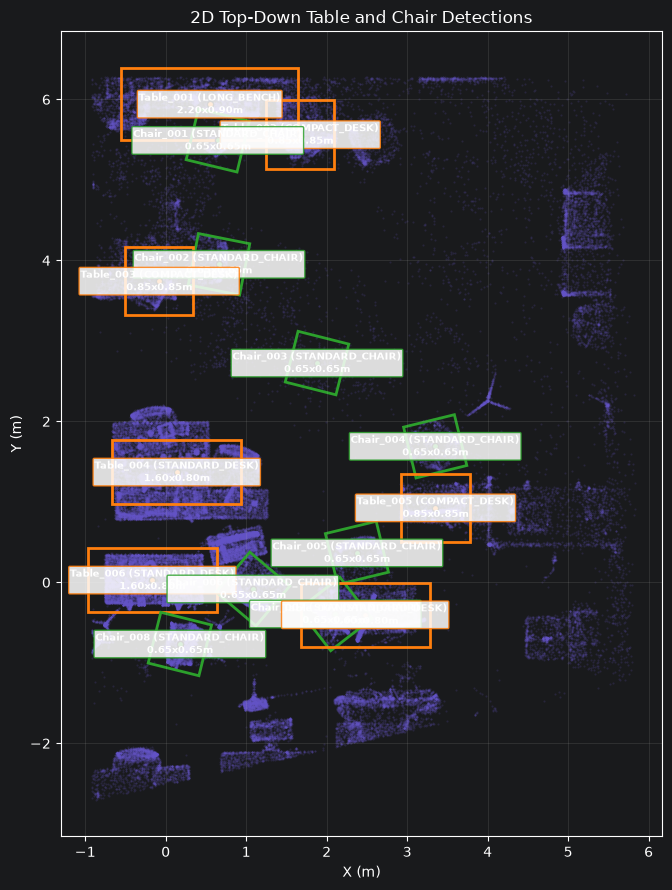

In [20]:
fig = visualize_detections(summary['oriented_valid_points'], records, title='2D Top-Down Table and Chair Detections')
plt.show()


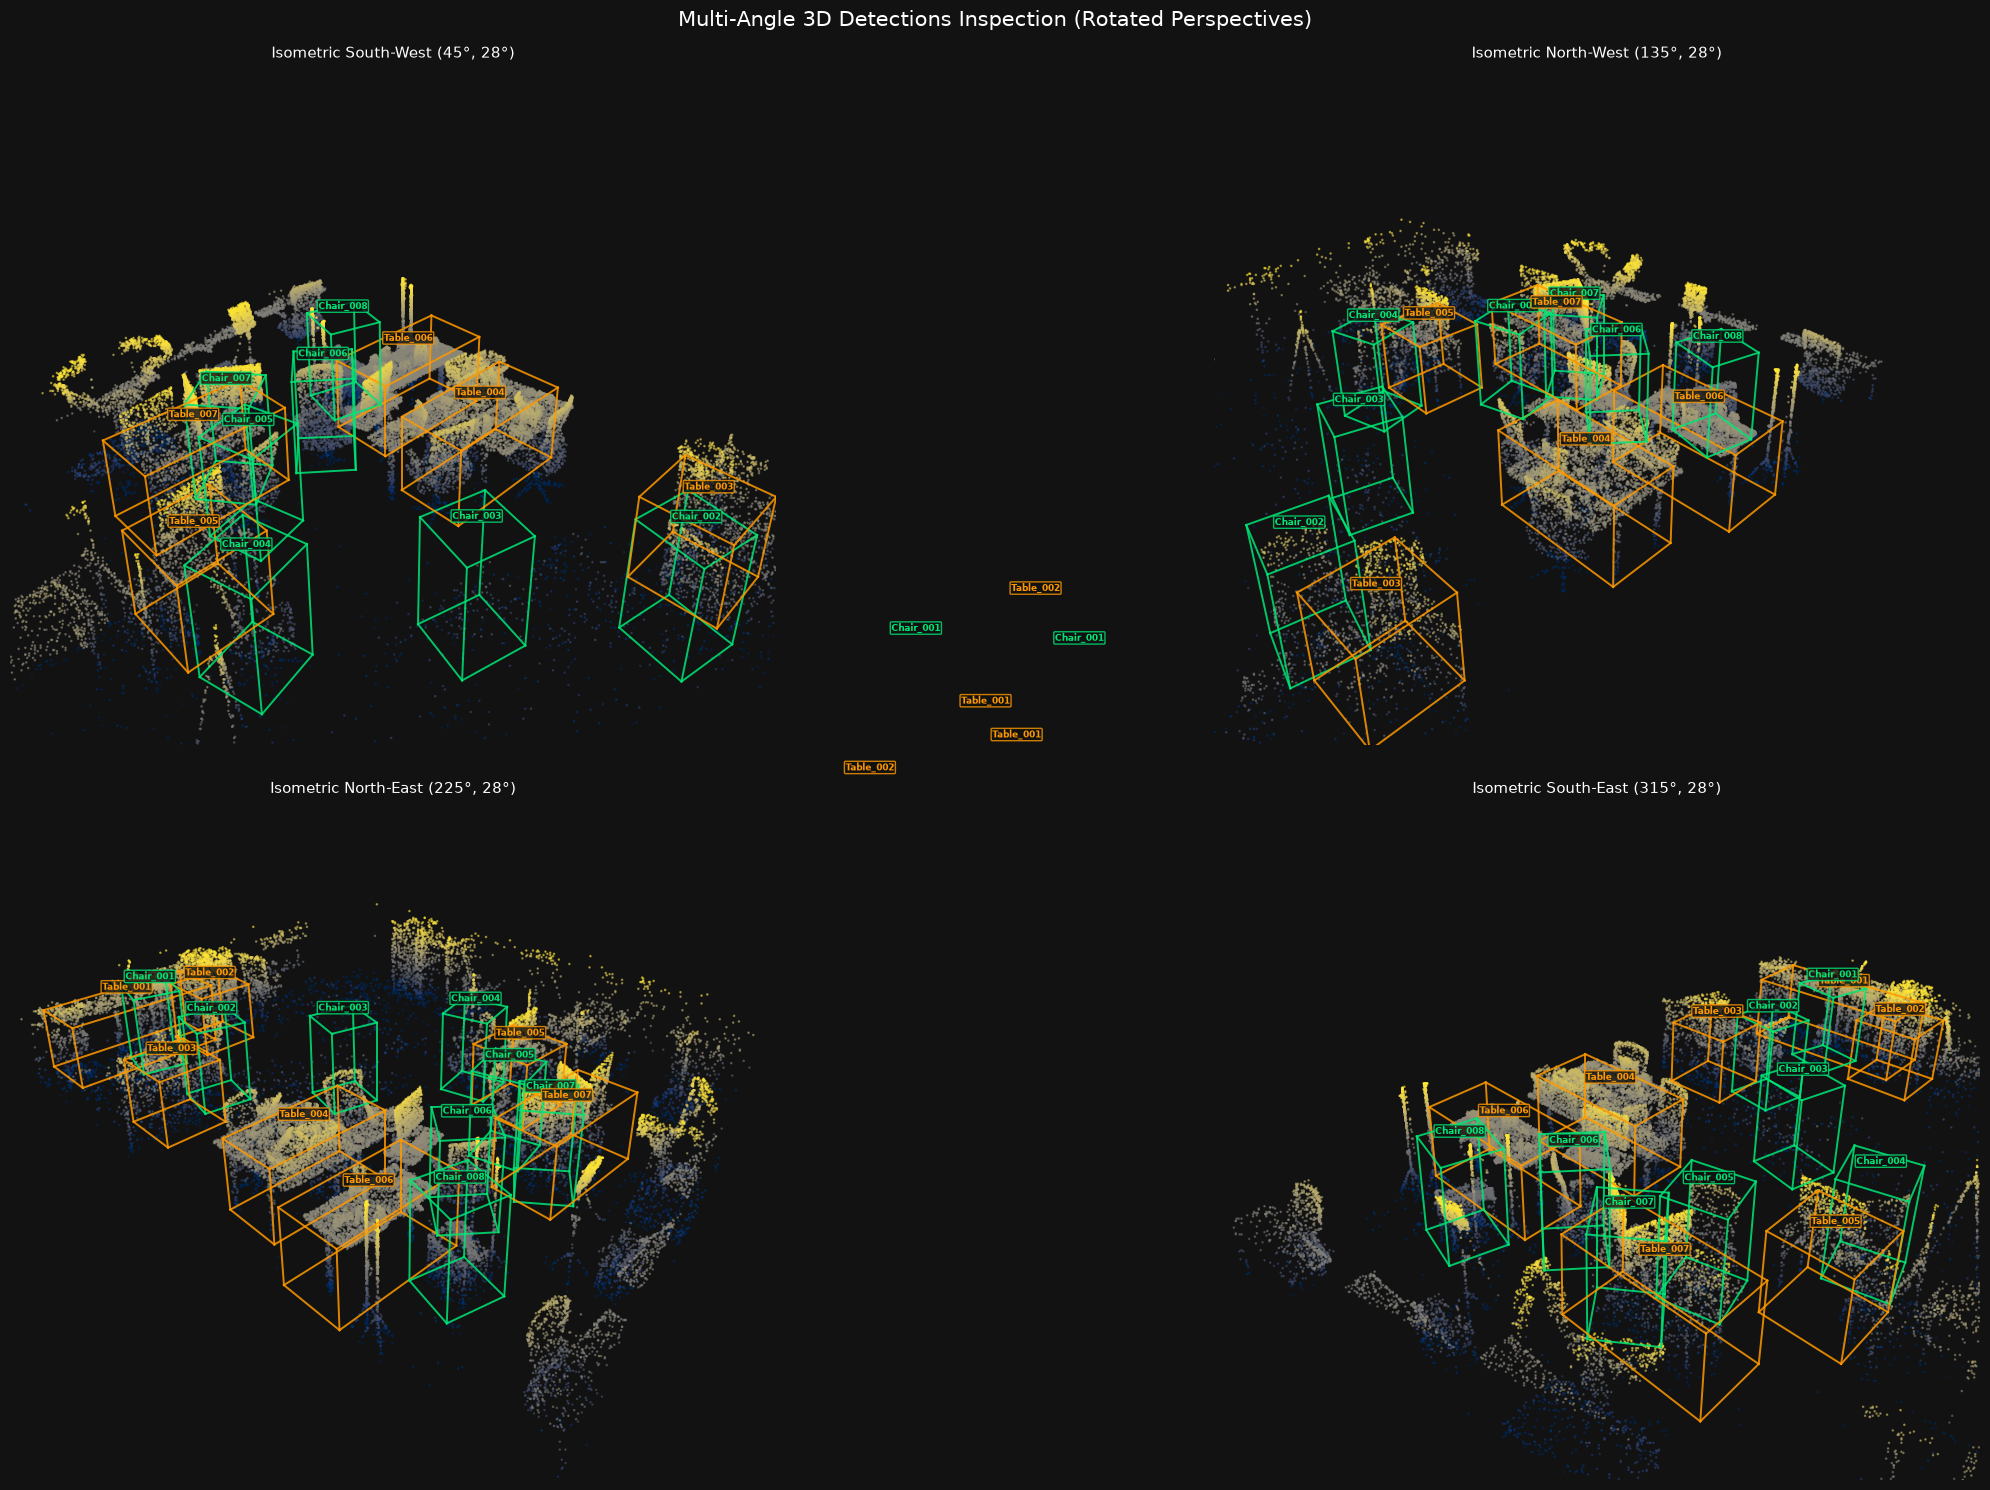

In [21]:
# Multi-angle 3D viewport inspection across 4 isometric camera perspectives
fig_multi = visualize_3d_multi_angle(
    summary['oriented_valid_points'], records,
    angles=[
        ('Isometric South-West', 45.0, 28.0),
        ('Isometric North-West', 135.0, 28.0),
        ('Isometric North-East', 225.0, 28.0),
        ('Isometric South-East', 315.0, 28.0),
    ],
    title='Multi-Angle 3D Detections Inspection (Rotated Perspectives)'
)
plt.show()


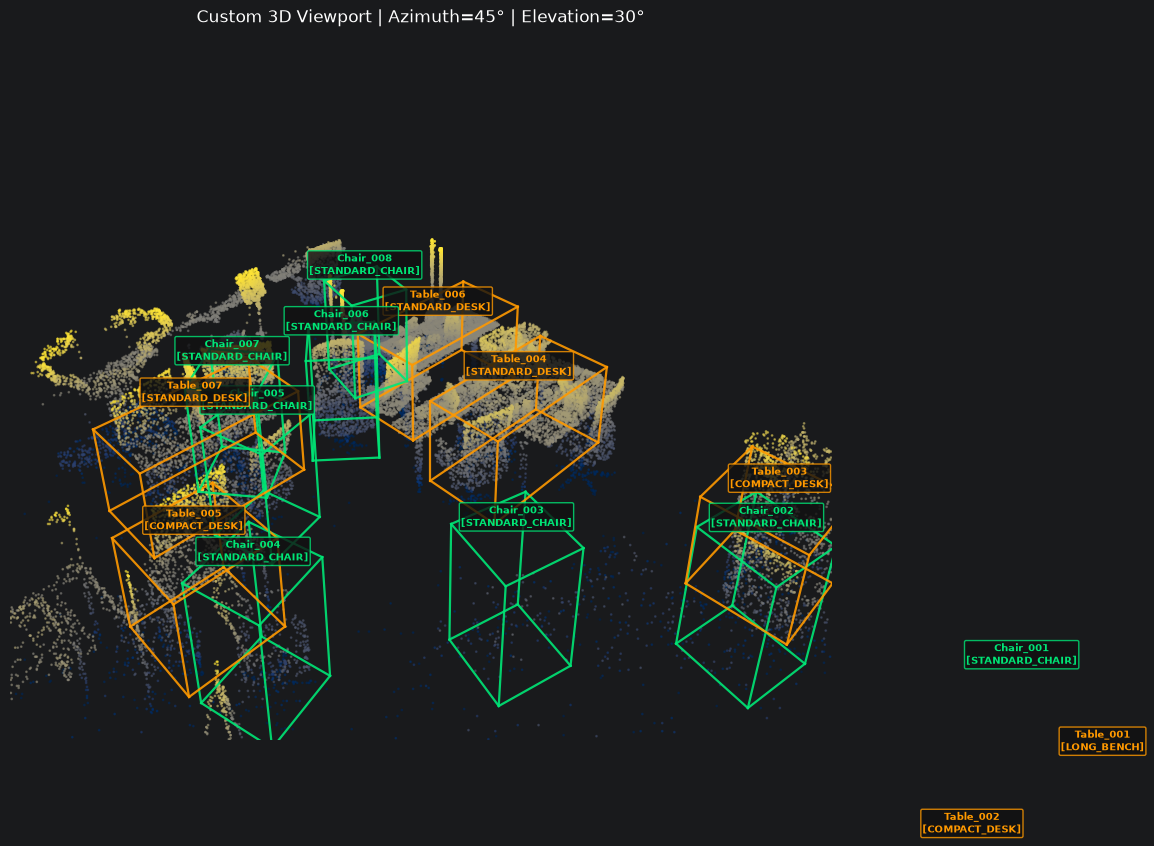

In [22]:
# Interactive 3D Viewport - Change azimuth (0-360°) and elevation (0-90°) to view from any custom angle
custom_azimuth = 45.0     # Horizontal rotation angle in degrees
custom_elevation = 30.0   # Vertical elevation angle in degrees
custom_zoom = 1.05        # Camera zoom factor

fig_3d = visualize_3d_viewport(
    summary['oriented_valid_points'], records,
    azimuth=custom_azimuth,
    elevation=custom_elevation,
    zoom=custom_zoom,
    title=f'Custom 3D Viewport | Azimuth={custom_azimuth:.0f}° | Elevation={custom_elevation:.0f}°'
)
plt.show()


In [23]:
counts = verification_df['class'].value_counts().to_dict() if not verification_df.empty else {}
print(f"Tables: {counts.get('TABLE', 0)}")
print(f"Chairs: {counts.get('CHAIR', 0)}")
display(verification_df) if 'display' in globals() else print(verification_df.to_string(index=False))


Tables: 7
Chairs: 8
object_id class  confidence  center_x  center_y  center_z  source_center_x  source_center_y  source_center_z  width  depth  height       validation_status issues      human_verification notes
Table_001 TABLE        0.95  0.546701  5.940747  0.490556         0.546701         5.940747         0.490556   2.20   0.90    0.75 PASSED_AUTOMATIC_CHECKS        PASSED_AUTOMATIC_CHECKS      
Table_002 TABLE        0.95  1.671203  5.561603  0.490556         1.671203         5.561603         0.490556   0.85   0.85    0.75 PASSED_AUTOMATIC_CHECKS        PASSED_AUTOMATIC_CHECKS      
Chair_001 CHAIR        0.95  0.646453  5.489925  0.590556         0.646453         5.489925         0.590556   0.65   0.65    0.95 PASSED_AUTOMATIC_CHECKS        PASSED_AUTOMATIC_CHECKS      
Chair_002 CHAIR        0.95  0.661996  3.951081  0.590556         0.661996         3.951081         0.590556   0.65   0.65    0.95 PASSED_AUTOMATIC_CHECKS        PASSED_AUTOMATIC_CHECKS      
Table_003 TABLE     

In [24]:
annotated_ply = config.output_dir / f"{config.input_path.stem}_annotated.ply"
print('Annotated PLY:', annotated_ply)
print('JSON metadata:', config.output_dir / 'table_chair_detections.json')
print('CSV review table:', config.output_dir / 'table_chair_detections.csv')
print('3D Bounding Box Mesh (OBJ):', config.output_dir / 'table_chair_bboxes.obj')
print('3D Material File (MTL):', config.output_dir / 'table_chair_bboxes.mtl')
print('Blender Turnkey Script:', config.output_dir / 'import_detections_to_blender.py')
print('Object PLYs directory:', config.output_dir / 'objects')


Annotated PLY: D:\GitHub\SceneForgeAI\output\ply_detection\labClean_annotated.ply
JSON metadata: D:\GitHub\SceneForgeAI\output\ply_detection\table_chair_detections.json
CSV review table: D:\GitHub\SceneForgeAI\output\ply_detection\table_chair_detections.csv
3D Bounding Box Mesh (OBJ): D:\GitHub\SceneForgeAI\output\ply_detection\table_chair_bboxes.obj
3D Material File (MTL): D:\GitHub\SceneForgeAI\output\ply_detection\table_chair_bboxes.mtl
Blender Turnkey Script: D:\GitHub\SceneForgeAI\output\ply_detection\import_detections_to_blender.py
Object PLYs directory: D:\GitHub\SceneForgeAI\output\ply_detection\objects
